# Fit of the VCA with magnetic end springs

Fits a nonlinear model to the chirp data in `data/train` and `data/test`

$$m\ddot{x} = \Gamma (x)\, i - c\,\dot{x} - F_s(x),$$

where $m$ is the shaft mass, $\Gamma(x)$ is the transduction coefficient, $i$ is the input current, $c$ is the friction, and $F_s$ is the restoring force exerted the magnets.

**Strategy.** 
1. Three methods are fitted. Method A and B use a cubic polynomial for the restoring force and a position dependent transduction coefficient. However, method B uses a quadratic transduction equation as given in the actuator datasheet. Method C uses an inverse cubic fit and assumes unequal magnets.
2. All methods are fitted using linear least squares as all models are linear in their parameters.

**Discrete-time model.** RK4 with $T_s$ = 1 ms (log at 2 kHz, every other sample kept) and zero-order-hold input. Predictions start from the measured $(x, \dot{x})$; models are compared on position NRMSE against prediction horizon.

In [ ]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import signal
from scipy.optimize import least_squares, lsq_linear

sns.set_theme(style="whitegrid")

FS_LOG, DECIM = 2000.0, 2
TS = 1/1000.0                       # discretization inter-sampling time
M = 51.5                            # kg
GAMMA0, C0 = 283.0, 1700.0          # datasheet; iteration
CMU0, G00 = 2.423, 22.3e-3          # PDF eq. 13; measured gap in experiment
s_ds = lambda x: (283 - 0.0198 * (x * 1e3) - 0.578 * (x * 1e3)**2) / 283   # datasheet K_f(z) shape, z in mm, 1 at the centre
LF_MAX, HF_MIN = 5.0, 37.0          # Hz; Low freq range and high freq range, ub and lb (37 Hz: above the 35.5 Hz laser-mount mode)
H_FIT, H_EVAL, STRIDE = 500, 500, 10 # steps for fitting the data
FOH = False                         # Zero-order hold
TAU = 0.65e-3                       # s, position is logged this much later than the commanded current (tuned on actual current: retune); undone in load
TAU_ACC = 2.65e-3                   # s, accelerometer is logged this much later than the commanded current (tuned on actual current: retune); undone in load
T_CUT = 5.0                         # s, end of each run left out of the HF band
ACC_SCALE_V_PER_G = 0.0578 * 0.65   # accelerometer V/g: plot-script 0.0578 corrected by the gain against position above 35 Hz (0.60-0.68)
F_MAX_A = 55.0                      # Hz, Methods A-C use the scheduled chirp up to this frequency (55 = whole run; 34 stays below the 35.5 Hz mode)

b_lp, a_lp = signal.butter(4, 100.0 / (FS_LOG / 2))   # 4th-order 100 Hz low-pass


def load(path):
    "Read one log; return filtered current, position and acceleration at 1 kHz (t >= 0), velocity, and band masks."
    # chirp start/end frequency and duration from the file name, e.g. ..._1.0to55.0Hz_120.0s_...
    m = re.search(r"_([\d.]+)to([\d.]+)Hz_([\d.]+)s_", path.name)
    f0, f1, T = map(float, m.groups()) if m else (np.nan,) * 3   # no chirp in the name (e.g. PRBS): band masks are empty
    raw = np.loadtxt(path, delimiter=",", skiprows=2)   # skip header and the duplicate first row
    lp = lambda s: signal.filtfilt(b_lp, a_lp, s)       # zero-phase, also the anti-alias filter for decimation
    # columns 0 time_s, 2 target_current_A (commanded, sent over EtherCAT), 11 position_mm, 12 ai2_corrected_V (bias removed in firmware)
    t = raw[:, 0]
    x = np.interp(t + TAU, t, lp(raw[:, 11] * 1e-3))   # shift position back by TAU to align it with the current
    for f_n in (50.0, 150.0):                           # mains pickup in the laser signal
        x = signal.filtfilt(*signal.iirnotch(f_n, 30.0, fs=FS_LOG), x)
    a = (np.interp(t + TAU_ACC, t, lp(raw[:, 12])) / ACC_SCALE_V_PER_G * 9.81 if raw.shape[1] > 12   # measured acceleration, shifted back by TAU_ACC
         else np.full(len(t), np.nan))                          # older logs have no ai2_corrected_V
    keep = slice(np.searchsorted(t, 0.0), None, DECIM)  # drop the t < 0 idle window, 2 kHz -> 1 kHz
    d = dict(t=t[keep], i=lp(raw[:, 2])[keep], x=x[keep], a_meas=a[keep])
    d["v"] = np.gradient(d["x"], TS)                    # velocity: initial states and LLS
    d["a_x"] = np.gradient(d["v"], TS)                  # acceleration from position
    d["a"] = d["a_x"]                                   # fits use position-derived acceleration; accelerometer only plotted
    f = f0 * (f1 / f0) ** (d["t"] / T)                  # instantaneous frequency of the exponential chirp
    d["lf"] = f <= LF_MAX                               # old low band, used by methods B-D
    d["hf"] = (f >= HF_MIN) & (d["t"] <= d["t"][-1] - T_CUT)
    d["sweep"] = f <= F_MAX_A                           # Methods A-C window: scheduled chirp from its start up to F_MAX_A
    return d


def step(x, v, u0, u1, acc, ts=TS):
    "One RK4 step, length ts, of (x, v) with input u0 at the start and u1 at the end of the step."
    um = 0.5 * (u0 + u1)
    k1x, k1v = v, acc(x, v, u0)
    k2x, k2v = v + ts / 2 * k1v, acc(x + ts / 2 * k1x, v + ts / 2 * k1v, um)
    k3x, k3v = v + ts / 2 * k2v, acc(x + ts / 2 * k2x, v + ts / 2 * k2v, um)
    k4x, k4v = v + ts * k3v, acc(x + ts * k3x, v + ts * k3v, u1)
    return x + ts / 6 * (k1x + 2 * k2x + 2 * k3x + k4x), v + ts / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)


def rollout(Fs, p, d, s, H):
    "Predicted x, shape (len(s), H+1), from the measured state at each start index s. p = [Gamma, c, *spring]."
    acc = lambda x, v, u: (p[0] * u - p[1] * v - Fs(x, u, p[2:])) / M      # Fs gets the current too, for Gamma(x)
    x, v, out = d["x"][s], d["v"][s], [d["x"][s]]
    with np.errstate(all="ignore"):
        for k in range(H):
            u0 = d["i"][s + k]
            x, v = step(x, v, u0, d["i"][s + k + 1] if FOH else u0, acc)
            out.append(x)
    return np.stack(out, axis=1)


def starts(d, band, H):
    "Every STRIDE-th sample of the band whose H-step horizon fits in the record."
    s = np.flatnonzero(band)[::STRIDE]
    return s[s + H < len(d["x"])]


def target(d, s, H):
    "Measured x over the horizon of each start, shape (len(s), H+1)."
    return d["x"][s[:, None] + np.arange(H + 1)]


def fit(Fs, p0, d, band, lb=-np.inf, free=slice(None), detrend=False):
    "H-step-ahead fit of p0[free]; detrend removes per-start mean and slope of the error (free-mass drift)."
    s = starts(d, band, H_FIT)
    X = target(d, s, H_FIT)[:, 1:]
    p = np.array(p0, float)
    def res(q):
        p[free] = q
        e = np.nan_to_num(rollout(Fs, p, d, s, H_FIT)[:, 1:], nan=1.0, posinf=1.0, neginf=-1.0) - X   # diverged rollout -> 1 m
        return (signal.detrend(e, axis=1) if detrend else e).ravel()
    r = least_squares(res, p[free], x_scale=np.abs(p[free]), bounds=(lb, np.inf))
    p[free] = r.x
    print(f"{r.message} ({r.nfev} evaluations)")
    return p


def nrmse_curve(Fs, p, d, band, H=H_EVAL):
    "Position RMS error per horizon step, normalised by the std of x in the band."
    s = starts(d, band, H)
    e = rollout(Fs, p, d, s, H) - target(d, s, H)
    return np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][band])


CURVES = []

def evaluate(name, Fs, p, exp, band, H=H_EVAL):
    "Left: NRMSE against horizon, train and test. Right: one H-step prediction on test, started mid-band."
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    k = np.arange(1, H + 1)
    for split, d in DATA[exp].items():
        e = nrmse_curve(Fs, p, d, d[band], H)[1:]
        CURVES.append(dict(method=name, split=split, exp=exp, band=band, k=k, nrmse=e))   # kept for the comparison cell
        sns.lineplot(x=k, y=e, ax=ax[0], label=split)
        print(f"{split:5s} NRMSE at k = 1, 10, 100, {H}: " + ", ".join(f"{e[j - 1]:.3f}" for j in (1, 10, 100, H)))
    ax[0].set(xscale="log", xlabel="steps ahead (1 step = 1 ms)", ylabel="position NRMSE", title=f"{name}, {band.upper()} band")
    d = DATA[exp]["test"]
    s0 = starts(d, d[band], H)
    s0 = s0[len(s0) // 2:][:1]                          # one start in the middle of the band
    t = d["t"][s0[0]:s0[0] + H + 1]
    sns.lineplot(x=t, y=target(d, s0, H)[0] * 1e3, ax=ax[1], label="measured", color="k")
    sns.lineplot(x=t, y=rollout(Fs, p, d, s0, H)[0] * 1e3, ax=ax[1], label="predicted")
    ax[1].set(xlabel="time (s)", ylabel="x (mm)", title=f"test: {H}-step prediction from the measured state")
    plt.tight_layout(); plt.show()


# self-check: undamped linear spring from x = 1 mm must follow cos(wt)
_k = 1e5
_d = dict(x=np.full(2, 1e-3), v=np.zeros(2), i=np.zeros(1000))
_x = rollout(lambda x, u, q: q[0] * x, [0.0, 0.0, _k], _d, np.array([0]), 900)[0]
assert np.allclose(_x, 1e-3 * np.cos(np.sqrt(_k / M) * TS * np.arange(901)), atol=1e-8)

## Stage 0: data

Two experiment types per split, from `data/train` and `data/test`:
- `chirp`: plain chirp, 1→55 Hz, not fitted: used for validation, the Kalman filter and the spectral analysis.
- `chirpsched`: chirp 10→55 Hz with amplitude ramps, for Methods A-C (band `sweep`: from the start up to `F_MAX_A` Hz).

The 3 s idle window (t < 0) is dropped; position is notched at 50 and 150 Hz (mains pickup in the laser). The fits use the position-derived acceleration; the bias-corrected accelerometer `ai2_corrected_V` is only plotted for comparison.

chirp      train a_meas / a_from_x = 1.142
chirp      test  a_meas / a_from_x = 1.106
chirpsched train a_meas / a_from_x = 1.225
chirpsched test  a_meas / a_from_x = 1.242


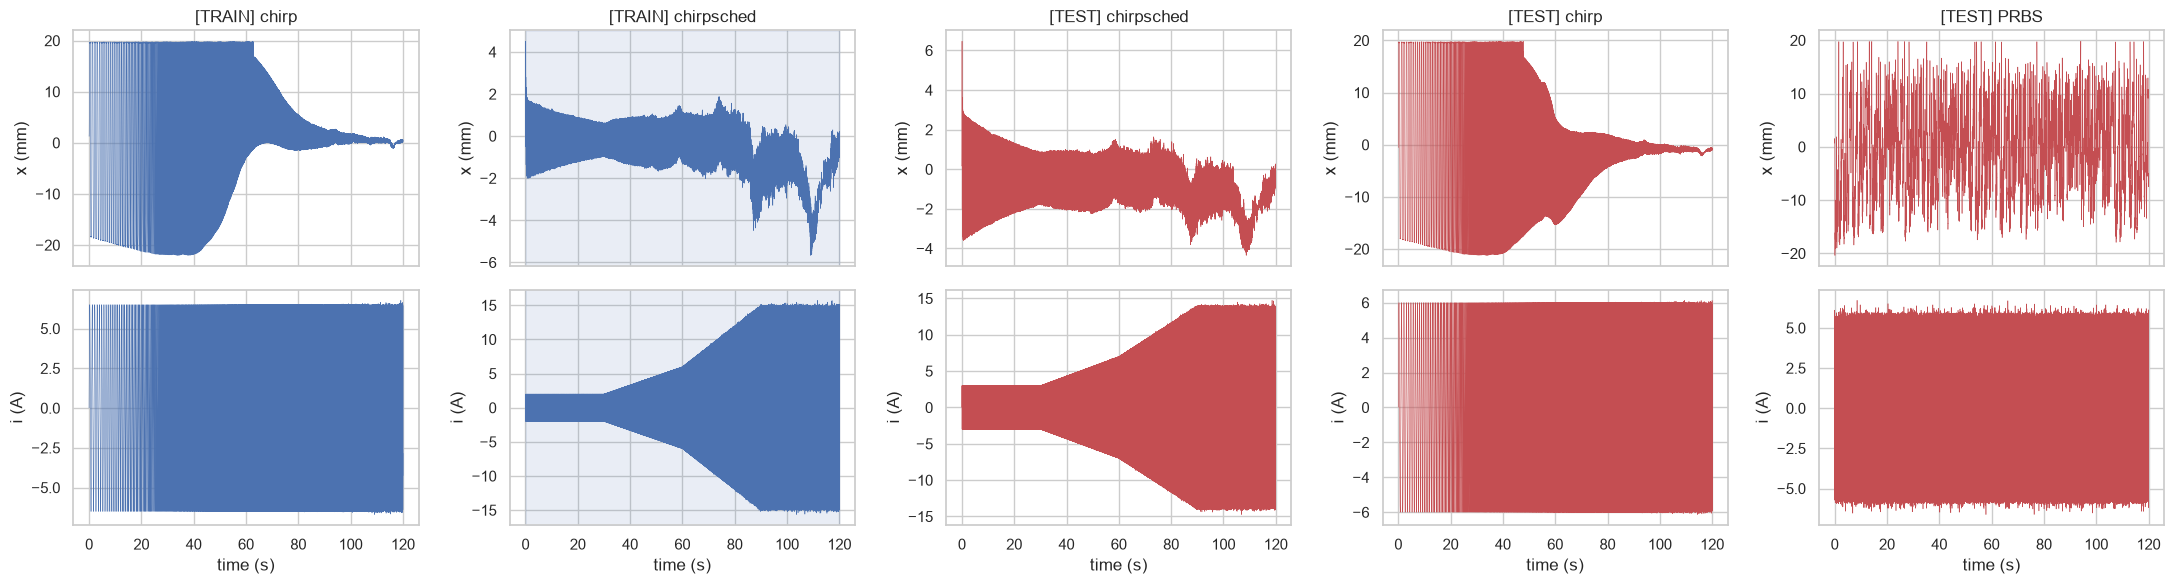

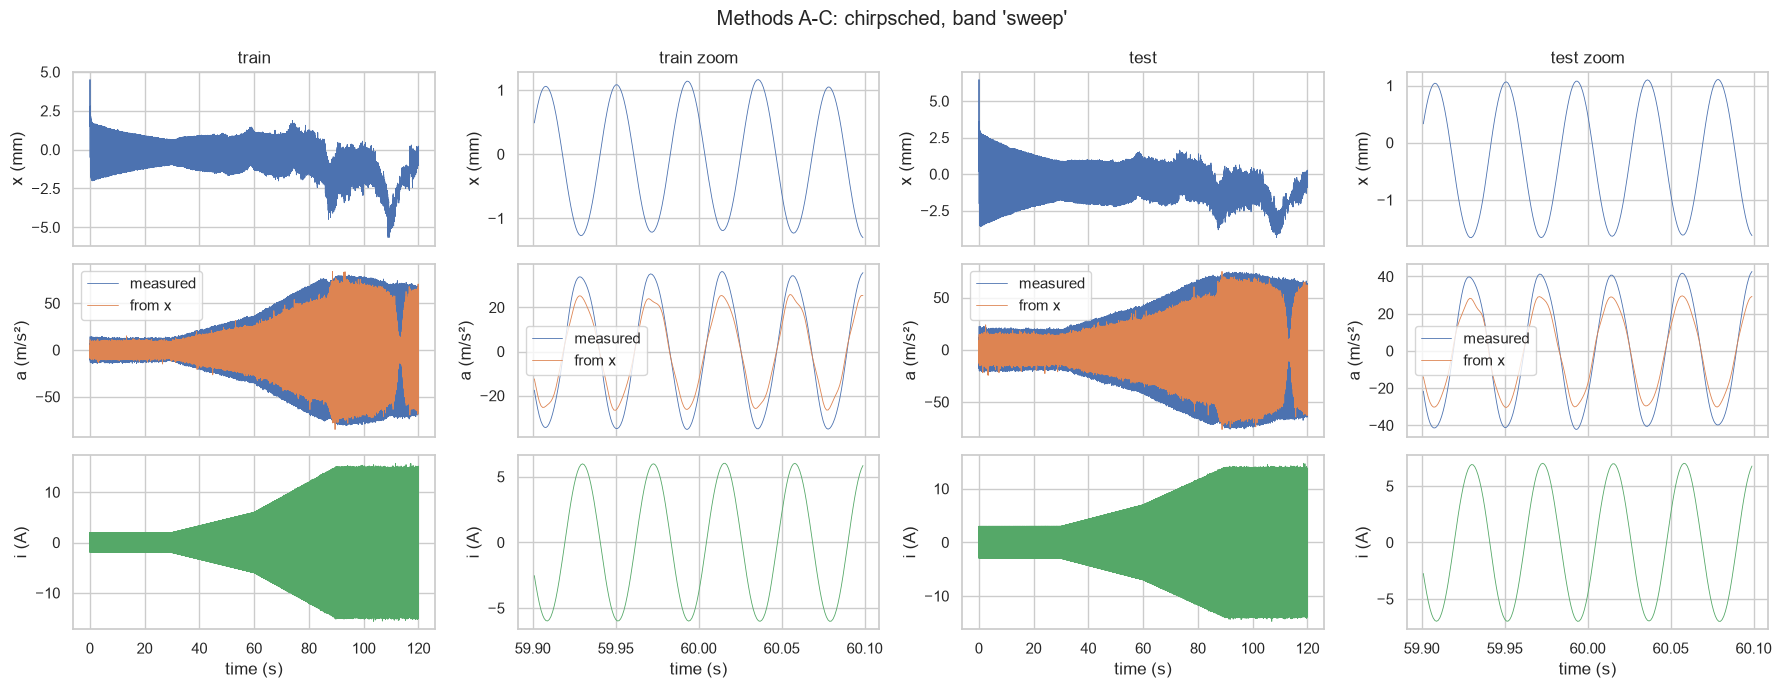

In [ ]:
DATA = {exp: {s: load(next(Path("data", s).glob(f"voice_coil_log_{exp}_*.csv"))) for s in ("train", "test")}
        for exp in ("chirp", "chirpsched")}
USE = [("Methods A-C", "chirpsched", "sweep")]

# accelerometer scale check: slope of measured against position-derived acceleration, 1.0 if ACC_SCALE_V_PER_G is right
for exp, runs in DATA.items():
    for split, d in runs.items():
        m = d["hf"] | d["sweep"] if exp == "chirpsched" else d["hf"]
        print(f"{exp:10s} {split:5s} a_meas / a_from_x = {np.polyfit(d['a_x'][m], d['a_meas'][m], 1)[0]:.3f}")

# overview: position (top) and current (bottom) of every run, TRAIN in blue, TEST in red; shaded: the window the fit uses
SETS = [("TRAIN", "chirp", DATA["chirp"]["train"], None),            # (role, name, data, band used by the fit): not fitted, spectral analysis
        ("TRAIN", "chirpsched", DATA["chirpsched"]["train"], "sweep"),  # Methods A-C
        ("TEST", "chirpsched", DATA["chirpsched"]["test"], None),       # validation, Kalman filter
        ("TEST", "chirp", DATA["chirp"]["test"], None),                 # validation, Kalman filter
        ("TEST", "PRBS", load(next(Path("data").glob("voice_coil_log_prbs_*.csv"))), None)]   # validation (23 Sep, +-16 mm: extrapolation)
fig, ax = plt.subplots(2, len(SETS), figsize=(22, 6), sharex="col")
for col, (role, name, d, band) in enumerate(SETS):
    color = "C0" if role == "TRAIN" else "C3"
    sns.lineplot(x=d["t"], y=d["x"] * 1e3, ax=ax[0, col], lw=0.4, color=color).set(title=f"[{role}] {name}", ylabel="x (mm)")
    sns.lineplot(x=d["t"], y=d["i"], ax=ax[1, col], lw=0.4, color=color).set(xlabel="time (s)", ylabel="i (A)")
    if band:
        for a_ in ax[:, col]:
            a_.fill_between(d["t"], 0, 1, where=d[band], transform=a_.get_xaxis_transform(), color=color, alpha=0.12)
plt.tight_layout(); plt.show()

# data actually used, one figure per fit: rows position, acceleration, current;
# columns train (whole window, zoom), test (whole window, zoom). The zoom shows a few cycles mid-window to judge delays.
ZOOM_S = 0.2                                            # s, length of the zoom window
for stage, exp, band in USE:
    fig, ax = plt.subplots(3, 4, figsize=(18, 7), sharex="col")
    for k, (split, d) in enumerate(DATA[exp].items()):
        idx = np.flatnonzero(d[band])
        t_mid = d["t"][idx[len(idx) // 2]]
        for col, m in [(2 * k, d[band]), (2 * k + 1, d[band] & (np.abs(d["t"] - t_mid) <= ZOOM_S / 2))]:
            t = d["t"][m]
            sns.lineplot(x=t, y=d["x"][m] * 1e3, ax=ax[0, col], lw=0.6).set(title=f"{split}{' zoom' if col % 2 else ''}", ylabel="x (mm)")
            sns.lineplot(x=t, y=d["a_meas"][m], ax=ax[1, col], lw=0.6, label="measured")
            sns.lineplot(x=t, y=d["a_x"][m], ax=ax[1, col], lw=0.6, label="from x").set(ylabel="a (m/s²)")
            sns.lineplot(x=t, y=d["i"][m], ax=ax[2, col], lw=0.6, color="C2").set(xlabel="time (s)", ylabel="i (A)")
    fig.suptitle(f"{stage}: {exp}, band '{band}'"); plt.tight_layout(); plt.show()

## Spectral analysis of the plain chirp (raw position)

Raw position of the plain chirp only (`SPLIT` = train or test), read straight from the CSV at the logged 2 kHz (Nyquist 1 kHz): no low-pass, no 50/150 Hz notch, no delay shift, no decimation. Shown up to `F_SHOW` = 300 Hz. Left: spectrogram (short-time Fourier transform, Hann window), frequency against time, which should show the chirp's rising line. Right: Welch PSD (averaged FFT periodograms) in dB.

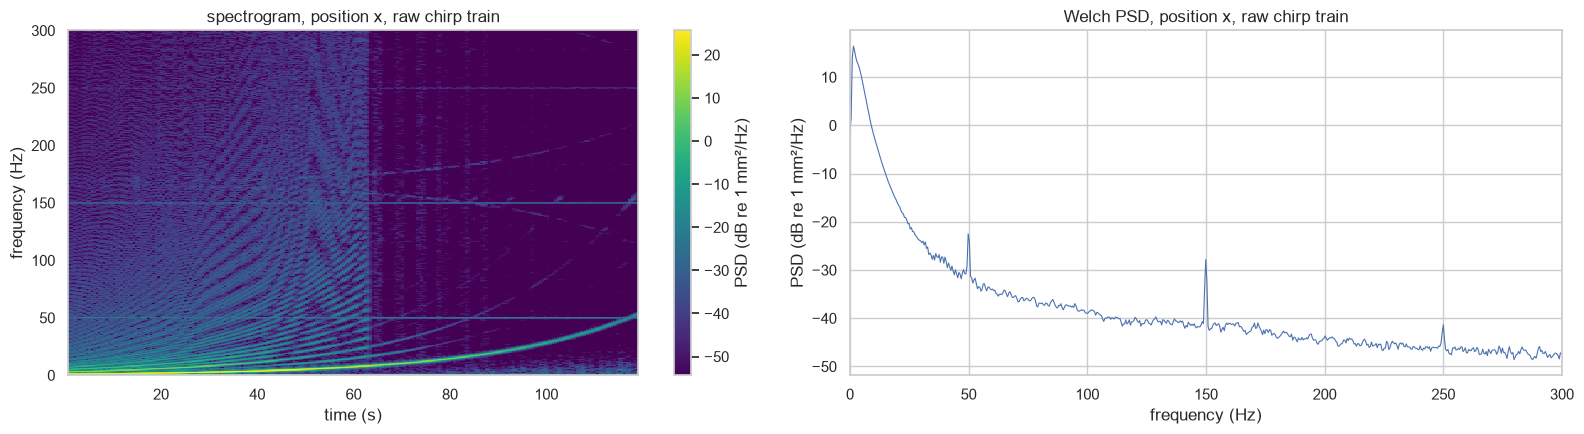

In [ ]:
SPLIT = "train"                                         # "train" or "test"
NFFT = 4096                                             # samples per segment: 2.05 s at 2 kHz, 0.49 Hz resolution
F_SHOW = 300.0                                          # Hz, upper plot limit (Nyquist of the raw log is 1 kHz)
path = next(Path("data", SPLIT).glob("voice_coil_log_chirp_*.csv"))   # plain chirp only (chirpsched_ does not match)
raw = np.loadtxt(path, delimiter=",", skiprows=2)       # raw 2 kHz log: no low-pass, no notch, no delay shift, no decimation
x_raw = raw[raw[:, 0] >= 0.0, 11]                       # position_mm, t < 0 idle window dropped

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
f, t, S = signal.spectrogram(x_raw, fs=FS_LOG, window="hann", nperseg=NFFT, noverlap=NFFT * 3 // 4, detrend="constant", scaling="density")
S_db = 10 * np.log10(S[f <= F_SHOW] + 1e-20)            # colour scale from the shown band only
im = ax[0].pcolormesh(t, f[f <= F_SHOW], S_db, shading="auto", cmap="viridis", vmin=S_db.max() - 80, vmax=S_db.max())
ax[0].set(ylim=(0, F_SHOW), xlabel="time (s)", ylabel="frequency (Hz)", title=f"spectrogram, position x, raw chirp {SPLIT}")
fig.colorbar(im, ax=ax[0], label="PSD (dB re 1 mm²/Hz)")
f, P = signal.welch(x_raw, fs=FS_LOG, window="hann", nperseg=NFFT, noverlap=NFFT // 2, detrend="constant", scaling="density")
sns.lineplot(x=f[f <= F_SHOW], y=10 * np.log10(P[f <= F_SHOW] + 1e-20), ax=ax[1], lw=0.8)   # y-axis autoscales to the shown band
ax[1].set(xlim=(0, F_SHOW), xlabel="frequency (Hz)", ylabel="PSD (dB re 1 mm²/Hz)", title=f"Welch PSD, position x, raw chirp {SPLIT}")
plt.tight_layout(); plt.show()

## Method A: cubic spring, LLS

Polynomial spring with an even term for asymmetry, fitted by bounded linear least squares on the scheduled chirp up to `F_MAX_A` Hz. Each row is divided by the local current amplitude, so the high-current end does not dominate.

$$m\ddot{x} = (\Gamma\,+\,\Gamma_1 x)\, i - c\,\dot{x} - (k_1 x + k_2 x^2 + k_3 x^3)$$

$\Gamma$ and $c$ are fitted together with the spring ($c \geq 0$).

Option (set in the first line of the cell):
- `GAMMA_X = False`: constant motor constant $\Gamma$.
- `GAMMA_X = True`: position-dependent motor constant $\Gamma(x) = \Gamma + \Gamma_1 x$.

Always: $k_3 \geq 0$, so the spring hardens with stroke and keeps its restoring force outside the fitted range.

In [ ]:
GAMMA_X = True                                          # position-dependent Gamma(x) = Gamma + Gamma1 x
poly3 = lambda x, u, q: q[-3] * x + q[-2] * x**2 + q[-1] * x**3 - (q[0] * x * u if GAMMA_X else 0.0)   # q = [Gamma1,] k1, k2, k3
d, sel = DATA["chirpsched"]["train"], DATA["chirpsched"]["train"]["sweep"]
x, i, v = d["x"][sel], d["i"][sel], d["v"][sel]
w = 1 / np.abs(signal.hilbert(d["i"]))[sel]                          # 1 / current amplitude, so every part of the sweep counts about equally
cols = {"Gamma": i, "c": -v, **({"Gamma1": x * i} if GAMMA_X else {}),   # m a = Gamma i - c v [+ Gamma1 x i] - (k1 x + k2 x^2 + k3 x^3)
        "k1": -x, "k2": -x**2, "k3": -x**3}
y = M * d["a"][sel]
A = np.column_stack(list(cols.values()))
lb = [0.0 if n in ("c", "k3") else -np.inf for n in cols]           # c >= 0; k3 >= 0: hardening spring
sc = np.linalg.norm(A * w[:, None], axis=0)                          # column scaling
q = dict(zip(cols, lsq_linear(A * w[:, None] / sc, y * w, bounds=(lb, np.inf)).x / sc))
G, c = q.pop("Gamma"), q.pop("c")
p_p3 = np.r_[G, c, list(q.values())]
print(f"Gamma = {G:.1f} N/A, c = {c:.1f} N s/m; " + ", ".join(f"{n} = {val:.4g}" for n, val in q.items()))
if GAMMA_X:
    print("Gamma(x)/Gamma at -5, +5 mm: " + ", ".join(f"{1 + q['Gamma1'] * xx / G:.3f}" for xx in (-5e-3, 5e-3)))

Gamma = 202.0 N/A, c = 1593.6 N s/m; Gamma1 = 4648, k1 = 3.613e+04, k2 = -3.012e+06, k3 = 8.742e-07
Gamma(x)/Gamma at -5, +5 mm: 0.885, 1.115


train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.206, 0.772, 0.694
test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.190, 0.629, 0.572


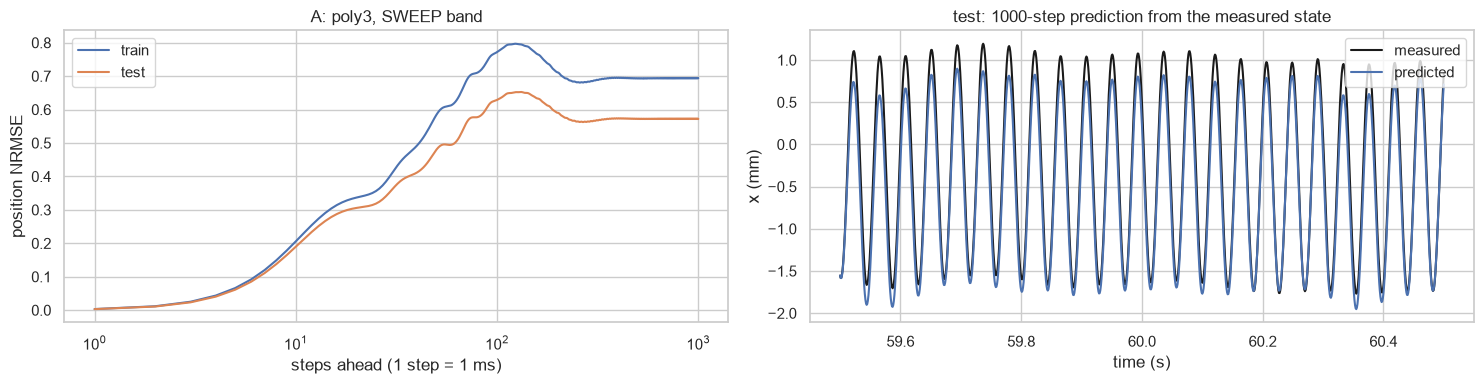

In [ ]:
evaluate("A: poly3", poly3, p_p3, "chirpsched", "sweep", H=1000)

## Method B: cubic spring with the datasheet motor constant shape, LLS

Method A's model, but the motor constant follows the shape of the actuator datasheet curve, $K_f(z) = 283 - 0.0198\,z - 0.578\,z^2$ (N/A, $z$ in mm). Only its scale $\Gamma_0$ is fitted, so the motor term cannot take over the role of the spring. Same data and weighting as Method A.

$$m\ddot{x} = \Gamma_0\, s(x)\, i - c\,\dot{x} - (k_1 x + k_2 x^2 + k_3 x^3), \qquad s(x) = \frac{K_f(x)}{283} \;(= 1 \text{ at the centre})$$

$\Gamma_0$ and $c$ are fitted together with the spring ($c \geq 0$). Always: the datasheet shape $s(x)$, and $k_3 \geq 0$, so the spring hardens with stroke.

In [ ]:
d, sel = DATA["chirpsched"]["train"], DATA["chirpsched"]["train"]["sweep"]
x, i, v = d["x"][sel], d["i"][sel], d["v"][sel]
w = 1 / np.abs(signal.hilbert(d["i"]))[sel]                          # 1 / current amplitude, so every part of the sweep counts about equally
cols = {"Gamma0": i * s_ds(x), "c": -v, "k1": -x, "k2": -x**2, "k3": -x**3}   # m a = Gamma0 s(x) i - c v - (k1 x + k2 x^2 + k3 x^3)
y = M * d["a"][sel]
A = np.column_stack(list(cols.values()))
lb = [0.0 if n in ("c", "k3") else -np.inf for n in cols]           # c >= 0; k3 >= 0: hardening spring
sc = np.linalg.norm(A * w[:, None], axis=0)                          # column scaling
q = dict(zip(cols, lsq_linear(A * w[:, None] / sc, y * w, bounds=(lb, np.inf)).x / sc))
G0, c = q.pop("Gamma0"), q.pop("c")
p_B = np.r_[G0, c, list(q.values())]
poly3_ds = lambda x, u, q, G0=G0: q[0] * x + q[1] * x**2 + q[2] * x**3 + G0 * (1 - s_ds(x)) * u   # spring, plus Gamma0 (1 - s(x)) i so the motor force is Gamma0 s(x) i
print(f"Gamma0 = {G0:.1f} N/A, c = {c:.1f} N s/m; " + ", ".join(f"{n} = {val:.4g}" for n, val in q.items()))
print("Gamma(x)/Gamma0 at -5, +5 mm (datasheet shape): " + ", ".join(f"{s_ds(xx):.3f}" for xx in (-5e-3, 5e-3)))

Gamma0 = 199.2 N/A, c = 1574.7 N s/m; k1 = 4.094e+04, k2 = 2.329e+06, k3 = 8.177e-07
Gamma(x)/Gamma0 at -5, +5 mm (datasheet shape): 0.949, 0.949


train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.208, 0.849, 0.910
test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.192, 0.771, 0.797


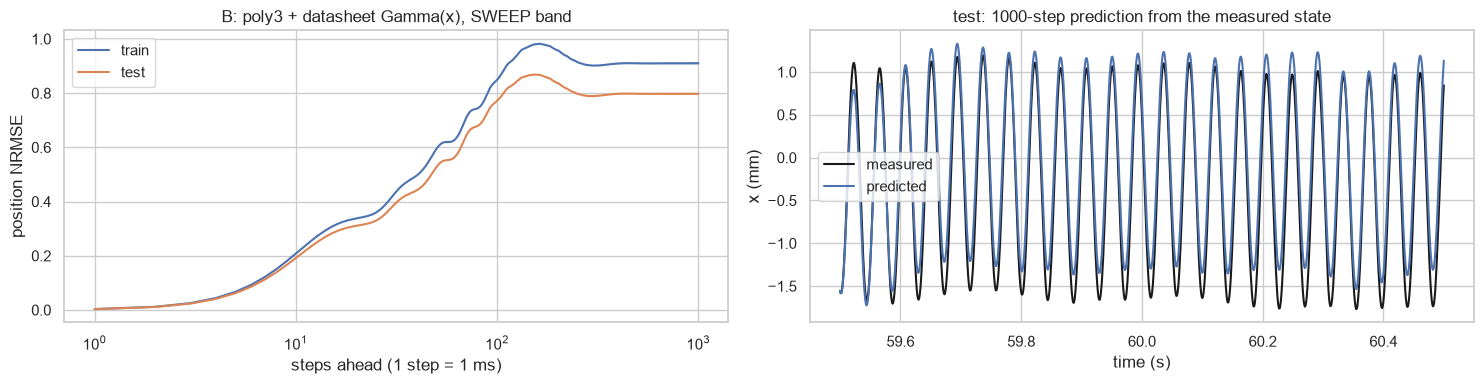

In [ ]:
evaluate("B: poly3 + datasheet Gamma(x)", poly3_ds, p_B, "chirpsched", "sweep", H=1000)

## Method C: unequal magnets with a position-dependent motor constant, LLS

Two repelling magnets with their own strength, $C_R, C_L \geq 0$ (PDF eq. 3 with $Q_R \neq Q_L$): each always repels, and the net spring always restores and stiffens with stroke. $C_R \neq C_L$ gives the asymmetry. The gap is fixed at the measured $g_0$ = `G00` = 22.3 mm, so the model is linear in $C_R, C_L$. The motor constant is linear in position, $\Gamma(x) = \Gamma + \Gamma_1 x$, as in Method A, with $\Gamma_1$ fitted. Same data and weighting as Method A.

$$m\ddot{x} = (\Gamma + \Gamma_1 x)\, i - c\,\dot{x} - \left(\frac{C_R}{(g_0 - x)^3} - \frac{C_L}{(g_0 + x)^3}\right)$$

$\Gamma$, $c$, $\Gamma_1$, $C_R$ and $C_L$ are fitted together ($c \geq 0$). Always: $g_0$ = 22.3 mm, and $C_R, C_L \geq 0$.

In [ ]:
d, sel = DATA["chirpsched"]["train"], DATA["chirpsched"]["train"]["sweep"]
x, i, v = d["x"][sel], d["i"][sel], d["v"][sel]
w = 1 / np.abs(signal.hilbert(d["i"]))[sel]                          # 1 / current amplitude, so every part of the sweep counts about equally
cols = {"Gamma": i, "c": -v, "Gamma1": x * i, "C_R": -1 / (G00 - x)**3, "C_L": 1 / (G00 + x)**3}   # m a = (Gamma + Gamma1 x) i - c v - (C_R / (g0 - x)^3 - C_L / (g0 + x)^3)
y = M * d["a"][sel]
A = np.column_stack(list(cols.values()))
lb = [-np.inf if n in ("Gamma", "Gamma1") else 0.0 for n in cols]   # c, C_R, C_L >= 0
sc = np.linalg.norm(A * w[:, None], axis=0)                          # column scaling
q = dict(zip(cols, lsq_linear(A * w[:, None] / sc, y * w, bounds=(lb, np.inf)).x / sc))
G, c, G1, C_R, C_L = q.values()
p_C = np.r_[G, c, G1, C_R, C_L]
magnets = lambda x, u, q: q[1] / (G00 - x)**3 - q[2] / (G00 + x)**3 - q[0] * x * u   # magnets, minus Gamma1 x i so the motor force is (Gamma + Gamma1 x) i
print(f"Gamma = {G:.1f} N/A, c = {c:.1f} N s/m; Gamma1 = {G1:.4g} N/(A m); C_R = {C_R:.4g} N m^3, C_L = {C_L:.4g} N m^3 "
      f"(C_R / C_L = {C_R / C_L:.3f}; PDF guess C_mu = {CMU0} N m^2)")
print(f"stiffness at x = 0: {3 * (C_R + C_L) / G00**4:.3g} N/m, force at x = 0: {(C_R - C_L) / G00**3:.3g} N")   # dF/dx = 3 C_R / (g0 - x)^4 + 3 C_L / (g0 + x)^4
print("Gamma(x)/Gamma at -5, +5 mm: " + ", ".join(f"{1 + G1 * xx / G:.3f}" for xx in (-5e-3, 5e-3)))

Gamma = 200.9 N/A, c = 1586.3 N s/m; Gamma1 = 3573 N/(A m); C_R = 0.001604 N m^3, C_L = 0.001574 N m^3 (C_R / C_L = 1.019; PDF guess C_mu = 2.423 N m^2)
stiffness at x = 0: 3.86e+04 N/m, force at x = 0: 2.65 N
Gamma(x)/Gamma at -5, +5 mm: 0.911, 1.089


train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.206, 0.760, 0.710
test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.190, 0.616, 0.577


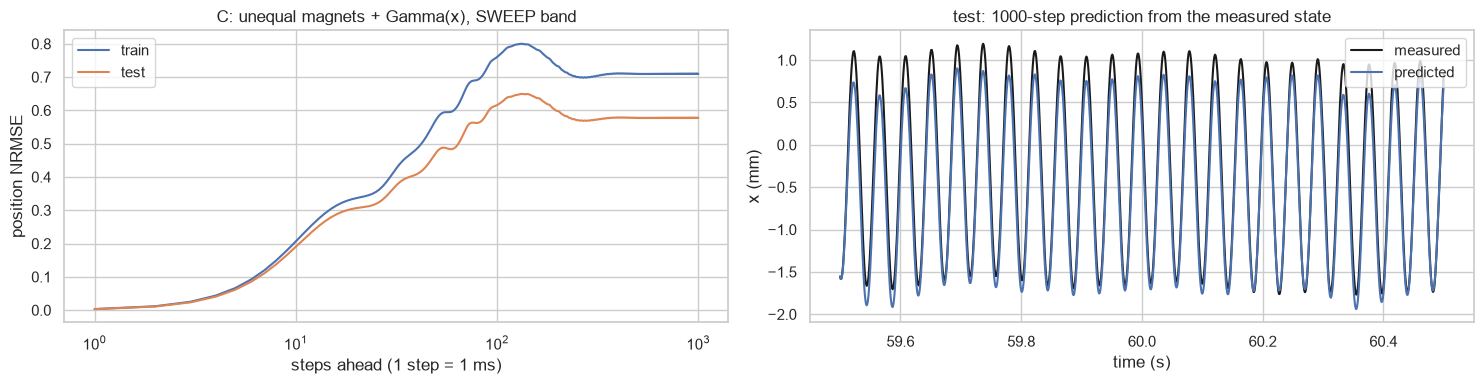

In [ ]:
evaluate("C: unequal magnets + Gamma(x)", magnets, p_C, "chirpsched", "sweep", H=1000)

## Why Model D: what Model C leaves unexplained

The moving mass runs on an **air bearing** with nothing attached, so sliding (Coulomb) friction is not expected; the dissipation is air-film shear and eddy currents. Before choosing Model D's terms, this section looks at the force that Model C does not explain on the scheduled chirp (sweep band), with the commanded current `target_current_A` as input, as in Method C:

$$r_k = m\,\ddot{x}_k - \left[(\Gamma + \Gamma_1 x_k)\, i_k - c\,\dot{x}_k - \left(\frac{C_R}{(g_0 - x_k)^3} - \frac{C_L}{(g_0 + x_k)^3}\right)\right]$$

**1. Missing damping per frequency band.** The chirp frequency at time $t$ is $f(t) = f_0\,(f_1/f_0)^{t/T}$. In each 5 Hz band, the least-squares slope of $r$ against $\dot{x}$ is the damping Model C still lacks there:

$$\hat{c}_\Delta(f) = -\frac{\sum_k r_k\,\dot{x}_k}{\sum_k \dot{x}_k^2}, \qquad c_\text{eff}(f) = c + \hat{c}_\Delta(f)$$

If viscous damping were the whole story, $c_\text{eff}(f)$ would be flat at $c$.

**2. Two explanations, each with its own shape in $f$.**

- *Eddy-current damping* (a dissipation, caused by motion). A conductive loop with resistance $R_e$ and inductance $L_e$ moving through the magnet field sees the emf $B\ell\,\dot{x}$:
$$L_e\,\dot{i}_e + R_e\, i_e = B\ell\,\dot{x}, \quad F_e = B\ell\, i_e \;\Rightarrow\; \frac{F_e}{\dot{x}}(j\omega) = \frac{c_e}{1 + j\omega\tau_e}, \qquad c_e = \frac{(B\ell)^2}{R_e},\; \tau_e = \frac{L_e}{R_e}$$
Its dissipative (real) part $\dfrac{c_e}{1 + (\omega\tau_e)^2}$ falls with frequency and levels off at zero.

- *Force lag* (**not friction**: actuator or timing). If the force follows the logged current with a delay $\tau$,
$$\Gamma\, i(t - \tau) = \Gamma\, i(t) - \Gamma\tau\,\frac{di}{dt} + \mathcal{O}(\tau^2)$$
Above the spring resonance $f_n = \frac{1}{2\pi}\sqrt{k/m}$, $k = 3(C_R + C_L)/g_0^4$ (printed below), the mass line dominates, $m\ddot{x} \approx \Gamma i$. For $i = I\sin\omega t$ this gives $\dot{x} \approx -\frac{\Gamma I}{m\omega}\cos\omega t$ and $\frac{di}{dt} = \omega I\cos\omega t \approx -\frac{m\omega^2}{\Gamma}\,\dot{x}$, so
$$-\Gamma\tau\,\frac{di}{dt} \approx m\omega^2\tau\,\dot{x} \quad\Longleftrightarrow\quad c_\text{lag}(\omega) = -\,m\,\omega^2\,\tau$$
a negative damping that grows with $\omega^2$ and does not level off.

The cell fits both shapes to $c_\text{eff}(f)$ of the train bands: $c_\text{eff} = c_0 - m\omega^2\tau$ (linear in $c_0, \tau$) and $c_\text{eff} = \dfrac{c_e}{1 + (\omega\tau_e)^2}$.

**3. Coulomb step.** A Coulomb force $F_c\,\mathrm{sign}(\dot{x})$ would leave a jump in the mean residual at zero velocity:
$$\bar{r}(0^+) - \bar{r}(0^-) = -2F_c$$
estimated from the mean of $r$ in thin velocity slices either side of zero.

**4. Free-shape velocity curve.** The mean residual at a given velocity, as a sum of hat functions $\phi_j$ on evenly spaced knots:
$$\mathbb{E}[\,r \mid \dot{x}\,] \approx \sum_j w_j\,\phi_j(\dot{x})$$
Large $|\dot{x}|$ only occurs at high frequency, so velocity and frequency are confounded in this data. The curve is therefore fitted separately for $f < 25$ Hz and $f > 35$ Hz: if the two groups have different slopes at the same $\dot{x}$, the missing force depends on frequency, not on velocity.

Caveat: bands near the 35.5 Hz laser-mount mode also carry its error in the position-derived acceleration.

Model C: c = 1586 N s/m; spring resonance f_n = 4.4 Hz (the sweep starts at 10 Hz)

 band (Hz) | train: std r (N) c_eff (N s/m) | test: std r (N) c_eff (N s/m)
  10-15    |               90          2204 |              96          1486
  15-20    |               87          1580 |              98          1230
  20-25    |              124           855 |             159           689
  25-30    |              258           228 |             267           176
  30-35    |              313           357 |             296           414
  35-40    |              629          -247 |             575          -239
  40-45    |              629         -1274 |             585         -1267
  45-50    |              803         -1785 |             762         -1897
  50-55    |              882         -2954 |             832         -3013

force lag:   c_eff = c0 - m w^2 tau,       c0 = 2083 N s/m, tau = 0.884 ms;  rms misfit 265 N s/m
eddy damping: c_eff = c_e / (1 + (w tau_e)^2), c_e = 1320

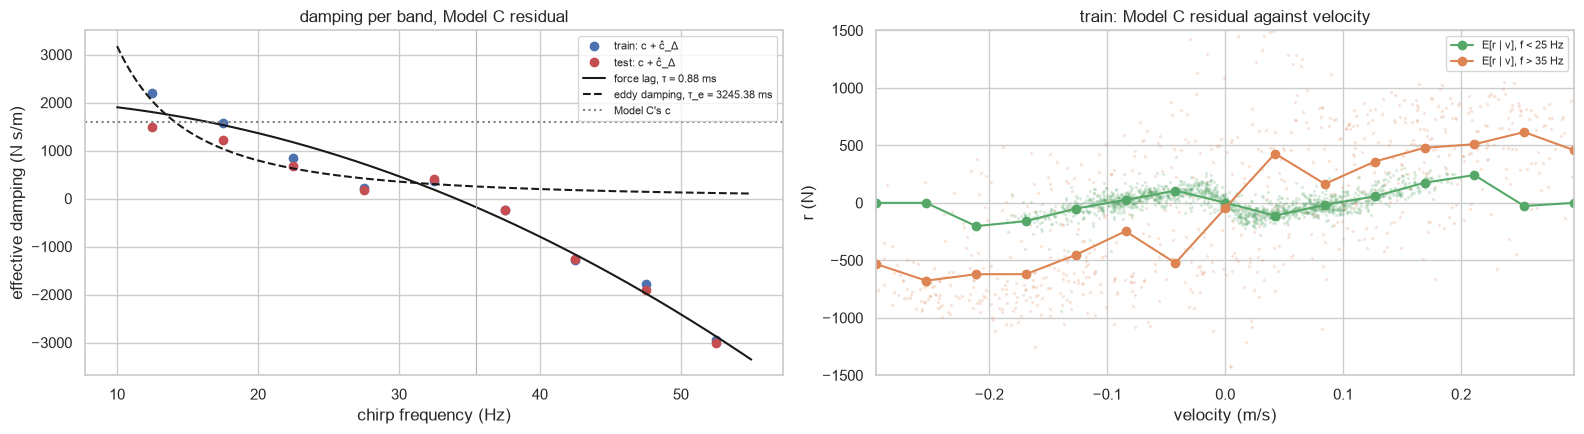

In [ ]:
from scipy.optimize import curve_fit

F_EDGES = np.arange(10.0, 56.0, 5.0)                    # Hz, band edges for the per-band damping
V_SLICE = 0.01                                          # m/s, width of the slices either side of v = 0 (Coulomb step)
N_KNOTS = 15                                            # knots of the free-shape velocity curve


def chirp_freq(split, exp="chirpsched"):
    "Instantaneous chirp frequency of each sample of DATA[exp][split], from the file name as in load()."
    path = next(Path("data", split).glob(f"voice_coil_log_{exp}_*.csv"))
    f0, f1, T = map(float, re.search(r"_([\d.]+)to([\d.]+)Hz_([\d.]+)s_", path.name).groups())
    return f0 * (f1 / f0) ** (DATA[exp][split]["t"] / T)


def residual_C(d):
    "Force Model C leaves unexplained, r = m a - model C (N), on every sample."
    return M * d["a"] - (p_C[0] * d["i"] - p_C[1] * d["v"] - magnets(d["x"], d["i"], p_C[2:]))


def hat_basis(v, knots):
    "Piecewise-linear hat functions on the knots (constant beyond the end knots), one column per knot."
    return np.column_stack([np.interp(v, knots, e) for e in np.eye(len(knots))])


k_C = 3 * (p_C[3] + p_C[4]) / G00**4                    # magnet stiffness at x = 0
print(f"Model C: c = {p_C[1]:.0f} N s/m; spring resonance f_n = {np.sqrt(k_C / M) / (2 * np.pi):.1f} Hz (the sweep starts at 10 Hz)")

# 1. missing damping per frequency band, train and test
BANDS = {}
print(f"\n{'band (Hz)':>10s} | {'train: std r (N)':>16s} {'c_eff (N s/m)':>13s} | {'test: std r (N)':>15s} {'c_eff (N s/m)':>13s}")
for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:]):
    row = []
    for split in ("train", "test"):
        d = DATA["chirpsched"][split]
        f, r = chirp_freq(split), residual_C(d)
        m = d["sweep"] & (f >= lo) & (f < hi)
        c_delta = -np.sum(r[m] * d["v"][m]) / np.sum(d["v"][m] ** 2)
        BANDS.setdefault(split, []).append((0.5 * (lo + hi), np.std(r[m]), p_C[1] + c_delta))
        row += [np.std(r[m]), p_C[1] + c_delta]
    print(f"{lo:4.0f}-{hi:<5.0f} | {row[0]:16.0f} {row[1]:13.0f} | {row[2]:15.0f} {row[3]:13.0f}")
BANDS = {s: np.array(b) for s, b in BANDS.items()}      # columns: band centre f, std r, c_eff

# 2. fit the two shapes to the train bands
fc, c_eff = BANDS["train"][:, 0], BANDS["train"][:, 2]
w_c = 2 * np.pi * fc
(c0_lag, tau_lag), *_ = np.linalg.lstsq(np.column_stack([np.ones_like(w_c), -M * w_c**2]), c_eff, rcond=None)
eddy = lambda w, c_e, tau_e: c_e / (1 + (w * tau_e) ** 2)
(c_e, tau_e), _ = curve_fit(eddy, w_c, c_eff, p0=(c_eff.max(), 1e-3), bounds=(0, np.inf))
rms_fit = lambda pred: np.sqrt(np.mean((c_eff - pred) ** 2))
print(f"\nforce lag:   c_eff = c0 - m w^2 tau,       c0 = {c0_lag:.0f} N s/m, tau = {tau_lag * 1e3:.3f} ms;  rms misfit {rms_fit(c0_lag - M * w_c**2 * tau_lag):.0f} N s/m")
print(f"eddy damping: c_eff = c_e / (1 + (w tau_e)^2), c_e = {c_e:.0f} N s/m, tau_e = {tau_e * 1e3:.3f} ms;  rms misfit {rms_fit(eddy(w_c, c_e, tau_e)):.0f} N s/m")

# 3. Coulomb step: mean residual just above minus just below v = 0 equals -2 F_c
for split in ("train", "test"):
    d = DATA["chirpsched"][split]
    r, v = residual_C(d)[d["sweep"]], d["v"][d["sweep"]]
    up, dn = r[(v > 0) & (v < V_SLICE)], r[(v < 0) & (v > -V_SLICE)]
    jump = up.mean() - dn.mean()
    se = np.sqrt(up.var() / len(up) + dn.var() / len(dn))   # naive: samples are correlated, the real uncertainty is larger
    print(f"[{split:5s}] Coulomb step r(0+) - r(0-) = {jump:+.1f} N (+-{se:.1f} N naive std err) -> F_c = {-jump / 2:+.1f} N")

# figure: c_eff per band with both fits (left), free-shape velocity curves per frequency group (right)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for split, color in (("train", "C0"), ("test", "C3")):
    ax[0].plot(BANDS[split][:, 0], BANDS[split][:, 2], "o", color=color, label=f"{split}: c + ĉ_Δ")
fg = np.linspace(F_EDGES[0], F_EDGES[-1], 200)
ax[0].plot(fg, c0_lag - M * (2 * np.pi * fg) ** 2 * tau_lag, "k-", label=f"force lag, τ = {tau_lag * 1e3:.2f} ms")
ax[0].plot(fg, eddy(2 * np.pi * fg, c_e, tau_e), "k--", label=f"eddy damping, τ_e = {tau_e * 1e3:.2f} ms")
ax[0].axhline(p_C[1], color="0.5", ls=":", label="Model C's c")
ax[0].axvline(35.5, color="0.7", lw=0.8)
ax[0].set(xlabel="chirp frequency (Hz)", ylabel="effective damping (N s/m)", title="damping per band, Model C residual")
ax[0].legend(fontsize=8)
d, f = DATA["chirpsched"]["train"], chirp_freq("train")
r = residual_C(d)
v_max = np.percentile(np.abs(d["v"][d["sweep"]]), 99)
knots = np.linspace(-v_max, v_max, N_KNOTS)
for name, m, color in (("f < 25 Hz", d["sweep"] & (f < 25), "C2"), ("f > 35 Hz", d["sweep"] & (f > 35), "C1")):
    w_hat, *_ = np.linalg.lstsq(hat_basis(d["v"][m], knots), r[m], rcond=None)
    ax[1].scatter(d["v"][m][::40], r[m][::40], s=2, alpha=0.15, color=color)
    ax[1].plot(knots, w_hat, "o-", color=color, label=f"E[r | v], {name}")
ax[1].set(xlim=(-v_max, v_max), ylim=(-1500, 1500), xlabel="velocity (m/s)", ylabel="r (N)", title="train: Model C residual against velocity")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Model D: Model C with better dissipation, LLS

Model D keeps Model C's motor, $\Gamma(x)$ and magnets, and replaces the single viscous damper by a set of candidate dissipation terms. All parameters are refitted jointly:

$$m\ddot{x} = (\Gamma + \Gamma_1 x)\, i \;-\; \underbrace{\Gamma\tau\,\frac{di}{dt}}_{\text{force lag}} \;-\; \underbrace{(c + c_1 x + c_2 x^2)\,\dot{x}}_{c(x)} \;-\; \underbrace{c_q\,\dot{x}|\dot{x}|}_{\text{quadratic}} \;-\; \underbrace{\left(F_c + F_{st}\, e^{-(\dot{x}/v_{st})^2}\right)\tanh\frac{\dot{x}}{v_c}}_{\text{Coulomb + Stribeck}} \;-\; \left(\frac{C_R}{(g_0 - x)^3} - \frac{C_L}{(g_0 + x)^3}\right)$$

| Term | Physical picture | Parameters |
|---|---|---|
| force lag | **not friction**: current-induced eddy currents, the drive's current loop, or a logging misalignment; a nuisance term so the damping terms are not biased by it | $\Gamma\tau$, with $\tau = \Gamma\tau / \Gamma$ |
| $c(x)$ | air-film or eddy damping that changes along the stroke | $c, c_1, c_2$ |
| quadratic | damping that grows (or saturates, $c_q < 0$) with speed | $c_q$ |
| Coulomb + Stribeck | sliding friction with a stiction peak; on an air bearing a **null check**, expected $\approx 0$ | $F_c, F_{st}$ |

The force lag $\tau$ cannot be told apart from a leftover alignment error between the logged current and position: shifting the position log by $\delta$ changes the fitted $\tau$ by about $\delta$. It is therefore not interpreted here.

**Linear in the parameters.** With $v_c$ and $v_{st}$ fixed, every term is a known regressor times one coefficient:

$$m\ddot{x}_k = \varphi\!\left(x_k, \dot{x}_k, i_k, \tfrac{di}{dt}\big|_k\right)^{\!\top} \theta$$

fitted by the same weighted, bounded least squares as Methods A–C, with $W = \mathrm{diag}\big(1/|\mathcal{H}\{i\}|\big)$ the inverse current amplitude (Hilbert envelope):

$$\hat{\theta} = \arg\min_{\theta \,\geq\, \theta_{lb}} \left\| W\left(\Phi\,\theta - m\ddot{x}\right) \right\|^2, \qquad c,\, C_R,\, C_L,\, F_c,\, F_{st} \geq 0$$

$\Gamma\tau$, $c_1$, $c_2$, $c_q$ are free: their sign is part of the answer. $\tanh(\dot{x}/v_c)$ is a smooth $\mathrm{sign}(\dot{x})$; $v_c$ and $v_{st}$ are picked from a small grid by the lowest weighted cost.

**Variants**

| Variant | Terms added to Model C |
|---|---|
| D0 | force lag |
| D1 | $c(x)$, quadratic |
| D2 | Coulomb + Stribeck (null check) |
| D-full | all of the above |

**Simulation.** `rollout_D` is `rollout` with a force that also depends on $\dot{x}$ and $\frac{di}{dt}$. $\frac{di}{dt}$ is the gradient of the filtered current, held constant over each RK4 step like the current itself (zero-order hold).

In [ ]:
BASE = ["Gamma", "c", "Gamma1", "C_R", "C_L"]          # Model C's parameters, in the order of p_C
LB0 = ("c", "C_R", "C_L", "F_c", "F_st")                # physically non-negative; all others free
V_C_GRID = [0.002, 0.005, 0.01, 0.02, 0.05]             # m/s, smoothing velocity of the Coulomb sign
V_ST_GRID = [0.01, 0.02, 0.05, 0.1]                     # m/s, Stribeck decay velocity
VARIANTS = {"D0": BASE + ["Gtau"],
            "D1": BASE + ["c1", "c2", "cq"],
            "D2": BASE + ["F_c", "F_st"],
            "D-full": BASE + ["Gtau", "c1", "c2", "cq", "F_c", "F_st"]}
LABELS = {"D0": "D0: C + force lag", "D1": "D1: C + c(x) + v|v|", "D2": "D2: C + Coulomb/Stribeck", "D-full": "D-full: all terms"}


def regressors(x, v, i, di, v_c, v_st):
    "Every candidate term of m a = phi' theta: the column that multiplies its coefficient, keyed by parameter name."
    sgn = np.tanh(v / v_c)                              # smooth sign(v)
    return {"Gamma": i, "c": -v, "Gamma1": x * i,
            "C_R": -1 / (G00 - x)**3, "C_L": 1 / (G00 + x)**3,
            "Gtau": -di,                                # force lag: Gamma i(t - tau) ~ Gamma i - Gamma tau di/dt
            "c1": -x * v, "c2": -x**2 * v,              # c(x) = c + c1 x + c2 x^2
            "cq": -v * np.abs(v),                       # quadratic damping
            "F_c": -sgn,                                # Coulomb
            "F_st": -np.exp(-(v / v_st)**2) * sgn}      # Stribeck peak on top of Coulomb


def design(d, sel, names, v_c, v_st):
    "Regressor matrix of the named terms on the samples sel."
    cols = regressors(d["x"][sel], d["v"][sel], d["i"][sel], np.gradient(d["i"], TS)[sel], v_c, v_st)
    return np.column_stack([cols[n] for n in names])


def fit_D(names, v_c, v_st, d):
    "Weighted bounded LLS on the sweep of run d, as Method C. Returns theta (in the order of names) and the weighted cost."
    sel = d["sweep"]
    A, y = design(d, sel, names, v_c, v_st), M * d["a"][sel]
    w = 1 / np.abs(signal.hilbert(d["i"]))[sel]        # 1 / current amplitude, as in Methods A-C
    lb = [0.0 if n in LB0 else -np.inf for n in names]
    sc = np.linalg.norm(A * w[:, None], axis=0)         # column scaling
    r = lsq_linear(A * w[:, None] / sc, y * w, bounds=(lb, np.inf))
    return r.x / sc, 2 * r.cost


def fit_variant(names):
    "Fit; when Coulomb is in, take v_c and v_st from the grid with the lowest weighted cost."
    grid = [(a, b) for a in V_C_GRID for b in V_ST_GRID] if "F_c" in names else [(V_C_GRID[2], V_ST_GRID[2])]
    d = DATA["chirpsched"]["train"]
    v_c, v_st = min(grid, key=lambda g: fit_D(names, *g, d)[1])
    return fit_D(names, v_c, v_st, d)[0], v_c, v_st


def force_D(names, v_c, v_st):
    "Force function Fs(x, v, u, du, q) for rollout_D, q = p[2:]: everything except Gamma u - c v, so m a = Gamma u - c v - Fs."
    def Fs(x, v, u, du, q):
        cols = regressors(x, v, u, du, v_c, v_st)
        return -sum(qj * cols[n] for n, qj in zip(names[2:], q))
    return Fs


def rollout_D(Fs, p, d, s, H):
    "As rollout, but the force also gets the velocity and di/dt: Fs(x, v, u, du, q)."
    di = np.gradient(d["i"], TS)
    x, v, out = d["x"][s], d["v"][s], [d["x"][s]]
    with np.errstate(all="ignore"):
        for k in range(H):
            u0, du = d["i"][s + k], di[s + k]          # di/dt held over the step, like the current (zero-order hold)
            acc = lambda x, v, u: (p[0] * u - p[1] * v - Fs(x, v, u, du, p[2:])) / M
            x, v = step(x, v, u0, d["i"][s + k + 1] if FOH else u0, acc)
            out.append(x)
    return np.stack(out, axis=1)


def force_resid_std(names, p, v_c, v_st, split):
    "Std of the unexplained force m a - phi' theta (N) on the sweep of a split."
    d = DATA["chirpsched"][split]
    return np.std(M * d["a"][d["sweep"]] - design(d, d["sweep"], names, v_c, v_st) @ p)


# self-check: D with Model C's parameters and zero extra terms reproduces Model C's rollout
_d, _s = DATA["chirpsched"]["test"], np.array([1000, 50000])
_names = BASE + ["Gtau", "cq"]
assert np.allclose(rollout_D(force_D(_names, 0.01, 0.05), np.r_[p_C, 0.0, 0.0], _d, _s, 500),
                   rollout(magnets, p_C, _d, _s, 500), rtol=0, atol=1e-12)

DV = {}
for key, names in VARIANTS.items():
    p, v_c, v_st = fit_variant(names)
    DV[key] = dict(names=names, p=p, v_c=v_c, v_st=v_st, Fs=force_D(names, v_c, v_st))
    q = dict(zip(names, p))
    extra = []
    if "Gtau" in q:
        extra.append(f"tau = {q['Gtau'] / q['Gamma'] * 1e3:.3f} ms")
    if "F_c" in q:
        extra.append(f"v_c = {v_c} m/s, v_st = {v_st} m/s")
    print(f"{LABELS[key]}\n  " + ", ".join(f"{n} = {val:.4g}" for n, val in q.items()) + ("\n  " + ", ".join(extra) if extra else ""))
    print(f"  unexplained force std: train {force_resid_std(names, p, v_c, v_st, 'train'):.0f} N, test {force_resid_std(names, p, v_c, v_st, 'test'):.0f} N")
print(f"Model C (reference)\n  unexplained force std: train {force_resid_std(BASE, p_C, 0.01, 0.05, 'train'):.0f} N, "
      f"test {force_resid_std(BASE, p_C, 0.01, 0.05, 'test'):.0f} N")

D0: C + force lag
  Gamma = 210.3, c = 2419, Gamma1 = 6456, C_R = 0.001521, C_L = 0.001538, Gtau = 0.2161
  tau = 1.028 ms
  unexplained force std: train 317 N, test 304 N
D1: C + c(x) + v|v|
  Gamma = 211.8, c = 3718, Gamma1 = 6263, C_R = 0.001012, C_L = 0.001058, c1 = 5.886e+04, c2 = -2.772e+07, cq = -1.775e+04
  unexplained force std: train 350 N, test 333 N
D2: C + Coulomb/Stribeck
  Gamma = 209.6, c = 7.907e-12, Gamma1 = 5956, C_R = 0.001427, C_L = 0.001452, F_c = 126.6, F_st = 65.87
  v_c = 0.02 m/s, v_st = 0.1 m/s
  unexplained force std: train 357 N, test 341 N
D-full: all terms
  Gamma = 213.5, c = 140.1, Gamma1 = 7389, C_R = 0.00153, C_L = 0.00157, Gtau = 0.1601, c1 = -2342, c2 = 3.901e+07, cq = 2241, F_c = 169.1, F_st = 64.26
  tau = 0.750 ms, v_c = 0.02 m/s, v_st = 0.02 m/s
  unexplained force std: train 310 N, test 295 N
Model C (reference)
  unexplained force std: train 405 N, test 384 N


### Model D: prediction against horizon

Each variant is simulated with `rollout_D` from the measured state, as Methods A–C (`evaluate_D` = `evaluate` with `rollout_D`). The summary table compares them with Model C: the unexplained force std on the fit data (train) and on test, and the position NRMSE at $k$ = 100 and 1000 steps:

$$\mathrm{NRMSE}(k) = \frac{\sqrt{\frac{1}{N}\sum_{s}\left(\hat{x}_{s+k\mid s} - x_{s+k}\right)^2}}{\operatorname{std}(x)}$$

train NRMSE at k = 1, 10, 100, 1000: 0.002, 0.207, 0.569, 0.643
test  NRMSE at k = 1, 10, 100, 1000: 0.002, 0.191, 0.460, 0.523


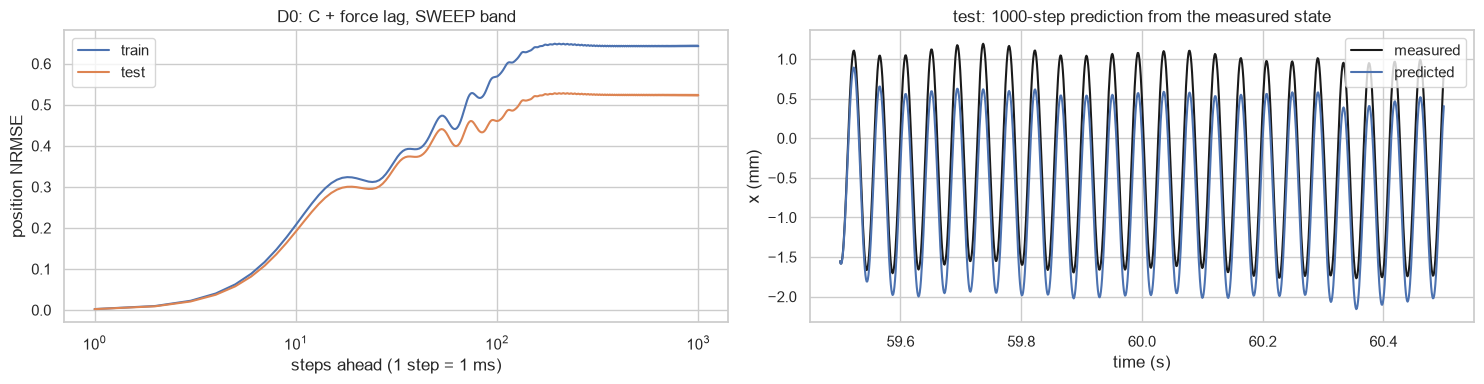

C:\Users\tommo\AppData\Local\Temp\ipykernel_5204\271814585.py:5: RuntimeWarning: overflow encountered in square
  return np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][band])


train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.278, nan, nan


C:\Users\tommo\AppData\Local\Temp\ipykernel_5204\271814585.py:5: RuntimeWarning: overflow encountered in square
  return np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][band])


test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.240, nan, nan


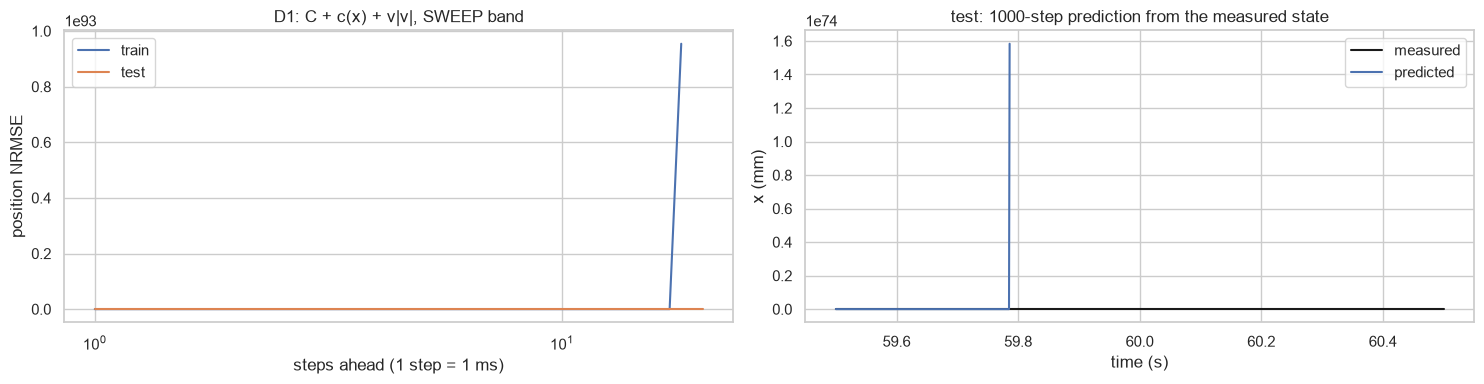

train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.204, 1.079, 0.695
test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.190, 0.886, 0.575


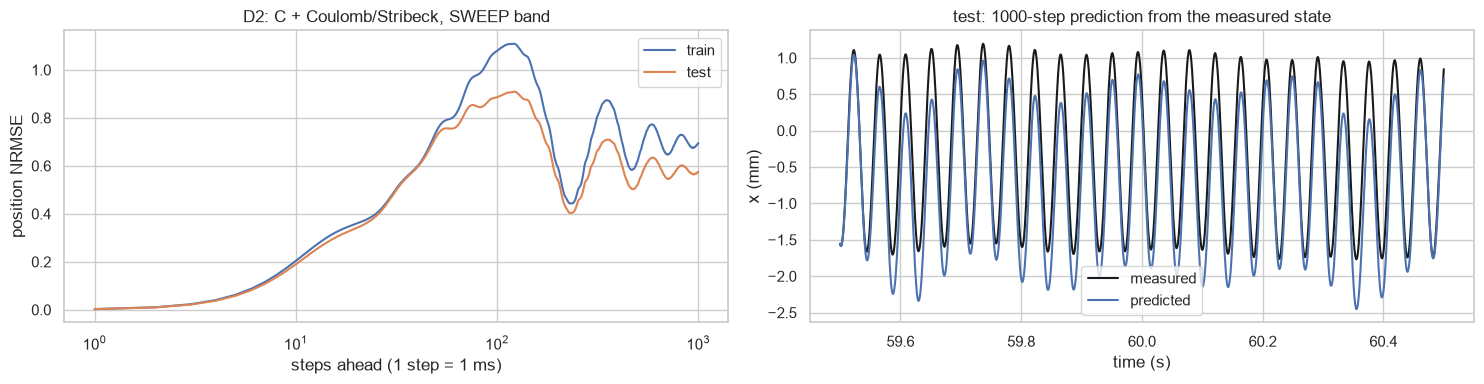

train NRMSE at k = 1, 10, 100, 1000: 0.002, 0.210, 0.736, 0.653
test  NRMSE at k = 1, 10, 100, 1000: 0.002, 0.193, 0.603, 0.528


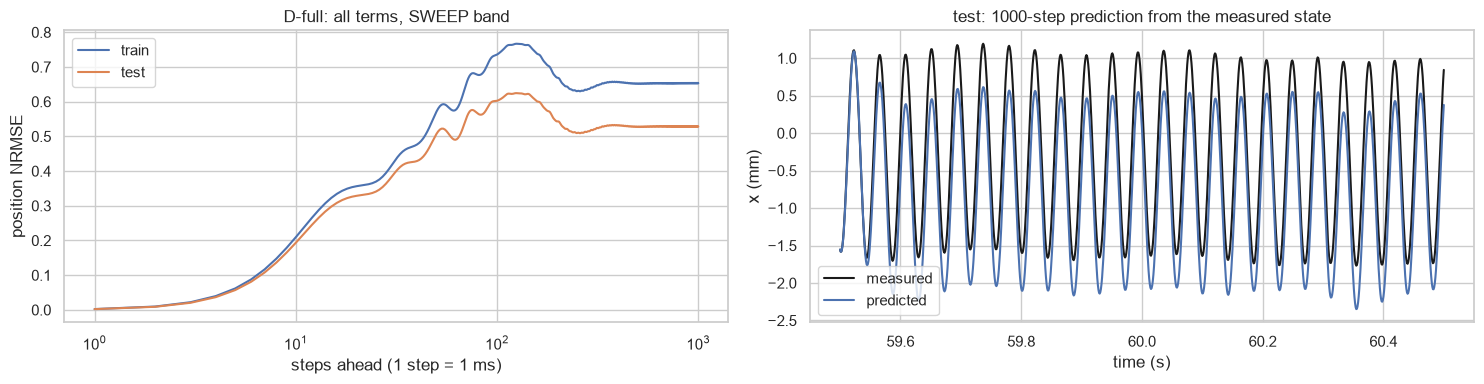


model    |   force std (N) |     NRMSE k=100 |    NRMSE k=1000
         |   train    test |   train    test |   train    test
C        |     405     384 |   0.760   0.616 |   0.710   0.577
D0       |     317     304 |   0.569   0.460 |   0.643   0.523
D1       |     350     333 |     nan     nan |     nan     nan
D2       |     357     341 |   1.079   0.886 |   0.695   0.575
D-full   |     310     295 |   0.736   0.603 |   0.653   0.528


In [ ]:
def nrmse_curve_D(Fs, p, d, band, H=H_EVAL):
    "As nrmse_curve, with rollout_D."
    s = starts(d, band, H)
    e = rollout_D(Fs, p, d, s, H) - target(d, s, H)
    return np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][band])


def evaluate_D(name, Fs, p, exp, band, H=H_EVAL):
    "As evaluate, with rollout_D. Left: NRMSE against horizon, train and test. Right: one H-step prediction on test."
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    k = np.arange(1, H + 1)
    for split, d in DATA[exp].items():
        e = nrmse_curve_D(Fs, p, d, d[band], H)[1:]
        CURVES.append(dict(method=name, split=split, exp=exp, band=band, k=k, nrmse=e))
        sns.lineplot(x=k, y=e, ax=ax[0], label=split)
        print(f"{split:5s} NRMSE at k = 1, 10, 100, {H}: " + ", ".join(f"{e[j - 1]:.3f}" for j in (1, 10, 100, H)))
    ax[0].set(xscale="log", xlabel="steps ahead (1 step = 1 ms)", ylabel="position NRMSE", title=f"{name}, {band.upper()} band")
    d = DATA[exp]["test"]
    s0 = starts(d, d[band], H)
    s0 = s0[len(s0) // 2:][:1]                          # one start in the middle of the band
    t = d["t"][s0[0]:s0[0] + H + 1]
    sns.lineplot(x=t, y=target(d, s0, H)[0] * 1e3, ax=ax[1], label="measured", color="k")
    sns.lineplot(x=t, y=rollout_D(Fs, p, d, s0, H)[0] * 1e3, ax=ax[1], label="predicted")
    ax[1].set(xlabel="time (s)", ylabel="x (mm)", title=f"test: {H}-step prediction from the measured state")
    plt.tight_layout(); plt.show()


for key, D in DV.items():
    evaluate_D(LABELS[key], D["Fs"], D["p"], "chirpsched", "sweep", H=1000)

# summary against Model C; the NRMSE comes from the latest CURVES entry of each method
def curve_at(method, split, k):
    e = [c["nrmse"] for c in CURVES if c["method"] == method and c["split"] == split and c["band"] == "sweep"]
    return e[-1][k - 1] if e else np.nan

ROWS = [("C", "C: unequal magnets + Gamma(x)", BASE, p_C, 0.01, 0.05)] + \
       [(key, LABELS[key], D["names"], D["p"], D["v_c"], D["v_st"]) for key, D in DV.items()]
print(f"\n{'model':8s} | {'force std (N)':>15s} | {'NRMSE k=100':>15s} | {'NRMSE k=1000':>15s}")
print(f"{'':8s} | {'train':>7s} {'test':>7s} | {'train':>7s} {'test':>7s} | {'train':>7s} {'test':>7s}")
for key, method, names, p, v_c, v_st in ROWS:
    fs = [force_resid_std(names, p, v_c, v_st, s) for s in ("train", "test")]
    n100 = [curve_at(method, s, 100) for s in ("train", "test")]
    n1000 = [curve_at(method, s, 1000) for s in ("train", "test")]
    print(f"{key:8s} | {fs[0]:7.0f} {fs[1]:7.0f} | {n100[0]:7.3f} {n100[1]:7.3f} | {n1000[0]:7.3f} {n1000[1]:7.3f}")

## Is D0's force lag just `TAU`?

`TAU` shifts the logged position back to line it up with the current (cell 1, 0.65 ms). D0's lag $\tau$ is a second gap between the same two signals, the current and the position. If `TAU` is simply too small, the "lag" is a logging offset and not a physical effect.

**A position shift equals a current delay.** Suppose the force follows the current with a lag $\tau_0$ (after `TAU`), $m\ddot{x}(t) = \Gamma\, i(t - \tau_0) + \dots$ Reading the position an extra $\delta$ later, $x_\delta(t) = x(t + \delta)$, gives

$$m\,\ddot{x}_\delta(t) = m\,\ddot{x}(t + \delta) = \Gamma\, i\big(t - (\tau_0 - \delta)\big) + \dots \quad\Longrightarrow\quad \tau(\delta) \approx \tau_0 - \delta$$

so on the shifted data, D0 should fit a lag that falls one-for-one with $\delta$.

**Scan.** For $\delta$ from −0.5 to +2.0 ms, the train run is shifted (`shifted`: $x(t+\delta)$ by linear interpolation of the 100 Hz low-passed position at 1 kHz; $\dot{x}$, $\ddot{x}$ recomputed as in `load`). Model C and D0 are refitted on each copy. Plotted against the total alignment $\texttt{TAU} + \delta$:
- left: the unexplained force std of C and D0;
- right: D0's fitted $\tau$.

**Reading the result.**
- **Logging offset:** C's best alignment is at $\texttt{TAU}_\text{best} \approx \texttt{TAU} + \tau$, D0's $\tau$ crosses 0 there, and D0 is no better than C at that point. Then the lag belongs in `TAU`, and the firmware delay stays as it is.
- **Real force lag:** D0 stays clearly better than C at C's best alignment, or C has no clear optimum while D0 does. Then the force really lags the current reading, and the firmware should account for it (about one cycle more than `POS_KF_DELAY_CYCLES`).

Only the position is shifted. The accelerometer (`TAU_ACC`) is not used by the fits. `TAU` in cell 1 is not changed here: report only.

TAU now 0.65 ms: C residual 405 N, D0 residual 317 N, D0 tau +1.028 ms
C's best TAU 1.75 ms (TAU + D0's tau would be 1.68 ms): C residual 311 N, D0 residual 311 N, D0 tau -0.007 ms
slope of D0's tau against delta: -0.94 (-1 if the lag is a pure position shift)


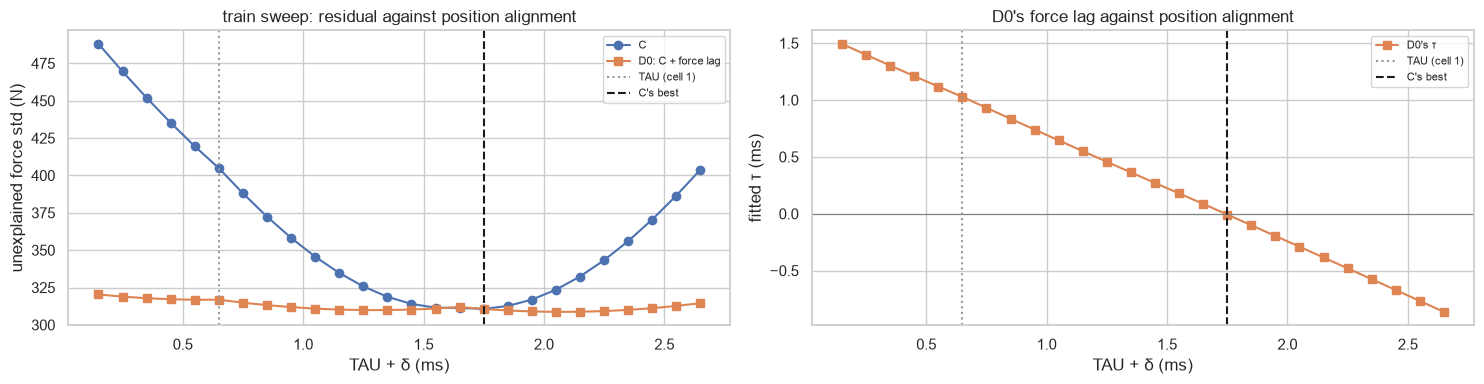

In [ ]:
DELTAS = np.round(np.arange(-0.5, 2.0 + 1e-9, 0.1), 2) * 1e-3   # s, extra position shift on top of TAU
V_C0, V_ST0 = V_C_GRID[2], V_ST_GRID[2]                 # unused by C and D0 (no Coulomb terms); needed by regressors


def shifted(d, delta):
    "Copy of a loaded run with the position read delta later, x(t + delta); v and a recomputed as in load."
    s = dict(d)
    s["x"] = np.interp(d["t"] + delta, d["t"], d["x"])    # 100 Hz low-passed at 1 kHz, so linear interpolation is accurate; the last ms is clamped
    s["v"] = np.gradient(s["x"], TS)
    s["a"] = s["a_x"] = np.gradient(s["v"], TS)
    return s


def fit_on(d, names):
    "Fit the named terms on run d; return the parameters and the unexplained force std (N) on its sweep."
    p, _ = fit_D(names, V_C0, V_ST0, d)
    return p, np.std(M * d["a"][d["sweep"]] - design(d, d["sweep"], names, V_C0, V_ST0) @ p)


SCAN = []
for delta in DELTAS:
    d = shifted(DATA["chirpsched"]["train"], delta)
    p_c, r_c = fit_on(d, BASE)
    p_d0, r_d0 = fit_on(d, VARIANTS["D0"])
    SCAN.append((TAU + delta, r_c, r_d0, p_d0[-1] / p_d0[0]))   # (total alignment, C residual, D0 residual, D0 tau = Gtau / Gamma)
SCAN = np.array(SCAN)

# check: at delta = 0 the scan reproduces Model C and D0 from the cells above
j0 = np.argmin(np.abs(DELTAS))
assert np.isclose(SCAN[j0, 1], force_resid_std(BASE, p_C, V_C0, V_ST0, "train"), rtol=1e-6)
assert np.isclose(SCAN[j0, 2], force_resid_std(VARIANTS["D0"], DV["D0"]["p"], V_C0, V_ST0, "train"), rtol=1e-6)

jc = np.argmin(SCAN[:, 1])                              # C's best alignment
print(f"TAU now {TAU * 1e3:.2f} ms: C residual {SCAN[j0, 1]:.0f} N, D0 residual {SCAN[j0, 2]:.0f} N, D0 tau {SCAN[j0, 3] * 1e3:+.3f} ms")
print(f"C's best TAU {SCAN[jc, 0] * 1e3:.2f} ms (TAU + D0's tau would be {(TAU + SCAN[j0, 3]) * 1e3:.2f} ms): "
      f"C residual {SCAN[jc, 1]:.0f} N, D0 residual {SCAN[jc, 2]:.0f} N, D0 tau {SCAN[jc, 3] * 1e3:+.3f} ms")
print(f"slope of D0's tau against delta: {np.polyfit(DELTAS, SCAN[:, 3], 1)[0]:+.2f} (-1 if the lag is a pure position shift)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(SCAN[:, 0] * 1e3, SCAN[:, 1], "o-", label="C")
ax[0].plot(SCAN[:, 0] * 1e3, SCAN[:, 2], "s-", label="D0: C + force lag")
ax[0].set(xlabel="TAU + δ (ms)", ylabel="unexplained force std (N)", title="train sweep: residual against position alignment")
ax[1].plot(SCAN[:, 0] * 1e3, SCAN[:, 3] * 1e3, "s-", color="C1", label="D0's τ")
ax[1].axhline(0, color="0.5", lw=0.8)
for a_ in ax:
    a_.axvline(TAU * 1e3, color="0.6", ls=":", label="TAU (cell 1)")
    a_.axvline(SCAN[jc, 0] * 1e3, color="k", ls="--", label="C's best")
    a_.legend(fontsize=8)
ax[1].set(xlabel="TAU + δ (ms)", ylabel="fitted τ (ms)", title="D0's force lag against position alignment")
plt.tight_layout(); plt.show()

## Where is the extra 1.1 ms? Accelerometer check

The scan above shows about 1.75 ms between the logged current and the laser position, 1.1 ms more than `TAU`. It cannot say where in the chain that time is lost. The accelerometer is an independent sensor on the same mass, so it can tell the two places apart:

| Where the delay is | Laser (after `TAU`) | Accelerometer (after `TAU_ACC`) | Firmware consequence |
|---|---|---|---|
| **force side** (current reading → force: drive current loop, eddy currents) | 1.1 ms late | also 1.1 ms late | a longer **input** delay (larger `POS_KF_DELAY_CYCLES`) |
| **laser path** (laser, its electronics, logging) | 1.1 ms late | on time | a **measurement** delay in the EKF |

`TAU_ACC` = 2.65 ms is the accelerometer's alignment as set in cell 1, like `TAU` for the laser.

**Test 1, without a model: the delay between the two sensors.** Both measure the acceleration of the same mass: $a_\text{meas}$ from the accelerometer, and $a_x = \ddot{x}$ from the laser. Both are zero-phase filtered the same way in `load`, so any phase between them is a timing difference. From the cross-spectral density $G_{a_\text{meas} a_x}(f)$ (Welch):

$$\tau_{x-a}(f) = -\frac{\angle G_{a_\text{meas}\,a_x}(f)}{2\pi f}, \qquad \gamma^2(f) = \frac{|G_{a_\text{meas}\,a_x}(f)|^2}{G_{a_\text{meas}a_\text{meas}}(f)\,G_{a_x a_x}(f)}$$

$\tau_{x-a} > 0$ means the laser-derived acceleration comes later than the accelerometer. It is only read where the coherence $\gamma^2 \geq 0.9$:
- **force side:** $\tau_{x-a} \approx 0$, because both sensors are equally late;
- **laser path:** $\tau_{x-a} \approx +1.1$ ms.

A pure delay gives a flat $\tau_{x-a}(f)$. A bump near 35.5 Hz would show the laser-mount mode, which moves the laser but not the mass.

**Test 2, with the model: the accelerometer against the current.** As in the scan above, but the fit target is the accelerometer, $m\,a_\text{meas}(t + \delta_a) = \varphi^\top\theta$. Position and velocity in the regressors come from the laser at its best alignment, $\texttt{TAU} + \delta_x$. Model C is refitted for each $\delta_a$:
- **force side:** the best $\texttt{TAU\_ACC} + \delta_a \approx 2.65 + 1.1$ ms;
- **laser path:** the best is at $\approx 2.65$ ms.

Test 2 depends on the accelerometer's own phase response (its bandwidth), test 1 only on the difference between the sensors. When the two tests agree, the answer is solid.

[train] laser behind accelerometer: median +0.05 ms over 177 bins with coherence >= 0.9 (10.0-54.0 Hz); 10-90 %: -0.15 to +0.35 ms
[test ] laser behind accelerometer: median +0.05 ms over 177 bins with coherence >= 0.9 (10.0-54.0 Hz); 10-90 %: -0.17 to +0.37 ms


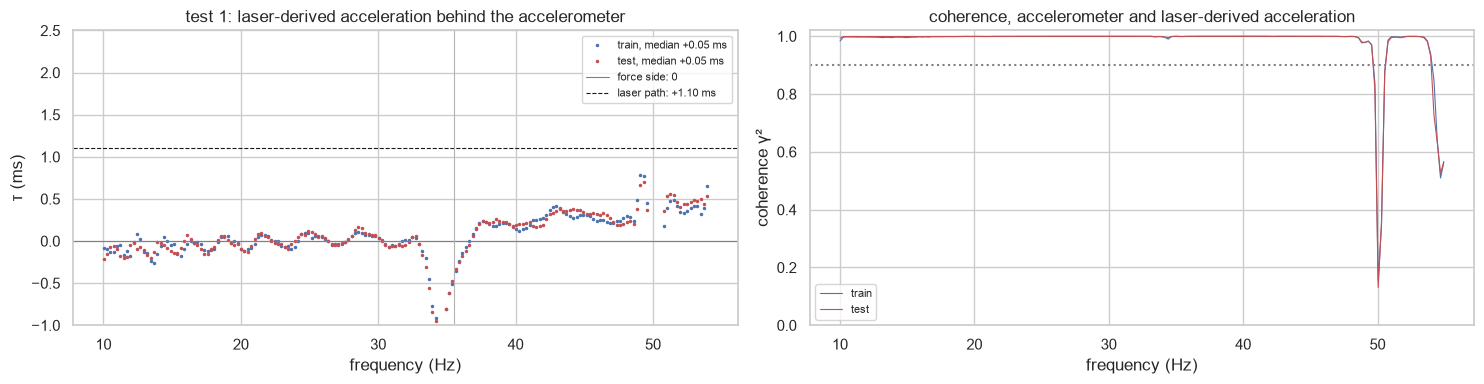


test 2: laser at TAU + 1.10 = 1.75 ms; accelerometer best TAU_ACC = 3.45 ms (cell 1: 2.65 ms; force side predicts 3.75 ms), C residual 207 N


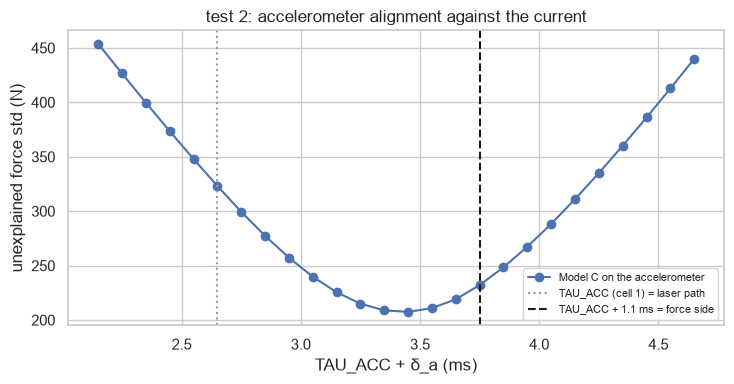

In [ ]:
F_COH = (10.0, 55.0)                                    # Hz, band where the sensor delay is read
COH_MIN = 0.9                                           # coherence threshold
DELTAS_A = np.round(np.arange(-0.5, 2.0 + 1e-9, 0.1), 2) * 1e-3   # s, extra accelerometer shift on top of TAU_ACC
DELTA_X = SCAN[jc, 0] - TAU                             # laser shift at Model C's best alignment (scan above)


def sensor_delay(d, nperseg=4096):
    "Delay of the laser-derived acceleration behind the accelerometer per frequency (s), with the coherence."
    sel = d["sweep"]
    f, G = signal.csd(d["a_meas"][sel], d["a_x"][sel], fs=1 / TS, nperseg=nperseg)   # G = E[conj(A_meas) A_x]
    _, coh = signal.coherence(d["a_meas"][sel], d["a_x"][sel], fs=1 / TS, nperseg=nperseg)
    with np.errstate(divide="ignore", invalid="ignore"):
        tau = -np.angle(G) / (2 * np.pi * f)
    return f, tau, coh


def with_accelerometer(d, delta_x, delta_a):
    "Run d with the laser shifted by delta_x (x, v from shifted) and the fit target a = accelerometer read delta_a later."
    s = shifted(d, delta_x)
    s["a"] = np.interp(d["t"] + delta_a, d["t"], d["a_meas"])
    return s


# test 1: delay between the sensors, from the cross-spectral phase
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for split, color in (("train", "C0"), ("test", "C3")):
    f, tau, coh = sensor_delay(DATA["chirpsched"][split])
    band = (f >= F_COH[0]) & (f <= F_COH[1])
    good = band & (coh >= COH_MIN)
    tau_med = np.median(tau[good])
    print(f"[{split:5s}] laser behind accelerometer: median {tau_med * 1e3:+.2f} ms over {good.sum()} bins with coherence >= {COH_MIN} "
          f"({f[good].min():.1f}-{f[good].max():.1f} Hz); 10-90 %: {np.percentile(tau[good], 10) * 1e3:+.2f} to {np.percentile(tau[good], 90) * 1e3:+.2f} ms")
    ax[0].plot(f[band], np.where(coh[band] >= COH_MIN, tau[band] * 1e3, np.nan), ".", ms=3, color=color, label=f"{split}, median {tau_med * 1e3:+.2f} ms")
    ax[1].plot(f[band], coh[band], lw=0.8, color=color, label=split)
ax[0].axhline(0, color="0.5", lw=0.8, label="force side: 0")
ax[0].axhline(DELTA_X * 1e3, color="k", ls="--", lw=0.8, label=f"laser path: +{DELTA_X * 1e3:.2f} ms")
ax[0].axvline(35.5, color="0.7", lw=0.8)
ax[0].set(xlabel="frequency (Hz)", ylabel="τ (ms)", ylim=(-1, 2.5), title="test 1: laser-derived acceleration behind the accelerometer")
ax[1].axhline(COH_MIN, color="0.5", ls=":")
ax[1].set(xlabel="frequency (Hz)", ylabel="coherence γ²", ylim=(0, 1.02), title="coherence, accelerometer and laser-derived acceleration")
for a_ in ax:
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

# test 2: best accelerometer alignment against the current (Model C fitted on the accelerometer)
SCAN_A = np.array([(TAU_ACC + da, fit_on(with_accelerometer(DATA["chirpsched"]["train"], DELTA_X, da), BASE)[1]) for da in DELTAS_A])
ja = np.argmin(SCAN_A[:, 1])
print(f"\ntest 2: laser at TAU + {DELTA_X * 1e3:.2f} = {(TAU + DELTA_X) * 1e3:.2f} ms; accelerometer best TAU_ACC = {SCAN_A[ja, 0] * 1e3:.2f} ms "
      f"(cell 1: {TAU_ACC * 1e3:.2f} ms; force side predicts {(TAU_ACC + DELTA_X) * 1e3:.2f} ms), C residual {SCAN_A[ja, 1]:.0f} N")
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(SCAN_A[:, 0] * 1e3, SCAN_A[:, 1], "o-", label="Model C on the accelerometer")
ax.axvline(TAU_ACC * 1e3, color="0.6", ls=":", label="TAU_ACC (cell 1) = laser path")
ax.axvline((TAU_ACC + DELTA_X) * 1e3, color="k", ls="--", label="TAU_ACC + 1.1 ms = force side")
ax.set(xlabel="TAU_ACC + δ_a (ms)", ylabel="unexplained force std (N)", title="test 2: accelerometer alignment against the current")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## What is left above 35 Hz: a resonance between the two sensors

After the alignment, Model C still leaves about 310 N unexplained, mostly above 35 Hz (the application band). This section checks whether that is missing physics or an error in one of the sensors.

**1. The accelerometer against the laser, per frequency.** Both sensors are aligned as found above (laser at $\texttt{TAU} + \delta_x$, accelerometer at its best $\texttt{TAU\_ACC} + \delta_a$). Their ratio is estimated with the $H_1$ estimator, using the laser-derived acceleration $a_x$ as input:

$$H(f) = \frac{G_{a_x a_\text{meas}}(f)}{G_{a_x a_x}(f)} \approx \frac{A_\text{meas}(f)}{A_x(f)}$$

If both sensors measured the mass perfectly, $H(f)$ would be a constant (the accelerometer's scale error) with zero phase. $H_1$ is biased low by noise on the input, $|H_1| = |H|\,\gamma^2$ for white noise on $a_x$. It is therefore only read where the coherence $\gamma^2 \geq 0.99$, which holds on the scheduled chirp. On the plain chirp the laser signal is small at high frequency, so the coherence is lower, and that run is not used here.

A **resonance** in one sensor path at $f_m$ shows up in $H(f)$ as:
- a step in gain between below and above $f_m$;
- a phase excursion around $f_m$.

**2. Which sensor carries it: Model C fitted per band.** Model C is fitted separately below the mode (10–34 Hz) and above it (37–47 Hz), once on each sensor. Above 47 Hz is left out: the 50 Hz notch in `load` (Q = 30) also removes *real* motion from the laser there. A sensor without the mode needs the same parameters in both bands:

$$\frac{\Gamma_{37\text{–}47\,\text{Hz}}}{\Gamma_{10\text{–}34\,\text{Hz}}} \approx 1 \quad\text{for the sensor without the mode}$$

The absolute scale of the accelerometer comes from an earlier calibration against the laser (`ACC_SCALE_V_PER_G`, corrected by the gain above 35 Hz). So its absolute $\Gamma$ is not independent. Only the *change* between bands is.

[train] 25-32 Hz: gain 1.371, phase -2.9 deg
[train] 38-46 Hz: gain 1.132, phase -0.6 deg
[test ] 25-32 Hz: gain 1.378, phase -2.8 deg
[test ] 38-46 Hz: gain 1.134, phase -0.6 deg


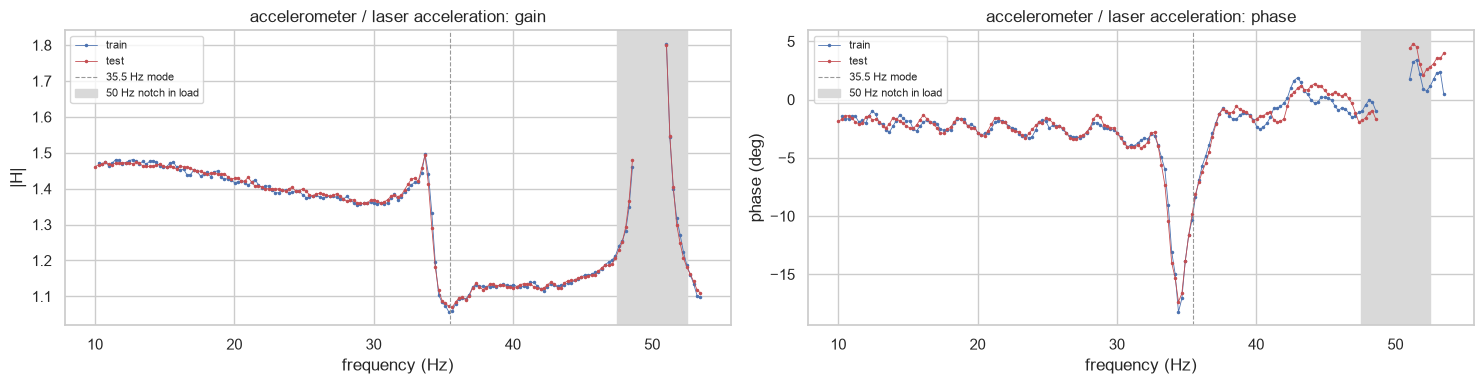


                       | 10-34 Hz: Gamma, c, resid | 37-47 Hz: Gamma, c, resid | 10-47 Hz: Gamma, c, resid | Gamma above / below
[train] laser          |     212.3 N/A, 2472, 106 N |     245.1 N/A, 2516, 137 N |     220.6 N/A, 2585, 158 N | 1.154
[train] accelerometer  |     292.0 N/A, 3129, 124 N |     275.0 N/A, 2661, 116 N |     286.6 N/A, 3017, 159 N | 0.942
[test ] laser          |     214.7 N/A, 1917, 103 N |     244.6 N/A, 2456, 124 N |     222.8 N/A, 2033, 159 N | 1.139
[test ] accelerometer  |     296.9 N/A, 2397,  85 N |     273.9 N/A, 2644,  99 N |     289.1 N/A, 2316, 131 N | 0.923


In [ ]:
COH_MODE = 0.99                                         # coherence needed to read H1 (its bias is |H| gamma^2)
DELTA_A = SCAN_A[ja, 0] - TAU_ACC                       # accelerometer shift at its best alignment (test 2 above)
BANDS_MODE = [(10, 34), (37, 47), (10, 47)]             # Hz: below the mode, above it (below the 50 Hz notch), both


def sensor_ratio(d):
    "H1 estimate of accelerometer / laser-derived acceleration on the sweep, with the coherence."
    sel = d["sweep"]
    f, P_ll = signal.welch(d["a_x"][sel], fs=1 / TS, nperseg=4096)
    _, P_lm = signal.csd(d["a_x"][sel], d["a"][sel], fs=1 / TS, nperseg=4096)
    _, coh = signal.coherence(d["a_x"][sel], d["a"][sel], fs=1 / TS, nperseg=4096)
    return f, P_lm / P_ll, coh


def fit_band(d, f_chirp, lo, hi):
    "Model C fitted on the part of the sweep between lo and hi Hz; returns parameters and unexplained force std."
    dd = dict(d)
    dd["sweep"] = d["sweep"] & (f_chirp >= lo) & (f_chirp < hi)
    return fit_on(dd, BASE)


SENSORS = {split: {"laser": shifted(DATA["chirpsched"][split], DELTA_X),
                   "accelerometer": with_accelerometer(DATA["chirpsched"][split], DELTA_X, DELTA_A)}
           for split in ("train", "test")}

# 1. ratio of the two sensors against frequency
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for split, color in (("train", "C0"), ("test", "C3")):
    f, H, coh = sensor_ratio(SENSORS[split]["accelerometer"])   # its "a_x" is the laser, its "a" the accelerometer
    m = (f >= 8) & (f <= 56)
    ok = np.where(coh[m] >= COH_MODE, 1.0, np.nan)
    ax[0].plot(f[m], np.abs(H[m]) * ok, ".-", ms=3, lw=0.6, color=color, label=split)
    ax[1].plot(f[m], np.degrees(np.angle(H[m])) * ok, ".-", ms=3, lw=0.6, color=color, label=split)
    for lo, hi in ((25, 32), (38, 46)):
        b = (f >= lo) & (f < hi) & (coh >= COH_MODE)
        print(f"[{split:5s}] {lo}-{hi} Hz: gain {np.median(np.abs(H[b])):.3f}, phase {np.degrees(np.median(np.angle(H[b]))):+.1f} deg")
for a_ in ax:
    a_.axvline(35.5, color="0.6", ls="--", lw=0.8, label="35.5 Hz mode")
    a_.axvspan(47.5, 52.5, color="0.85", label="50 Hz notch in load")
    a_.legend(fontsize=8)
ax[0].set(xlabel="frequency (Hz)", ylabel="|H|", title="accelerometer / laser acceleration: gain")
ax[1].set(xlabel="frequency (Hz)", ylabel="phase (deg)", title="accelerometer / laser acceleration: phase")
plt.tight_layout(); plt.show()

# 2. Model C per band, on each sensor
print(f"\n{'':22s} | " + " | ".join(f"{lo}-{hi} Hz: Gamma, c, resid" for lo, hi in BANDS_MODE) + " | Gamma above / below")
for split in ("train", "test"):
    f_chirp = chirp_freq(split)
    for sensor, d in SENSORS[split].items():
        res = [fit_band(d, f_chirp, lo, hi) for lo, hi in BANDS_MODE]
        cells_ = [f"{p[0]:5.1f} N/A, {p[1]:4.0f}, {r:3.0f} N" for p, r in res]
        print(f"[{split:5s}] {sensor:14s} | " + " | ".join(f"{c_:>26s}" for c_ in cells_) + f" | {res[1][0][0] / res[0][0][0]:.3f}")

## Model C's residual: what is in it?

The residual force of Model C at its best alignment, for both sensors (same fit set-up as above; the accelerometer as fit target in the second case):

$$r_k = m\,a_k - \varphi_k^\top \hat\theta$$

**Harmonic decomposition.** The current is a chirp with phase $\phi(t) = \angle\,\mathcal{H}\{i\}(t)$ (Hilbert transform). In short windows of `WIN_S` s the residual is projected onto the first three harmonics of that phase by least squares:

$$r(t) \approx \sum_{n=1}^{3} \big(a_n \cos n\phi(t) + b_n \sin n\phi(t)\big) + \varepsilon(t)$$

The variance each part explains in a window says what kind of error it is:

| Part | Meaning | What could fix it |
|---|---|---|
| $n = 1$ (the chirp frequency) | linear error: wrong gain or phase, a sensor resonance, a missing linear term | a sensor model, or a linear dynamic term |
| $n = 2, 3$ | nonlinearity: the force is not a straight function of $i$, $x$, $\dot{x}$ as modelled | nonlinear terms (in $\Gamma(x)$, the spring, ...) |
| rest $\varepsilon$ | fixed lines (mains 50/150 Hz, mount mode), broadband noise, transients | measurement processing; a model cannot predict noise |

Below, the spectrogram shows where the residual's energy sits against the chirp lines $f$, $2f$, $3f$, and the table splits its variance per 5 Hz band.

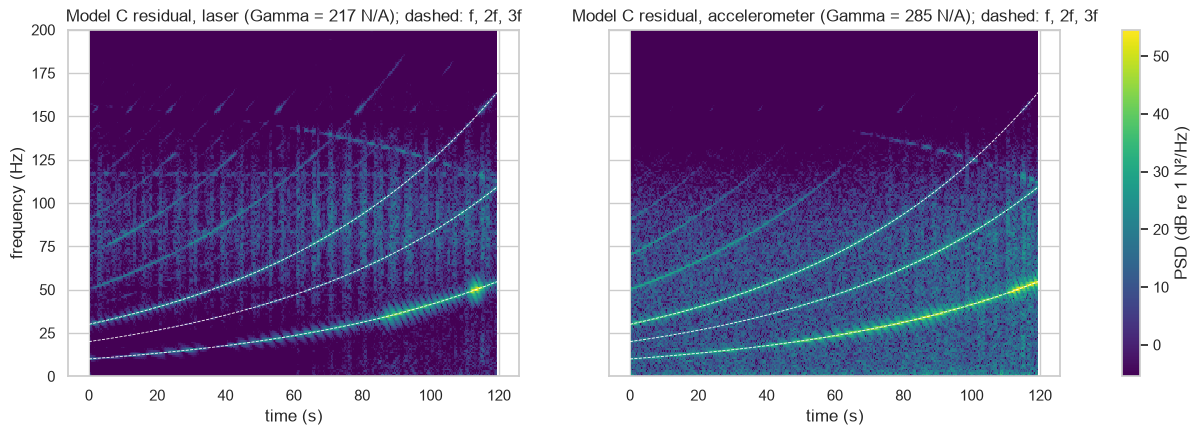

                    band |  std r |    1f    2f    3f  rest
laser            10-15   |     80 |    7%    0%   33%   60%
laser            15-20   |     85 |   11%    0%   23%   66%
laser            20-25   |     97 |   39%    2%   15%   44%
laser            25-30   |    154 |   39%    2%   25%   34%
laser            30-35   |    236 |   77%    3%    4%   16%
laser            35-40   |    437 |   93%    1%    0%    6%
laser            40-45   |    265 |   88%    3%    0%    9%
laser            45-50   |    780 |   97%    1%    0%    2%
laser            50-55   |    696 |   94%    1%    0%    5%

accelerometer    10-15   |     81 |   18%    2%   49%   32%
accelerometer    15-20   |     81 |   40%    3%   34%   23%
accelerometer    20-25   |    123 |   77%    4%   10%    9%
accelerometer    25-30   |    182 |   87%    5%    3%    5%
accelerometer    30-35   |    226 |   91%    4%    0%    5%
accelerometer    35-40   |    212 |   85%    7%    0%    7%
accelerometer    40-45   |    172 |   8

In [ ]:
WIN_S = 0.5                                             # s, window of the harmonic projection
N_HARM = 3


def residual_C(d):
    "Model C fitted on run d (its sweep); returns the residual force on every sample (N) and the parameters."
    p, _ = fit_on(d, BASE)
    return M * d["a"] - design(d, slice(None), BASE, V_C0, V_ST0) @ p, p


def harmonic_split(r, i, sel, win):
    "Per window of the sweep: residual variance and the share explained by harmonics 1..N_HARM of the current's phase."
    phi = np.angle(signal.hilbert(i))
    idx = np.flatnonzero(sel)
    out = []
    for k0 in range(0, len(idx) - win + 1, win):
        k = idx[k0:k0 + win]
        B = np.column_stack([fn(n * phi[k]) for n in range(1, N_HARM + 1) for fn in (np.cos, np.sin)])
        coef, *_ = np.linalg.lstsq(B, r[k] - r[k].mean(), rcond=None)
        var = np.var(r[k])
        shares = [np.var(B[:, 2 * n:2 * n + 2] @ coef[2 * n:2 * n + 2]) / var for n in range(N_HARM)]
        out.append((k0, var, *shares))
    return np.array(out)


f_tr = chirp_freq("train")
d_tr = SENSORS["train"]
RES = {name: residual_C(d) for name, d in d_tr.items()}

# spectrogram of the residual against the chirp lines, per sensor
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
t_sw = d_tr["laser"]["t"]
for a_, (name, (r, p)) in zip(ax, RES.items()):
    sel = d_tr[name]["sweep"]
    f, t, S = signal.spectrogram(r[sel], fs=1 / TS, nperseg=1024, noverlap=768)
    S_db = 10 * np.log10(S + 1e-12)
    im = a_.pcolormesh(t + t_sw[sel][0], f, S_db, shading="auto", cmap="viridis", vmin=S_db.max() - 60, vmax=S_db.max())
    for n in (1, 2, 3):
        a_.plot(t_sw[sel], n * f_tr[sel], "w--", lw=0.6)
    a_.set(ylim=(0, 200), xlabel="time (s)", title=f"Model C residual, {name} (Gamma = {p[0]:.0f} N/A); dashed: f, 2f, 3f")
ax[0].set(ylabel="frequency (Hz)")
fig.colorbar(im, ax=ax, label="PSD (dB re 1 N²/Hz)")
plt.show()

# variance split per 5 Hz band
win = int(round(WIN_S / TS))
print(f"{'':14s} {'band':>9s} | {'std r':>6s} | {'1f':>5s} {'2f':>5s} {'3f':>5s} {'rest':>5s}")
for name, (r, _) in RES.items():
    sel = d_tr[name]["sweep"]
    H = harmonic_split(r, d_tr[name]["i"], sel, win)
    f_win = f_tr[np.flatnonzero(sel)[H[:, 0].astype(int) + win // 2]]
    for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:]):
        m = (f_win >= lo) & (f_win < hi)
        var = H[m, 1]
        sh = (H[m, 2:] * var[:, None]).sum(0) / var.sum()   # variance-weighted shares
        print(f"{name:14s} {lo:4.0f}-{hi:<4.0f} | {np.sqrt(var.mean()):6.0f} | " + " ".join(f"{s_:5.0%}" for s_ in sh) + f" {1 - sh.sum():5.0%}")
    print()

**Reading (train run, as computed when this section was written).**

- **Above 30 Hz the residual is almost entirely linear:** 85–97 % of its variance is at the chirp frequency itself ($n = 1$), on both sensors. The model gets the gain or phase of the response wrong at the excitation frequency. A missing nonlinearity would show at $2f$ and $3f$; those are at most a few percent there.
- **On the laser it is largest at 45–55 Hz** (std ≈ 700–780 N), where the 50 Hz notch in `load` removes real motion from the laser only. On the accelerometer it is 290–480 N there.
- **At 35–45 Hz the laser residual is about twice the accelerometer's** (440 vs 210 N at 35–40 Hz), which matches the resonance in the laser path found above.
- **Below 30 Hz the residual is small** (≈ 80–180 N). The part not at the chirp frequency is mostly noise and lines, plus a $3f$ component (15–50 %). At 10–15 Hz, $3f$ falls at 30–45 Hz, right on the 35 Hz resonance, so it may be the mode excited by a small odd nonlinearity, rather than a large nonlinearity.

So most of the residual is explained: it is a frequency-response error at the excitation frequency, largely from the measurement chain (the laser resonance near 35 Hz, the 50 Hz notch). What remains on the accelerometer at 45–55 Hz is still linear, but this section does not show where it comes from.

## A cleaner laser: mains pickup removed without the 50 Hz notch

`load` notches the laser at 50 Hz to remove the mains pickup (about 0.09 mm, present even at 0 A). The notch also removes the **real** motion while the chirp passes 50 Hz, inside the application band. This section replaces the notch by an estimate of the pickup itself, which is then subtracted.

**Pickup estimate.** The pickup is a sinusoid near $f_\text{mains}$ = 50 Hz whose amplitude and phase drift slowly. Demodulating the position at 50 Hz and low-pass filtering (bandwidth `BW_PICKUP`) gives its complex envelope $\hat{p}(t)$:

$$z(t) = x(t)\, e^{-j2\pi f_\text{mains} t}, \qquad \hat{p}(t) = \mathrm{LP}\{z\}(t), \qquad x_\text{clean}(t) = x(t) - 2\,\mathrm{Re}\!\left\{\hat{p}(t)\, e^{j2\pi f_\text{mains} t}\right\}$$

The position is band-passed to `BAND_PICKUP` (40–60 Hz) before demodulating: its millimetre offset and slow motion would otherwise make the zero-phase low-pass ring at the ends of the record. While the chirp is within `GAP_HZ` of 50 Hz, the real motion is also in $z$ near 0 Hz, so $\hat{p}$ is not trusted there. Over that gap, the amplitude $|\hat p|$ and the unwrapped phase $\angle\hat p$ are interpolated linearly between the edges. The phase handles the slow mains-frequency offset (49.98–50.00 Hz measured), because a constant offset is a straight line in phase.

The rest of the processing is as in `load`: same low-pass, 150 Hz notch, decimation. The position is aligned at the best `TAU` from the scan above.

**Comparison.** Model C is fitted on the train sweep with three acceleration targets:
- the notched laser (as above);
- the cleaned laser;
- the accelerometer.

For each, the table gives the unexplained force std per 5 Hz band, on train and on test.

[train] pickup amplitude 0.093 mm outside the gap; gap 11.3 s where the chirp is within 4.0 Hz of 50 Hz
[test ] pickup amplitude 0.093 mm outside the gap; gap 11.3 s where the chirp is within 4.0 Hz of 50 Hz
below 30 Hz: notched vs cleaned laser differ by 3.6 um rms (pickup and notch side effects)

unexplained force std (N)  | 10-15 | 15-20 | 20-25 | 25-30 | 30-35 | 35-40 | 40-45 | 45-50 | 50-55 | all
[train] laser              |    80 |    84 |    97 |   154 |   248 |   432 |   265 |   709 |   772 |  311
[train] laser, cleaned     |    86 |    88 |   100 |   160 |   256 |   308 |   173 |   142 |   176 |  161
[train] accelerometer      |    84 |    82 |   126 |   184 |   239 |   211 |   176 |   280 |   488 |  207
[test ] laser              |   121 |   104 |   128 |   156 |   242 |   381 |   248 |   676 |   734 |  300
[test ] laser, cleaned     |   125 |   107 |   130 |   162 |   255 |   281 |   168 |   127 |   170 |  166
[test ] accelerometer      |   117 |   120 |   174 |   202 |   22

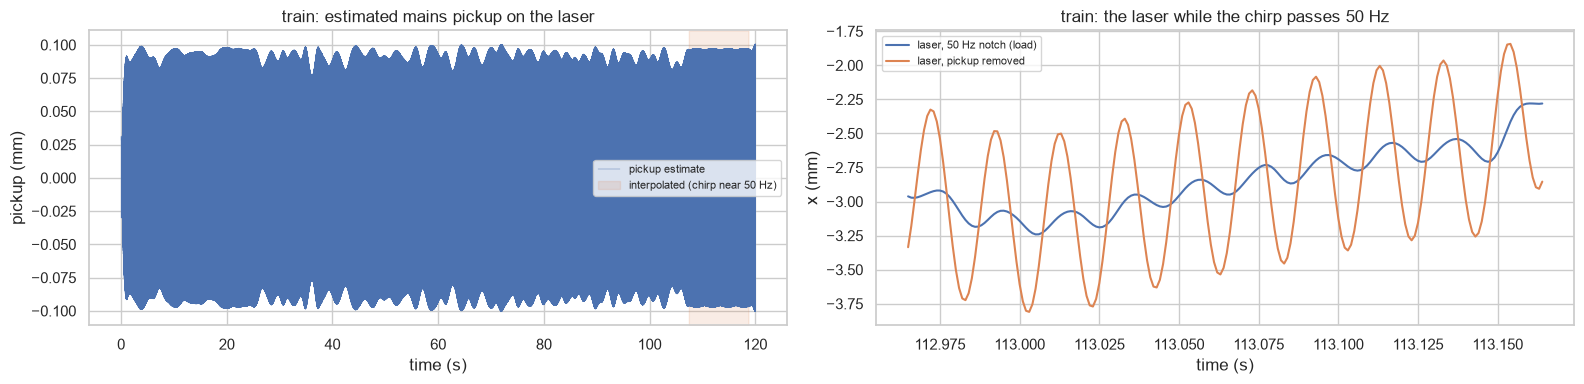

In [ ]:
F_MAINS = 50.0                                          # Hz, demodulation frequency of the pickup
BW_PICKUP = 0.5                                         # Hz, low-pass of the demodulated envelope
GAP_HZ = 4.0                                            # Hz, envelope interpolated while the chirp is this close to 50 Hz
BAND_PICKUP = (40.0, 60.0)                              # Hz, band-pass applied before demodulating


def interp_gap(y, gap):
    "Replace y inside the boolean mask gap by linear interpolation between the samples just outside it."
    k = np.arange(len(y))
    out = y.copy()
    out[gap] = np.interp(k[gap], k[~gap], y[~gap])
    return out


def remove_pickup(x, t, f_chirp):
    "Subtract the mains pickup from x (1 kHz): demodulate at F_MAINS, low-pass, interpolate over the chirp's pass of 50 Hz."
    # band-pass first: the mm-level offset and slow motion would otherwise make the zero-phase low-pass ring at the record ends
    x_band = signal.sosfiltfilt(signal.butter(4, BAND_PICKUP, btype="bandpass", fs=1 / TS, output="sos"), x)
    z = x_band * np.exp(-2j * np.pi * F_MAINS * t)
    b, a = signal.butter(2, BW_PICKUP / (0.5 / TS))
    p = 2 * (signal.filtfilt(b, a, z.real) + 1j * signal.filtfilt(b, a, z.imag))   # factor 2: a real sinusoid splits over +-f
    gap = np.abs(f_chirp - F_MAINS) < GAP_HZ
    amp, ph = interp_gap(np.abs(p), gap), interp_gap(np.unwrap(np.angle(p)), gap)
    pickup = np.real(amp * np.exp(1j * ph) * np.exp(2j * np.pi * F_MAINS * t))
    return x - pickup, pickup, gap


def load_clean_laser(split, d, tau):
    "Run d with its laser re-read from the CSV: aligned at tau, 150 Hz notch only, pickup removed; v and a recomputed."
    path = next(Path("data", split).glob("voice_coil_log_chirpsched_*.csv"))
    raw = np.loadtxt(path, delimiter=",", skiprows=2)
    t = raw[:, 0]
    x = np.interp(t + tau, t, signal.filtfilt(b_lp, a_lp, raw[:, 11] * 1e-3))   # as in load, at alignment tau
    x = signal.filtfilt(*signal.iirnotch(150.0, 30.0, fs=FS_LOG), x)          # 150 Hz only; it is above the 100 Hz low-pass band anyway
    keep = slice(np.searchsorted(t, 0.0), None, DECIM)
    s = dict(d)
    s["x"], s["pickup"], s["gap"] = remove_pickup(x[keep], t[keep], chirp_freq(split))
    s["v"] = np.gradient(s["x"], TS)
    s["a"] = s["a_x"] = np.gradient(s["v"], TS)
    return s


for split in ("train", "test"):
    SENSORS[split]["laser, cleaned"] = load_clean_laser(split, DATA["chirpsched"][split], TAU + DELTA_X)
    s = SENSORS[split]["laser, cleaned"]
    print(f"[{split:5s}] pickup amplitude {np.sqrt(2) * np.std(s['pickup'][~s['gap']]) * 1e3:.3f} mm outside the gap; "
          f"gap {s['gap'].sum() * TS:.1f} s where the chirp is within {GAP_HZ} Hz of 50 Hz")

# check: the cleaned laser equals the notched one away from 50 Hz (same processing otherwise)
_s, _n = SENSORS["train"]["laser, cleaned"], SENSORS["train"]["laser"]
_m = _n["sweep"] & (chirp_freq("train") < 30)
print(f"below 30 Hz: notched vs cleaned laser differ by {np.std(_s['x'][_m] - _n['x'][_m]) * 1e6:.1f} um rms (pickup and notch side effects)")

# residual per band for the three targets
TARGETS = ["laser", "laser, cleaned", "accelerometer"]
print(f"\n{'unexplained force std (N)':26s} | " + " | ".join(f"{lo:.0f}-{hi:.0f}" for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:])) + " | all")
for split in ("train", "test"):
    f_chirp = chirp_freq(split)
    for name in TARGETS:
        d = SENSORS[split][name]
        p, _ = fit_on(SENSORS["train"][name], BASE)       # always fitted on train
        r = M * d["a"] - design(d, slice(None), BASE, V_C0, V_ST0) @ p
        stds = [np.std(r[d["sweep"] & (f_chirp >= lo) & (f_chirp < hi)]) for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:])]
        print(f"[{split:5s}] {name:18s} | " + " | ".join(f"{s_:5.0f}" for s_ in stds) + f" | {np.std(r[d['sweep']]):4.0f}")

# figure: pickup estimate and the laser around the 50 Hz pass (train)
s, n = SENSORS["train"]["laser, cleaned"], SENSORS["train"]["laser"]
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot(s["t"], s["pickup"] * 1e3, lw=0.3, label="pickup estimate")
ax[0].fill_between(s["t"], 0, 1, where=s["gap"], transform=ax[0].get_xaxis_transform(), color="C1", alpha=0.15, label="interpolated (chirp near 50 Hz)")
ax[0].set(xlabel="time (s)", ylabel="pickup (mm)", title="train: estimated mains pickup on the laser")
t50 = s["t"][s["gap"]].mean()
m = np.abs(s["t"] - t50) < 0.1
ax[1].plot(s["t"][m], n["x"][m] * 1e3, label="laser, 50 Hz notch (load)")
ax[1].plot(s["t"][m], s["x"][m] * 1e3, label="laser, pickup removed")
ax[1].set(xlabel="time (s)", ylabel="x (mm)", title="train: the laser while the chirp passes 50 Hz")
for a_ in ax:
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading (as computed when this section was written).**

- **The pickup estimate is consistent:** 0.093 mm on both runs, the same as the 0.09–0.097 mm measured on idle laser logs (`docs/position-control.md`). Below 30 Hz the cleaned laser differs from the notched one by only a few µm.
- **The 50 Hz notch was the largest error in the application band.** With the pickup removed instead, Model C's residual at 45–55 Hz drops from about 700–770 N to 140–180 N, and over the whole sweep from 311 to 161 N (train) and from 300 to 166 N (test). That is better than with the accelerometer (207 N).
- **What remains is at 30–40 Hz** (250–310 N), around the 35 Hz resonance in the laser path.

## A linear, data-driven correction: FIR on the current

After the cleaning, Model C's remaining residual is linear and sits mostly around 30–40 Hz. This section lets the data choose the frequency response from current to force, while the rest of Model C stays as it is. The constant motor term $\Gamma\, i$ becomes a finite impulse response (FIR) filter over the last $L$ current samples:

$$m\ddot{x}_k = \sum_{j=0}^{L} h_j\, i_{k-j} \;+\; \Gamma_1 x_k\, i_k \;-\; c\,\dot{x}_k \;-\; \left(\frac{C_R}{(g_0 - x_k)^3} - \frac{C_L}{(g_0 + x_k)^3}\right)$$

It is still linear in all parameters ($h_0 \dots h_L$, $\Gamma_1$, $c$, $C_R$, $C_L$), so it is fitted with the same weighted, bounded least squares as Model C, on the cleaned laser. Its frequency response is

$$H(f) = \sum_{j=0}^{L} h_j\, e^{-j 2\pi f j T_s}, \qquad H(0) = \sum_j h_j \;\leftrightarrow\; \Gamma$$

A constant $\Gamma$ is the special case $h_0 = \Gamma$, $h_{j>0} = 0$: a flat $|H|$ with zero phase. Deviations from flat show what the constant-gain model misses, for example a gain step or phase excursion near 35 Hz from the resonance in the laser path.

**Overfitting.** Longer filters can follow finer detail, but also noise. $L$ = `FIR_LENGTHS` taps are fitted on train and judged on **test**: the residual per band, and the position NRMSE of a rollout from the measured state. The FIR only uses past *measured* currents, which a controller also knows, so it can run in a rollout or an EKF.

L (taps) | resid train resid test | test resid per band (N): 10-15 15-20 20-25 25-30 30-35 35-40 40-45 45-50 50-55 | test NRMSE k=100, 1000
       0 |         161        166 |   125   107   130   162   255   281   168   127   170 | 0.436, 0.775
       5 |         155        158 |   123   104   115   136   279   238   113   135   169 | 0.555, 0.580
      10 |         154        157 |   123   104   114   136   279   232   109   133   167 | 0.552, 0.577
      20 |         156        154 |   115   103    96   110   251   249   139   168   171 | 0.806, 0.553
      40 |         138        138 |   117    99    84   113   220   193   117   137   165 | 0.951, 0.562


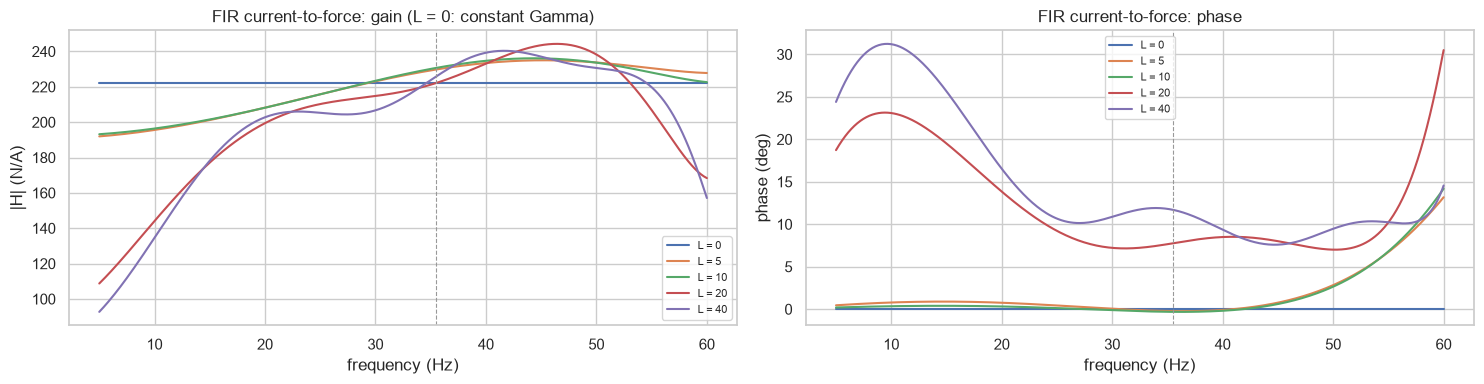

In [ ]:
FIR_LENGTHS = [0, 5, 10, 20, 40]                        # taps L (1 ms each); L = 0 is Model C with a constant Gamma
CLEAN = {split: SENSORS[split]["laser, cleaned"] for split in ("train", "test")}


def lagged(i, L):
    "Columns i(k - j) for j = 0..L (zeros before the record starts)."
    return np.column_stack([np.r_[np.zeros(j), i[:len(i) - j]] for j in range(L + 1)])


def fir_design(d, sel, L):
    "Regressors of the FIR model on samples sel: lagged currents, then Gamma1, c, C_R, C_L as in Model C."
    cols = regressors(d["x"], d["v"], d["i"], np.zeros_like(d["i"]), V_C0, V_ST0)
    A = np.column_stack([lagged(d["i"], L)] + [cols[n] for n in ("Gamma1", "c", "C_R", "C_L")])
    return A[sel]


def fit_fir(L):
    "Weighted bounded LLS of the FIR model on the cleaned train laser. Returns [h_0..h_L, Gamma1, c, C_R, C_L]."
    d = CLEAN["train"]
    sel = d["sweep"]
    A, y = fir_design(d, sel, L), M * d["a"][sel]
    w = 1 / np.abs(signal.hilbert(d["i"]))[sel]
    lb = [-np.inf] * (L + 2) + [0.0, 0.0, 0.0]          # c, C_R, C_L >= 0
    sc = np.linalg.norm(A * w[:, None], axis=0)
    return lsq_linear(A * w[:, None] / sc, y * w, bounds=(lb, np.inf)).x / sc


def rollout_fir(theta, L, d, s, H):
    "Predicted x from the measured state at each start s. The FIR motor force uses the measured currents, held over each step."
    f_motor = lagged(d["i"], L) @ theta[:L + 1]         # sum_j h_j i(k - j), known in advance
    G1, c, CR, CL = theta[L + 1:]
    x, v, out = d["x"][s], d["v"][s], [d["x"][s]]
    with np.errstate(all="ignore"):
        for k in range(H):
            fm, u = f_motor[s + k], d["i"][s + k]
            acc = lambda x, v, _u: (fm + G1 * x * u - c * v - (CR / (G00 - x)**3 - CL / (G00 + x)**3)) / M
            x, v = step(x, v, u, u, acc)
            out.append(x)
    return np.stack(out, axis=1)


# check: L = 0 is Model C (same columns, same fit) on the cleaned laser
_th = fit_fir(0)
_pc, _ = fit_on(CLEAN["train"], BASE)
assert np.allclose(_th, _pc[[0, 2, 1, 3, 4]], rtol=1e-6), (_th, _pc)

FIR = {L: fit_fir(L) for L in FIR_LENGTHS}
print(f"{'L (taps)':>8s} | {'resid train':>11s} {'resid test':>10s} | test resid per band (N): " +
      " ".join(f"{lo:.0f}-{hi:.0f}" for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:])) + " | test NRMSE k=100, 1000")
for L, th in FIR.items():
    row = []
    for split in ("train", "test"):
        d = CLEAN[split]
        r = M * d["a"] - fir_design(d, slice(None), L) @ th
        row.append((np.std(r[d["sweep"]]), r))
    d, r = CLEAN["test"], row[1][1]
    f_chirp = chirp_freq("test")
    bands = [np.std(r[d["sweep"] & (f_chirp >= lo) & (f_chirp < hi)]) for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:])]
    s = starts(d, d["sweep"], 1000)
    e = rollout_fir(th, L, d, s, 1000) - target(d, s, 1000)
    nr = np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][d["sweep"]])
    print(f"{L:8d} | {row[0][0]:11.0f} {row[1][0]:10.0f} | " + " ".join(f"{b_:5.0f}" for b_ in bands) + f" | {nr[100]:.3f}, {nr[1000]:.3f}")

# frequency response of the fitted FIRs
fg = np.linspace(5, 60, 400)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for L, th in FIR.items():
    Hf = np.exp(-2j * np.pi * np.outer(fg, np.arange(L + 1)) * TS) @ th[:L + 1]
    ax[0].plot(fg, np.abs(Hf), label=f"L = {L}")
    ax[1].plot(fg, np.degrees(np.angle(Hf)), label=f"L = {L}")
for a_ in ax:
    a_.axvline(35.5, color="0.6", ls="--", lw=0.8)
    a_.legend(fontsize=8)
ax[0].set(xlabel="frequency (Hz)", ylabel="|H| (N/A)", title="FIR current-to-force: gain (L = 0: constant Gamma)")
ax[1].set(xlabel="frequency (Hz)", ylabel="phase (deg)", title="FIR current-to-force: phase")
plt.tight_layout(); plt.show()

**Reading (as computed when this section was written).**

| Taps $L$ | Residual train / test | Test residual 30–35 / 35–40 Hz | Test NRMSE $k$ = 100 / 1000 |
|---|---|---|---|
| 0 (Model C) | 161 / 166 N | 255 / 281 N | 0.44 / 0.78 |
| 5 | 155 / 158 N | 279 / 238 N | 0.56 / 0.58 |
| 10 | 154 / 157 N | 279 / 232 N | 0.55 / 0.58 |
| 20 | 156 / 154 N | 251 / 249 N | 0.81 / 0.55 |
| 40 | 138 / 138 N | 220 / 193 N | 0.95 / 0.56 |

- **The FIR does not pay off.** The force residual improves by 5–17 %, but the 100 ms position prediction gets *worse* with every length; only the 1000 ms horizon improves.
- **The error at 30–40 Hz stays.** A correction on the *current* side cannot represent a resonance in the *laser*. That resonance changes the measured position itself, so it distorts the target $m\ddot{x}$ and the regressors $x$, $\dot{x}$ alike, and the rollout is judged against the same distorted laser.
- **So the remaining error needs a sensor-side model** (laser = mass position + a 35 Hz mode), not a richer force law. Model C with the cleaned laser ($L$ = 0) stays the best model here.

## A sensor model for the 35 Hz resonance in the laser path

The remaining error sits at 30–40 Hz, around a resonance that the laser sees and the accelerometer mostly does not (section "What is left above 35 Hz"). This section models that resonance as **sensor dynamics**: the laser reads the mass position through a linear filter $S$,

$$Y(s) = S(s)\, X(s), \qquad S(s) = \frac{s^2/\omega_z^2 + 2\zeta_z\, s/\omega_z + 1}{s^2/\omega_p^2 + 2\zeta_p\, s/\omega_p + 1}, \qquad S(0) = 1$$

a pole pair (the resonance, $f_p$, $\zeta_p$) with a zero pair ($f_z$, $\zeta_z$) that sets the gain above it. A mount that moves with the reaction force gives exactly this shape: a step in gain across $f_p$ and a phase excursion around it. $S(0) = 1$ keeps the laser's own calibration at low frequency, where the mount barely moves.

**Identification.** The accelerometer is taken as the reference for the mass motion (assumption: the resonance is in the laser path; the band fits above found only a 6 % change of $\Gamma$ on the accelerometer, against 15 % on the laser). The ratio of the cleaned laser to the accelerometer is estimated with $H_1$, with the accelerometer as input:

$$R(f) = \frac{G_{a_\text{meas}\, a_y}(f)}{G_{a_\text{meas} a_\text{meas}}(f)} \approx K\, S(j2\pi f)$$

$K$ absorbs the accelerometer's scale error. $(K, f_p, \zeta_p, f_z, \zeta_z)$ are fitted to the complex $R$ where $\gamma^2 \geq 0.99$, by nonlinear least squares on the relative error $\left|K S - R\right| / |R|$.

**Correction.** The mass position follows by inverting the sensor, $\hat{X} = S^{-1} Y$. $S^{-1}$ is applied as a **causal** digital filter (bilinear transform, prewarped at $f_p$), as a real-time filter would have to. Model C is then refitted on $\hat{x}$, and compared with the cleaned laser per band and in the rollout.

sensor model (train): K = 0.792, pole 34.82 Hz (zeta 0.039), zero 34.42 Hz (zeta 0.040); gain above / below = (f_p / f_z)^2 = 1.024
[train] relative misfit of K S to the ratio: median 4.4%, 95th percentile 7.1%
[test ] relative misfit of K S to the ratio: median 3.8%, 95th percentile 7.3%

unexplained force std (N)          | 10-15 | 15-20 | 20-25 | 25-30 | 30-35 | 35-40 | 40-45 | 45-50 | 50-55 | all | NRMSE k=100, 1000
[train] laser, cleaned             |    86 |    88 |   100 |   160 |   256 |   308 |   173 |   142 |   176 |  161 | 0.499, 0.885
[train] laser, sensor-corrected    |    84 |    85 |    97 |   175 |   283 |   173 |   102 |   139 |   178 |  145 | 0.467, 0.668
[test ] laser, cleaned             |   125 |   107 |   130 |   162 |   255 |   281 |   168 |   127 |   170 |  166 | 0.436, 0.775
[test ] laser, sensor-corrected    |   115 |   101 |   126 |   178 |   259 |   164 |   107 |   130 |   169 |  149 | 0.382, 0.551

Model C on the sensor-corrected laser: Gamma = 219.5, c = 2

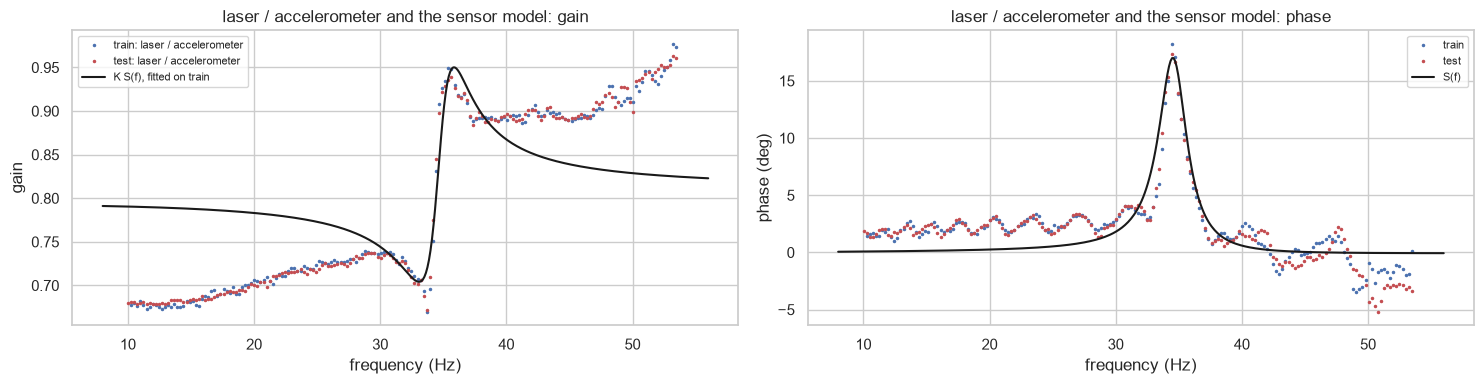

In [ ]:
from scipy.optimize import least_squares

F_FIT_S = (25.0, 45.0)                                  # Hz, band of the sensor-model fit: around the narrow feature at 33-36 Hz


def sensor_tf(f, f_p, z_p, f_z, z_z):
    "S(j 2 pi f) of the pole-zero sensor model, S(0) = 1."
    s = 2j * np.pi * f
    wz, wp = 2 * np.pi * f_z, 2 * np.pi * f_p
    return (s**2 / wz**2 + 2 * z_z * s / wz + 1) / (s**2 / wp**2 + 2 * z_p * s / wp + 1)


def laser_ratio(split):
    "H1 estimate of cleaned-laser acceleration / accelerometer on the sweep, with the coherence."
    d_l, d_a = SENSORS[split]["laser, cleaned"], SENSORS[split]["accelerometer"]
    sel = d_l["sweep"]
    f, P_aa = signal.welch(d_a["a"][sel], fs=1 / TS, nperseg=4096)
    _, P_al = signal.csd(d_a["a"][sel], d_l["a"][sel], fs=1 / TS, nperseg=4096)
    _, coh = signal.coherence(d_a["a"][sel], d_l["a"][sel], fs=1 / TS, nperseg=4096)
    return f, P_al / P_aa, coh


def fit_sensor(f, R):
    "Least-squares fit of K S(f) to the complex ratio R (relative error). Returns K, f_p, z_p, f_z, z_z."
    def res(q):
        e = (q[0] * sensor_tf(f, *q[1:]) - R) / np.abs(R)
        return np.r_[e.real, e.imag]
    q0 = [np.median(np.abs(R)), 35.0, 0.03, 33.0, 0.03]  # zero just below the pole, lightly damped (seen in the ratio)
    return least_squares(res, q0, bounds=([0, 28, 2e-3, 28, 2e-3], [np.inf, 42, 0.5, 42, 0.5])).x


def invert_sensor(y, f_p, z_p, f_z, z_z):
    "Causal digital S^-1 applied to y (bilinear transform prewarped at f_p), started at rest at y[0]."
    wz, wp = 2 * np.pi * f_z, 2 * np.pi * f_p
    num = [1 / wp**2, 2 * z_p / wp, 1]                   # S^-1 = den(S) / num(S)
    den = [1 / wz**2, 2 * z_z / wz, 1]
    # prewarping: the bilinear transform with this "fs" maps f_p exactly onto f_p in the digital filter
    fs_warp = np.pi * f_p / np.tan(np.pi * f_p * TS)
    b, a = signal.bilinear(num, den, fs=fs_warp)
    return signal.lfilter(b, a, y, zi=signal.lfilter_zi(b, a) * y[0])[0]


# 1. identify S on train, check on test
f, R, coh = laser_ratio("train")
fit_band = (f >= F_FIT_S[0]) & (f <= F_FIT_S[1]) & (coh >= COH_MODE)
K_S, *S_PAR = fit_sensor(f[fit_band], R[fit_band])
print(f"sensor model (train): K = {K_S:.3f}, pole {S_PAR[0]:.2f} Hz (zeta {S_PAR[1]:.3f}), zero {S_PAR[2]:.2f} Hz (zeta {S_PAR[3]:.3f}); "
      f"gain above / below = (f_p / f_z)^2 = {(S_PAR[0] / S_PAR[2])**2:.3f}")
for split in ("train", "test"):
    f, R, coh = laser_ratio(split)
    b_ = (f >= F_FIT_S[0]) & (f <= F_FIT_S[1]) & (coh >= COH_MODE)
    err = np.abs(K_S * sensor_tf(f[b_], *S_PAR) - R[b_]) / np.abs(R[b_])
    print(f"[{split:5s}] relative misfit of K S to the ratio: median {np.median(err):.1%}, 95th percentile {np.percentile(err, 95):.1%}")

# 2. correct the cleaned laser and refit Model C
for split in ("train", "test"):
    s = dict(SENSORS[split]["laser, cleaned"])
    s["x"] = invert_sensor(s["x"], *S_PAR)
    s["v"] = np.gradient(s["x"], TS)
    s["a"] = s["a_x"] = np.gradient(s["v"], TS)
    SENSORS[split]["laser, sensor-corrected"] = s

TARGETS = ["laser, cleaned", "laser, sensor-corrected", "accelerometer"]
print(f"\n{'unexplained force std (N)':34s} | " + " | ".join(f"{lo:.0f}-{hi:.0f}" for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:])) + " | all | NRMSE k=100, 1000")
for split in ("train", "test"):
    f_chirp = chirp_freq(split)
    for name in TARGETS[:2]:
        d = SENSORS[split][name]
        p, _ = fit_on(SENSORS["train"][name], BASE)
        r = M * d["a"] - design(d, slice(None), BASE, V_C0, V_ST0) @ p
        stds = [np.std(r[d["sweep"] & (f_chirp >= lo) & (f_chirp < hi)]) for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:])]
        nr = nrmse_curve(magnets, p, d, d["sweep"], 1000)
        print(f"[{split:5s}] {name:26s} | " + " | ".join(f"{s_:5.0f}" for s_ in stds) + f" | {np.std(r[d['sweep']]):4.0f} | {nr[100]:.3f}, {nr[1000]:.3f}")
p_corr, _ = fit_on(SENSORS["train"]["laser, sensor-corrected"], BASE)
print("\nModel C on the sensor-corrected laser: " + ", ".join(f"{n} = {v_:.4g}" for n, v_ in zip(BASE, p_corr)))

# figure: ratio and fit
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
fg = np.linspace(8, 56, 400)
for split, color in (("train", "C0"), ("test", "C3")):
    f, R, coh = laser_ratio(split)
    m = (f >= 8) & (f <= 56)
    ok = np.where(coh[m] >= COH_MODE, 1.0, np.nan)
    ax[0].plot(f[m], np.abs(R[m]) * ok, ".", ms=3, color=color, label=f"{split}: laser / accelerometer")
    ax[1].plot(f[m], np.degrees(np.angle(R[m])) * ok, ".", ms=3, color=color, label=split)
ax[0].plot(fg, np.abs(K_S * sensor_tf(fg, *S_PAR)), "k-", label="K S(f), fitted on train")
ax[1].plot(fg, np.degrees(np.angle(sensor_tf(fg, *S_PAR))), "k-", label="S(f)")
ax[0].set(xlabel="frequency (Hz)", ylabel="gain", title="laser / accelerometer and the sensor model: gain")
ax[1].set(xlabel="frequency (Hz)", ylabel="phase (deg)", title="laser / accelerometer and the sensor model: phase")
for a_ in ax:
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading (as computed when this section was written).**

- **The resonance is narrow:** a zero at 34.4 Hz just below a pole at 34.8 Hz, both lightly damped ($\zeta \approx 0.04$). $K S$ fits the measured laser/accelerometer ratio within 4 % (median) and 7 % (95th percentile), on train and on test alike.
- **Correcting the laser with $S^{-1}$ improves every test metric:**

| Test run | Residual, all | 35–40 Hz | 40–45 Hz | NRMSE $k$ = 100 | NRMSE $k$ = 1000 |
|---|---|---|---|---|---|
| cleaned laser | 166 N | 281 N | 168 N | 0.44 | 0.78 |
| cleaned + sensor-corrected | 149 N | 164 N | 107 N | 0.38 | 0.55 |

- **Not captured:** the slower gain step of the ratio, from about 0.73 below 33 Hz to 0.89 above 37 Hz. $K$ sits between the two levels, and 30–35 Hz stays at about 260 N. A second, broader pole–zero pair could take it, or the step could be the accelerometer's own response. This data does not separate the two.
- **Caution on the parameters:** with the corrected laser, Model C's $\Gamma_1$, $C_R$ and $C_L$ shift a lot (for example $C_R$ from 0.0016 in Method C to 0.0011 N·m³), although $S \approx 1$ at low frequency. These parameters are correlated in the fit; check them on other runs before using them.

### Sensor model with a second, broader pair

The narrow pair does not capture the slower gain step of the ratio (about 0.73 below 33 Hz, 0.89 above 37 Hz). A second pole–zero pair, broader and with its zero below its pole, gives such a step, because above both, $|S| \to (f_p/f_z)^2$:

$$S_2(s) = S_\text{narrow}(s)\; S_\text{broad}(s), \qquad \left|S_\text{broad}\right| \xrightarrow{\;f \gg f_{p2}\;} \left(\frac{f_{p2}}{f_{z2}}\right)^2 \approx \frac{0.89}{0.73}$$

All nine parameters ($K$ and two pairs) are fitted on 10–55 Hz, starting from the narrow fit above. The laser is corrected with $S_2^{-1}$ (both pairs inverted causally, one after the other) and Model C is refitted as before.

two-pair sensor model (train): K = 0.698; narrow pole 34.64 Hz (zeta 0.020), zero 34.44 Hz (zeta 0.021); broad pole 56.21 Hz (zeta 0.303), zero 60.00 Hz (zeta 0.404)
[train] one pair : relative misfit 10-55 Hz median 7.6%, 95th percentile 17.0%
[train] two pairs: relative misfit 10-55 Hz median 3.6%, 95th percentile 6.4%
[test ] one pair : relative misfit 10-55 Hz median 8.0%, 95th percentile 16.4%
[test ] two pairs: relative misfit 10-55 Hz median 3.4%, 95th percentile 6.2%

unexplained force std (N)            | 10-15 | 15-20 | 20-25 | 25-30 | 30-35 | 35-40 | 40-45 | 45-50 | 50-55 | all | NRMSE k=100, 1000
[train] laser, sensor-corrected      |    84 |    85 |    97 |   175 |   283 |   173 |   102 |   139 |   178 |  145 | 0.467, 0.668
[train] laser, two-pair corrected    |    80 |    85 |   110 |   189 |   232 |   154 |   118 |   200 |   392 |  168 | 0.669, 0.672
[test ] laser, sensor-corrected      |   115 |   101 |   126 |   178 |   259 |   164 |   107 |   130 |   169 |  149 | 0.38

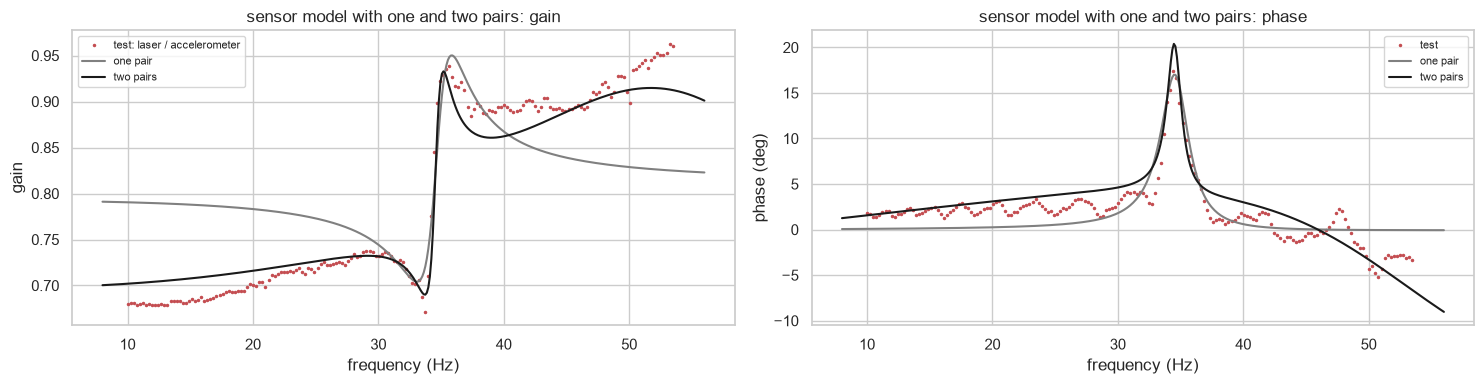

In [ ]:
F_FIT_S2 = (10.0, 55.0)                                 # Hz, band of the two-pair fit


def sensor2_tf(f, q):
    "S of the two-pair model; q = [f_p, z_p, f_z, z_z] narrow, then the same for the broad pair."
    return sensor_tf(f, *q[:4]) * sensor_tf(f, *q[4:])


def fit_sensor2(f, R, q_narrow):
    "Fit K S_2 to the complex ratio R (relative error), starting from the narrow pair and a broad step 0.73 -> 0.89."
    def res(q):
        e = (q[0] * sensor2_tf(f, q[1:]) - R) / np.abs(R)
        return np.r_[e.real, e.imag]
    q0 = [0.73, *q_narrow, 35.4, 0.2, 32.0, 0.2]       # broad: f_p / f_z = sqrt(0.89 / 0.73)
    lb = [0, 28, 2e-3, 28, 2e-3, 15, 0.02, 15, 0.02]
    ub = [np.inf, 42, 0.5, 42, 0.5, 60, 1.5, 60, 1.5]
    return least_squares(res, q0, bounds=(lb, ub)).x


f, R, coh = laser_ratio("train")
band2 = (f >= F_FIT_S2[0]) & (f <= F_FIT_S2[1]) & (coh >= COH_MODE)
K_S2, *S2_PAR = fit_sensor2(f[band2], R[band2], S_PAR)
print(f"two-pair sensor model (train): K = {K_S2:.3f}; narrow pole {S2_PAR[0]:.2f} Hz (zeta {S2_PAR[1]:.3f}), zero {S2_PAR[2]:.2f} Hz (zeta {S2_PAR[3]:.3f}); "
      f"broad pole {S2_PAR[4]:.2f} Hz (zeta {S2_PAR[5]:.3f}), zero {S2_PAR[6]:.2f} Hz (zeta {S2_PAR[7]:.3f})")
for split in ("train", "test"):
    f, R, coh = laser_ratio(split)
    b_ = (f >= F_FIT_S2[0]) & (f <= F_FIT_S2[1]) & (coh >= COH_MODE)
    for name, model in (("one pair", K_S * sensor_tf(f[b_], *S_PAR)), ("two pairs", K_S2 * sensor2_tf(f[b_], S2_PAR))):
        err = np.abs(model - R[b_]) / np.abs(R[b_])
        print(f"[{split:5s}] {name:9s}: relative misfit 10-55 Hz median {np.median(err):.1%}, 95th percentile {np.percentile(err, 95):.1%}")

for split in ("train", "test"):
    s = dict(SENSORS[split]["laser, cleaned"])
    s["x"] = invert_sensor(invert_sensor(s["x"], *S2_PAR[:4]), *S2_PAR[4:])
    s["v"] = np.gradient(s["x"], TS)
    s["a"] = s["a_x"] = np.gradient(s["v"], TS)
    SENSORS[split]["laser, two-pair corrected"] = s


def band_table(names):
    "Model C fitted on train per target; unexplained force std per band and rollout NRMSE, on train and test."
    print(f"\n{'unexplained force std (N)':36s} | " + " | ".join(f"{lo:.0f}-{hi:.0f}" for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:])) + " | all | NRMSE k=100, 1000")
    for split in ("train", "test"):
        f_chirp = chirp_freq(split)
        for name in names:
            d = SENSORS[split][name]
            p, _ = fit_on(SENSORS["train"][name], BASE)
            r = M * d["a"] - design(d, slice(None), BASE, V_C0, V_ST0) @ p
            stds = [np.std(r[d["sweep"] & (f_chirp >= lo) & (f_chirp < hi)]) for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:])]
            nr = nrmse_curve(magnets, p, d, d["sweep"], 1000)
            print(f"[{split:5s}] {name:28s} | " + " | ".join(f"{s_:5.0f}" for s_ in stds) + f" | {np.std(r[d['sweep']]):4.0f} | {nr[100]:.3f}, {nr[1000]:.3f}")


band_table(["laser, sensor-corrected", "laser, two-pair corrected"])

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
fg = np.linspace(8, 56, 400)
f, R, coh = laser_ratio("test")
m = (f >= 8) & (f <= 56)
ok = np.where(coh[m] >= COH_MODE, 1.0, np.nan)
ax[0].plot(f[m], np.abs(R[m]) * ok, ".", ms=3, color="C3", label="test: laser / accelerometer")
ax[1].plot(f[m], np.degrees(np.angle(R[m])) * ok, ".", ms=3, color="C3", label="test")
for name, Sf, color in (("one pair", K_S * sensor_tf(fg, *S_PAR), "0.5"), ("two pairs", K_S2 * sensor2_tf(fg, S2_PAR), "k")):
    ax[0].plot(fg, np.abs(Sf), color=color, label=name)
    ax[1].plot(fg, np.degrees(np.angle(Sf)), color=color, label=name)
ax[0].set(xlabel="frequency (Hz)", ylabel="gain", title="sensor model with one and two pairs: gain")
ax[1].set(xlabel="frequency (Hz)", ylabel="phase (deg)", title="sensor model with one and two pairs: phase")
for a_ in ax:
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading (as computed when this section was written).** The second pair fits the ratio better (median misfit over 10–55 Hz 3.4 % instead of 8.0 % on test), but its broad pair runs to the bound (pole 56 Hz, zero at the 60 Hz limit) instead of describing the step at 33–37 Hz. Correcting the laser with it makes the model **worse** on test: 50–55 Hz 169 → 369 N, NRMSE $k$ = 100 0.38 → 0.54. The slow gain step is therefore not a second resonance of this form in the laser; it may be the accelerometer's own response. The one-pair correction stays in use.

## Grey box + ML: a learned correction on top of Model C

Model C stays the physical core. A learned term $g_\psi$ adds the force it still misses:

$$m\ddot{x}_k = \underbrace{(\Gamma + \Gamma_1 x_k)\, i_k - c\,\dot{x}_k - F_\text{mag}(x_k)}_{\text{Model C}} \;+\; g_\psi\!\left(x_k,\, \dot{x}_k,\, i_k, i_{k-1}, \dots, i_{k-L}\right)$$

- **Inputs:** position, velocity and the last $L$ = `N_LAG` current samples (30 ms, about one period at 35 Hz), so $g_\psi$ can represent gain and phase errors at the excitation frequency as well as nonlinear ones.
- **Target:** Model C's residual force on the train sweep, $r_k = m\ddot{x}_k - \text{Model C}_k$, on the corrected laser (`ML_TARGET`). Model C itself is fitted first and then kept fixed.
- **Three learners**, from simple to flexible:
  - ridge regression (linear in the inputs: an FIR on the current plus terms in $x$, $\dot{x}$);
  - gradient-boosted trees (`HistGradientBoostingRegressor`);
  - a small neural network (`MLPRegressor`, two hidden layers).
- **Judged on the test run only:** the unexplained force per band, and the position NRMSE of a rollout in which $g_\psi$ runs inside every RK4 stage. A learner that only fits noise or the train run shows up as a worse test rollout.

The learned term only uses quantities a real-time filter also has (its own $x$, $\dot{x}$ and the past measured currents), so a model that wins here could later run inside the EKF.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

N_LAG = 30                                              # past current samples (1 ms each) given to the learner
ML_TARGET = "laser, sensor-corrected"                   # data the learner is trained and judged on (one-pair correction, the best so far)
ML_STRIDE = 2                                           # every 2nd train sample, to keep training quick


def ml_features(x, v, I_lag):
    "Learner inputs: x (mm), v (mm/s) and the lagged currents (A) in one matrix."
    return np.column_stack([x * 1e3, v * 1e3, I_lag])


def c_force(p, x, v, u):
    "Model C force (N) for parameters p = [Gamma, c, Gamma1, C_R, C_L]."
    return (p[0] + p[2] * x) * u - p[1] * v - (p[3] / (G00 - x)**3 - p[4] / (G00 + x)**3)


def rollout_ml(p, model, d, s, H):
    "Predicted x from the measured state at each start s; Model C plus the learned force, evaluated in every RK4 stage."
    I_lag = lagged(d["i"], N_LAG)
    x, v, out = d["x"][s], d["v"][s], [d["x"][s]]
    with np.errstate(all="ignore"):
        for k in range(H):
            u, Ik = d["i"][s + k], I_lag[s + k]
            def acc(x, v, _u):
                g = model.predict(ml_features(np.nan_to_num(x), np.nan_to_num(v), Ik)) if model is not None else 0.0
                return (c_force(p, x, v, u) + g) / M
            x, v = step(x, v, u, u, acc)
            x, v = np.where(np.abs(x) < 0.02, x, np.nan), np.where(np.abs(x) < 0.02, v, np.nan)   # diverged: beyond the 20 mm gap
            out.append(x)
    return np.stack(out, axis=1)


def nrmse_ml(p, model, d, H=1000):
    "Position NRMSE against horizon on the sweep, as nrmse_curve."
    s = starts(d, d["sweep"], H)
    e = rollout_ml(p, model, d, s, H) - target(d, s, H)
    return np.sqrt(np.nanmean(e ** 2, axis=0)) / np.std(d["x"][d["sweep"]]), np.mean(np.isnan(e[:, -1]))


# Model C on the target data, then its residual as the learner's target
D_ML = {split: SENSORS[split][ML_TARGET] for split in ("train", "test")}
p_ml, _ = fit_on(D_ML["train"], BASE)
XY = {}
for split, d in D_ML.items():
    sel = d["sweep"]
    X = ml_features(d["x"], d["v"], lagged(d["i"], N_LAG))[sel]
    y = (M * d["a"] - c_force(p_ml, d["x"], d["v"], d["i"]))[sel]
    XY[split] = (X, y)

LEARNERS = {
    "ridge (linear)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "boosted trees": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, random_state=0),
    "neural net": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 64), alpha=1e-3, early_stopping=True,
                                                               max_iter=200, random_state=0)),
}
X_tr, y_tr = XY["train"]
for name, model in LEARNERS.items():
    model.fit(X_tr[::ML_STRIDE], y_tr[::ML_STRIDE])

# force residual per band (test) and rollout NRMSE, against Model C alone
f_chirp = chirp_freq("test")
d = D_ML["test"]
sel = d["sweep"]
X_te, y_te = XY["test"]
print(f"{'model on ' + ML_TARGET:40s} | resid train, test | test resid per band (N): " + " ".join(f"{lo:.0f}-{hi:.0f}" for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:]))
      + " | test NRMSE k=100, 1000 | diverged")
for name, model in [("Model C alone", None)] + list(LEARNERS.items()):
    r_tr = y_tr - (model.predict(X_tr) if model is not None else 0.0)
    r_te = y_te - (model.predict(X_te) if model is not None else 0.0)
    r_full = np.full(len(d["x"]), np.nan)
    r_full[sel] = r_te
    bands = [np.nanstd(r_full[sel & (f_chirp >= lo) & (f_chirp < hi)]) for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:])]
    nr, div = nrmse_ml(p_ml, model, d)
    print(f"{name:40s} | {np.std(r_tr):5.0f} {np.std(r_te):5.0f}     | " + " ".join(f"{b_:5.0f}" for b_ in bands)
          + f" | {nr[100]:.3f}, {nr[1000]:.3f} | {div:.0%}")

model on laser, sensor-corrected         | resid train, test | test resid per band (N): 10-15 15-20 20-25 25-30 30-35 35-40 40-45 45-50 50-55 | test NRMSE k=100, 1000 | diverged
Model C alone                            |   145   149     |   115   101   126   178   259   164   107   130   169 | 0.382, 0.551 | 0%
ridge (linear)                           |   107   114     |   122    93    96   111   140   111   114   110   140 | 1.343, 2.837 | 0%


**Reading (as computed when this section was written; test run, laser cleaned and sensor-corrected).**

| On top of Model C | Unexplained force | 25–30 / 30–35 Hz | NRMSE $k$ = 100 | NRMSE $k$ = 1000 |
|---|---|---|---|---|
| nothing (Model C alone) | 149 N | 178 / 259 N | 0.38 | 0.55 |
| ridge (linear) | 114 N | 111 / 140 N | 1.34 | 2.84 |
| boosted trees | 95 N | 79 / 113 N | **0.31** | **0.35** |
| neural net | 88 N | 79 / 94 N | 1.00 | 3.99 |

- **Boosted trees are the only learner that improves the model as a simulator.** On the test run, every metric gets better: force, every band, and both horizons.
- **The best force fit is not the best model.** The neural net and ridge reduce the force error but make the rollout worse: inside the RK4 loop their small errors feed back through $x$, $\dot{x}$ and grow. The trees' output is bounded (piecewise constant, never outside what was seen in training), which keeps the loop well-behaved.
- **Caveats:**
  - it is trained on one run and tested on a second run of the *same* experiment (scheduled chirp); how it does on other excitation (PRBS, closed-loop runs) is untested;
  - its output is piecewise constant in $x$ and $\dot{x}$, which an EKF Jacobian would have to work around.

## Two-body model, identified in the frequency domain

The laser/accelerometer ratio has a zero just below a pole near 34 Hz. That is the fingerprint of **two connected bodies**: the reaction force of the motor also shakes the structure the laser is mounted on. This section tests that physical picture against the sensor-filter view, in the frequency domain, where the gain and phase errors per frequency are visible directly.

**Measured frequency responses.** From the scheduled chirp, current to laser position and current to accelerometer ($H_1$ estimator, current as input, $\gamma^2 \geq 0.99$):

$$\hat{H}_y(f) = \frac{G_{iy}(f)}{G_{ii}(f)}, \qquad \hat{H}_a(f) = \frac{G_{i a_\text{meas}}(f)}{G_{ii}(f)}$$

The laser is the cleaned one (pickup removed, no 50 Hz notch), aligned with `TAU` from cell 1. The accelerometer is aligned with `TAU_ACC`. The remaining common delay $\tau$ is a model parameter.

**Rigid model** (Model C linearised about $x = 0$, $k = 3(C_R + C_L)/g_0^4$):

$$\frac{X}{I}(s) = \frac{\Gamma\, e^{-s\tau}}{m s^2 + c s + k}, \qquad \frac{Y}{I} = \frac{X}{I}, \qquad \frac{A_\text{meas}}{I} = K_a\, s^2 \frac{X}{I}$$

**Two-body model.** The laser's mount (or the frame) $w$ is a second mode ($f_w$, $\zeta_w$), driven by a share $\mu$ of the motor force; the laser reads the mass relative to its mount, $y = x - w$:

$$\frac{W}{I}(s) = \frac{\mu\,\Gamma\, e^{-s\tau}}{m\left(s^2 + 2\zeta_w\omega_w s + \omega_w^2\right)}, \qquad \frac{Y}{I} = \frac{X}{I} - \frac{W}{I}$$

For $\mu < 0$ this gives a zero just below $f_w$, as measured, and above both a gain step of

$$\left|\frac{Y}{X}\right| \xrightarrow{\;f \gg f_w\;} 1 + |\mu| = \left(\frac{f_p}{f_z}\right)^2$$

So one mode ties the size of the step to the distance between zero and pole. A narrow feature (zero and pole 0.4 Hz apart) can only give a small step. The fit shows whether the measured step (about 22 %) fits this picture.

**Fit.** Both responses together, by least squares on the relative complex error over 10–55 Hz. Parameters: $\Gamma, c, k, \tau, K_a$, plus $\mu, f_w, \zeta_w$ for the two-body model. $K_a$ takes the accelerometer's scale error.

In [ ]:
F_FRF = (10.0, 55.0)                                    # Hz, band of the frequency-response fit
COH_FRF = 0.99


def frf(u, y, sel, nperseg=4096):
    "H1 estimate of y / u on the samples sel, with the coherence."
    f, P_uu = signal.welch(u[sel], fs=1 / TS, nperseg=nperseg)
    _, P_uy = signal.csd(u[sel], y[sel], fs=1 / TS, nperseg=nperseg)
    _, coh = signal.coherence(u[sel], y[sel], fs=1 / TS, nperseg=nperseg)
    return f, P_uy / P_uu, coh


def measured_frfs(split):
    "Current -> cleaned laser position and current -> accelerometer, on the sweep (laser at TAU, accelerometer at TAU_ACC)."
    d = DATA["chirpsched"][split]
    lz = load_clean_laser(split, d, TAU)
    f, Hy, cy = frf(d["i"], lz["x"], d["sweep"])
    _, Ha, ca = frf(d["i"], d["a_meas"], d["sweep"])
    ok = (f >= F_FRF[0]) & (f <= F_FRF[1]) & (cy >= COH_FRF) & (ca >= COH_FRF)
    return f[ok], Hy[ok], Ha[ok]


def model_frfs(f, q, two_body):
    "Model responses Y/I and A_meas/I. q = [Gamma, c, k, tau, K_a] (+ [mu, f_w, zeta_w] for the two-body model)."
    G, c, k, tau, Ka = q[:5]
    s = 2j * np.pi * f
    X = G * np.exp(-s * tau) / (M * s**2 + c * s + k)
    Y = X
    if two_body:
        mu, f_w, z_w = q[5:]
        w_w = 2 * np.pi * f_w
        Y = X - mu * G * np.exp(-s * tau) / (M * (s**2 + 2 * z_w * w_w * s + w_w**2))
    return Y, Ka * s**2 * X


def fit_frfs(f, Hy, Ha, two_body):
    "Least squares on the relative complex error of both responses together."
    def res(q):
        Y, A = model_frfs(f, q, two_body)
        e = np.r_[(Y - Hy) / np.abs(Hy), (A - Ha) / np.abs(Ha)]
        return np.r_[e.real, e.imag]
    q0 = [p_C[0], p_C[1], 3 * (p_C[3] + p_C[4]) / G00**4, 1.1e-3, 1.0]
    lb, ub = [0, 0, 0, -5e-3, 0], [np.inf, np.inf, np.inf, 5e-3, np.inf]
    if two_body:
        q0, lb, ub = q0 + [-0.05, 34.6, 0.03], lb + [-1.0, 20.0, 1e-3], ub + [1.0, 50.0, 0.5]
    r = least_squares(res, q0, bounds=(lb, ub), x_scale=np.abs(q0) + 1e-3)
    return r.x


FRF = {split: measured_frfs(split) for split in ("train", "test")}
f_tr, Hy_tr, Ha_tr = FRF["train"]
Q_FRF = {name: fit_frfs(f_tr, Hy_tr, Ha_tr, tb) for name, tb in (("rigid", False), ("two-body", True))}
for name, q in Q_FRF.items():
    txt = f"Gamma {q[0]:.1f} N/A, c {q[1]:.0f} N s/m, k {q[2]:.3g} N/m, tau {q[3] * 1e3:.2f} ms, K_a {q[4]:.3f}"
    if name == "two-body":
        txt += f"; mu {q[5]:+.4f}, f_w {q[6]:.2f} Hz, zeta_w {q[7]:.3f} -> step 1 + |mu| = {1 + abs(q[5]):.3f}"
    print(f"{name:8s}: {txt}")
    for split, (f, Hy, Ha) in FRF.items():
        Y, A = model_frfs(f, q, name == "two-body")
        ey, ea = np.abs(Y - Hy) / np.abs(Hy), np.abs(A - Ha) / np.abs(Ha)
        hf = f >= 30
        print(f"   [{split:5s}] relative misfit laser: median {np.median(ey):.1%} (>= 30 Hz {np.median(ey[hf]):.1%}); "
              f"accelerometer: median {np.median(ea):.1%} (>= 30 Hz {np.median(ea[hf]):.1%})")

# where the models miss: measured / rigid fit per band, both sensors (test)
f, Hy, Ha = FRF["test"]
Yr, Ar = model_frfs(f, Q_FRF["rigid"], False)
print()
print(f"{'test, measured / rigid fit':26s} | {'laser gain':>10s} {'phase':>7s} | {'accel gain':>10s} {'phase':>7s}")
for lo in np.arange(10, 55, 5.0):
    m = (f >= lo) & (f < lo + 5)
    if m.any():
        gy, py = np.median(np.abs(Hy[m] / Yr[m])), np.degrees(np.median(np.angle(Hy[m] / Yr[m])))
        ga, pa = np.median(np.abs(Ha[m] / Ar[m])), np.degrees(np.median(np.angle(Ha[m] / Ar[m])))
        print(f"{lo:5.0f}-{lo + 5:<5.0f} Hz{'':13s} | {gy:10.3f} {py:+7.1f} | {ga:10.3f} {pa:+7.1f}")

# figure: measured responses (test) against both fits, gain relative to the rigid model to make the errors visible
f, Hy, Ha = FRF["test"]
fig, ax = plt.subplots(2, 2, figsize=(16, 7), sharex=True)
Yr, Ar = model_frfs(f, Q_FRF["rigid"], False)
for col, (H, ref, label) in enumerate(((Hy, Yr, "current -> laser"), (Ha, Ar, "current -> accelerometer"))):
    ax[0, col].plot(f, np.abs(H / ref), ".", ms=3, color="C3", label="measured (test) / rigid fit")
    ax[1, col].plot(f, np.degrees(np.angle(H / ref)), ".", ms=3, color="C3", label="measured (test) / rigid fit")
    Y2, A2 = model_frfs(f, Q_FRF["two-body"], True)
    m2 = Y2 if col == 0 else A2
    ax[0, col].plot(f, np.abs(m2 / ref), "k-", label="two-body fit / rigid fit")
    ax[1, col].plot(f, np.degrees(np.angle(m2 / ref)), "k-", label="two-body fit / rigid fit")
    ax[0, col].set(ylabel="gain relative to rigid fit", title=label)
    ax[1, col].set(xlabel="frequency (Hz)", ylabel="phase relative to rigid fit (deg)")
for row, level in ((0, 1.0), (1, 0.0)):                # reference: gain 1, phase 0 = the rigid fit itself
    for a_ in ax[row]:
        a_.axhline(level, color="0.6", lw=0.8)
        a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

### The laser alone

The table above shows that the **accelerometer is not a flat reference**. Relative to the rigid fit, its gain falls smoothly by about 25 % from 10 to 55 Hz while its phase drifts from −6° to +6°. The laser is flat below 30 Hz and only shows the feature at 34–35 Hz. So the earlier laser/accelerometer ratio mixed the laser's mode with the accelerometer's own slope.

The models are therefore refitted on the laser response $\hat{H}_y$ alone (the calibrated, absolute sensor), with the same relative complex error. Two starting points for the mode are tried: narrow, and a wide one with a 10 % step ($\mu = -0.1$).

In [ ]:
def fit_laser_only(f, Hy, two_body, q_start):
    "Fit the model's Y/I to the laser response alone (relative complex error); K_a is not used."
    def res(q):
        Y, _ = model_frfs(f, np.r_[q[:4], 1.0, q[4:]], two_body)
        e = (Y - Hy) / np.abs(Hy)
        return np.r_[e.real, e.imag]
    q0 = list(q_start)
    lb, ub = [0, 0, 0, -5e-3], [np.inf, np.inf, np.inf, 5e-3]
    if two_body:
        lb, ub = lb + [-1.0, 20.0, 1e-3], ub + [1.0, 50.0, 0.5]
    return least_squares(res, q0, bounds=(lb, ub), x_scale=np.abs(q0) + 1e-3).x

QL = {}
for name, tb, q0 in (("rigid", False, Q_FRF["rigid"][:4]),
                     ("two-body, narrow start", True, [*Q_FRF["rigid"][:4], -0.01, 34.8, 0.02]),
                     ("two-body, wide start", True, [*Q_FRF["rigid"][:4], -0.10, 35.1, 0.02])):
    q = fit_laser_only(f_tr, Hy_tr, tb, q0)
    QL[name] = q
    txt = f"Gamma {q[0]:.1f}, c {q[1]:.0f}, k {q[2]:.3g}, tau {q[3] * 1e3:.2f} ms"
    if tb:
        f_z = q[5] / np.sqrt(1 + abs(q[4]))
        txt += f"; mu {q[4]:+.4f}, pole {q[5]:.2f} Hz (zeta {q[6]:.3f}), zero ~{f_z:.2f} Hz"
    out = []
    for split, (f, Hy, Ha) in FRF.items():
        Y, _ = model_frfs(f, np.r_[q[:4], 1.0, q[4:]], tb)
        e = np.abs(Y - Hy) / np.abs(Hy)
        out.append(f"{split} median {np.median(e):.1%}, >=30 Hz {np.median(e[f >= 30]):.1%}, 95% {np.percentile(e, 95):.1%}")
    print(f"{name:24s}: {txt}\n     " + " | ".join(out))

**Reading (as computed when this section was written).**

- **Both responses together:** the two-body model finds the mode at 34.84 Hz ($\zeta_w$ = 0.02), but with $\mu = -0.010$, a step of only 1 %. It lowers the laser misfit a little (test median 8.4 → 7.2 %) and leaves the accelerometer unchanged (12 %).
- **Which sensor carries what** (test, measured ÷ rigid fit):
  - the laser is flat at 0.99–1.00 up to 30 Hz, dips to 0.97 at 30–35 Hz and sits 4–12 % higher above 35 Hz;
  - the accelerometer has no step, but falls smoothly from 1.17 at 10 Hz to 0.88 at 55 Hz, with its phase drifting from −6° to +6.5°;
  - so the accelerometer has a frequency response of its own and is not a flat reference. The earlier sensor-model fits against the laser/accelerometer ratio were biased by it.
- **The laser alone:** both starting points converge to the same narrow mode (pole 34.87 Hz, zero 34.71 Hz, $\zeta$ = 0.02). Above 30 Hz it lowers the misfit from 6.1 to 3.7 % (test median), and the 95th percentile from 18 to 13 %.
- **Caution:** the rigid laser-only fit drives $k$ to zero. 10–55 Hz is far above the 4–5 Hz spring resonance, so the spring is not identifiable from this band. Take $k$ from the time-domain fits, and use this section for the high-frequency behaviour.

## Current-loop lag instead of a pure delay

The alignment found a common delay of about 1.1 ms between the logged current and the force. Part of it could be the drive's current loop, which acts as a first-order lag and not as a pure delay. The two have different phase signatures: a delay costs phase in proportion to $f$, a lag costs $\arctan(2\pi f \tau_c)$, which bends over. The laser-only two-body fit is repeated with both in the motor force:

$$F(s) = \Gamma\, \frac{e^{-s\tau}}{1 + s\tau_c}\, I(s), \qquad \tau, \tau_c \geq 0$$

If the data prefer $\tau_c > 0$ with a smaller $\tau$, the misfit falls; if $\tau_c \to 0$, a pure delay is enough.

In [ ]:
def fit_laser_lag(f, Hy, q_start):
    "Laser-only two-body fit with a first-order lag 1 / (1 + s tau_c) in the motor force. q = [Gamma, c, k, tau, mu, f_w, z_w, tau_c]."
    def model(q, f):
        Y, _ = model_frfs(f, np.r_[q[:4], 1.0, q[4:7]], True)
        return Y / (1 + 2j * np.pi * f * q[7])
    def res(q):
        e = (model(q, f) - Hy) / np.abs(Hy)
        return np.r_[e.real, e.imag]
    lb = [0, 0, 0, 0.0, -1.0, 20.0, 1e-3, 0.0]
    ub = [np.inf, np.inf, np.inf, 5e-3, 1.0, 50.0, 0.5, 5e-3]
    q = least_squares(res, q_start, bounds=(lb, ub), x_scale=np.abs(q_start) + 1e-4).x
    return q, model


q_tb = QL["two-body, narrow start"]
for tau_c0 in (0.2e-3, 0.6e-3):                         # two starting points for the lag
    q_lag, model_lag = fit_laser_lag(f_tr, Hy_tr, [*q_tb, tau_c0])
    out = []
    for split, (f, Hy, Ha) in FRF.items():
        e = np.abs(model_lag(q_lag, f) - Hy) / np.abs(Hy)
        out.append(f"{split} median {np.median(e):.1%}, >=30 Hz {np.median(e[f >= 30]):.1%}")
    print(f"start tau_c {tau_c0 * 1e3:.1f} ms -> delay tau {q_lag[3] * 1e3:.2f} ms, lag tau_c {q_lag[7] * 1e3:.2f} ms "
          f"(current-loop bandwidth {1 / (2 * np.pi * max(q_lag[7], 1e-9)):.0f} Hz); Gamma {q_lag[0]:.1f}, c {q_lag[1]:.0f} | " + " | ".join(out))
for split, (f, Hy, Ha) in FRF.items():
    Y, _ = model_frfs(f, np.r_[q_tb[:4], 1.0, q_tb[4:]], True)
    e = np.abs(Y - Hy) / np.abs(Hy)
    print(f"   reference, pure delay only: {split} median {np.median(e):.1%}, >=30 Hz {np.median(e[f >= 30]):.1%}")

**Reading (as computed when this section was written).** From both starting points the lag goes to $\tau_c$ = 0, with the delay unchanged at $\tau$ = 1.14 ms (on top of `TAU`), and the misfit exactly as with the pure delay (test: median 6.1 %, ≥ 30 Hz 3.7 %). A first-order current-loop lag does not describe the data better: **a pure delay is enough.** Its cause (the drive's timing, the readback, or force build-up) is not resolved by this.

## Does the motor constant depend on the current amplitude?

The scheduled chirp ramps the current amplitude from about 3 to 15 A. If the motor saturates, $\Gamma$ falls at high current; that would be a real nonlinearity, and a candidate for a $\Gamma(i)$ term (or for what the learner picked up). In the scheduled chirp, amplitude and frequency rise together, so both go into the regression.

**Method.** In windows of `WIN_AMP` s, only $\Gamma$ is refitted (the other Model C parameters fixed at their least-squares values on the corrected laser):

$$m\ddot{x} - \left(\Gamma_1 x\, i - c\,\dot{x} - F_\text{mag}(x)\right) = \Gamma_w\, i \quad \text{in window } w$$

Then the window values are regressed on the window's current amplitude $\bar{I}_w$ (Hilbert envelope) and chirp frequency $\bar{f}_w$:

$$\Gamma_w = \gamma_0 + \gamma_I\, \bar{I}_w + \gamma_f\, \bar{f}_w$$

Saturation would show as $\gamma_I < 0$, beyond its uncertainty. Windows near the 34–35 Hz mode (32–37 Hz) are left out, because the mode moves the apparent $\Gamma$ there.

In [ ]:
WIN_AMP = 1.0                                           # s, window for the per-window Gamma
F_SKIP = (32.0, 37.0)                                   # Hz, windows left out around the laser mode

rows = []
for split in ("train", "test"):
    d = SENSORS[split]["laser, sensor-corrected"]
    p, _ = fit_on(SENSORS["train"]["laser, sensor-corrected"], BASE)
    f_chirp, env = chirp_freq(split), np.abs(signal.hilbert(d["i"]))
    rest = M * d["a"] - (p[2] * d["x"] * d["i"] - p[1] * d["v"] - (p[3] / (G00 - d["x"])**3 - p[4] / (G00 + d["x"])**3))
    idx = np.flatnonzero(d["sweep"])
    win = int(round(WIN_AMP / TS))
    for k0 in range(0, len(idx) - win + 1, win):
        k = idx[k0:k0 + win]
        if F_SKIP[0] <= f_chirp[k].mean() <= F_SKIP[1]:
            continue
        G_w = np.dot(d["i"][k], rest[k]) / np.dot(d["i"][k], d["i"][k])   # least squares Gamma in the window
        rows.append((split, G_w, env[k].mean(), f_chirp[k].mean()))

for split in ("train", "test"):
    R_ = np.array([r_[1:] for r_ in rows if r_[0] == split])
    A = np.column_stack([np.ones(len(R_)), R_[:, 1], R_[:, 2]])
    coef, res_, *_ = np.linalg.lstsq(A, R_[:, 0], rcond=None)
    sigma2 = np.sum((R_[:, 0] - A @ coef) ** 2) / (len(R_) - 3)
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(A.T @ A)))   # naive: neighbouring windows are correlated
    print(f"[{split:5s}] {len(R_)} windows, amplitude {R_[:, 1].min():.1f}-{R_[:, 1].max():.1f} A: "
          f"Gamma = {coef[0]:.1f} {coef[1]:+.2f} (+-{se[1]:.2f}) N/A per A {coef[2]:+.2f} (+-{se[2]:.2f}) N/A per Hz; "
          f"over the amplitude range: {coef[1] * (R_[:, 1].max() - R_[:, 1].min()):+.1f} N/A")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for split, color in (("train", "C0"), ("test", "C3")):
    R_ = np.array([r_[1:] for r_ in rows if r_[0] == split])
    ax[0].scatter(R_[:, 1], R_[:, 0], s=8, color=color, label=split)
    ax[1].scatter(R_[:, 2], R_[:, 0], s=8, color=color, label=split)
ax[0].set(xlabel="current amplitude (A)", ylabel="Γ in the window (N/A)", title="per-window Γ against current amplitude")
ax[1].set(xlabel="chirp frequency (Hz)", ylabel="Γ in the window (N/A)", title="per-window Γ against frequency")
for a_ in ax:
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading (as computed when this section was written).**

| Run | $\gamma_I$ (N/A per A) | Effect over the amplitude range | $\gamma_f$ (N/A per Hz) |
|---|---|---|---|
| train (2–15 A) | +2.36 ± 0.54 | +31 N/A | −0.68 ± 0.22 |
| test (3–14 A) | +0.90 ± 0.37 | +10 N/A | −0.68 ± 0.13 |

- **No saturation:** $\Gamma$ does not fall at high current on either run.
- **The amplitude slope is not robust:** it is positive on both runs, but the two values differ by a factor 2.6, more than their (naive, too small) uncertainties allow. So it is not a consistent property of the motor; in the scheduled chirp, amplitude also changes in steps over time, which other slow effects can mimic.
- **The frequency trend is consistent:** −0.68 N/A per Hz on both runs, about −30 N/A over 10–55 Hz. That is the linear frequency-response error found earlier (the remaining gain error per frequency), not a nonlinearity.
- **No $\Gamma(i)$ term is warranted** by this data.

## Fitting on the prediction error instead of the force error

All fits so far minimise the **equation error**: the force residual on $m\ddot{x}$, where $\ddot{x}$ is the laser differentiated twice. Differentiating twice multiplies noise and errors at frequency $f$ by $(2\pi f)^2$, so the least-squares fit is pulled hardest by the high-frequency end, exactly where the measurement is least reliable. The models are judged instead on the **simulation (output) error**: the position predicted $H$ steps ahead from the measured state.

This section fits Model C directly on that criterion, with the notebook's `fit()` (H-step rollout, `H_FIT` = 500 steps = 0.5 s):

$$\hat\theta = \arg\min_{\theta} \sum_{s} \sum_{k=1}^{H} \left(\hat{x}_{s+k \mid s}(\theta) - x_{s+k}\right)^2$$

- **Data:** the cleaned, sensor-corrected laser.
- **Start:** the least-squares values. **Bounds:** $c \geq 0$, $C_R, C_L \geq 0$.
- **Two variants:** all five parameters free, and the magnet spring ($C_R$, $C_L$) fixed at the least-squares values with only $\Gamma$, $c$, $\Gamma_1$ free. The sweep starts at 10 Hz, well above the 4–5 Hz spring resonance, so the spring is barely visible in it; a free spring can drift to values that would be wrong at 1–10 Hz, where the position controller works.
- Every `ROLL_THIN`-th start of the sweep is used, to keep the fit fast.
- **Judged on the test run:** position NRMSE, and the force residual. The force residual may get *worse* while the prediction gets better: that is the trade-off between the two criteria.

In [ ]:
ROLL_THIN = 5                                           # use every ROLL_THIN-th start (on top of STRIDE) in the rollout fit
D_RF = {split: SENSORS[split]["laser, sensor-corrected"] for split in ("train", "test")}

p_lls, _ = fit_on(D_RF["train"], BASE)
band_thin = D_RF["train"]["sweep"] & (np.arange(len(D_RF["train"]["x"])) % ROLL_THIN == 0)
lb_rf = [-np.inf, 0.0, -np.inf, 0.0, 0.0]               # Gamma, c, Gamma1, C_R, C_L
p_roll = fit(magnets, p_lls, D_RF["train"], band_thin, lb=lb_rf)                  # all five free
p_roll_k = fit(magnets, p_lls, D_RF["train"], band_thin, lb=lb_rf[:3], free=slice(0, 3))   # spring fixed at least squares

print(f"\n{'':22s} | " + " ".join(f"{n:>9s}" for n in BASE) + " | force resid train, test | test NRMSE k=100, 500, 1000")
for name, p in (("least squares (force)", p_lls), ("rollout fit, all free", p_roll), ("rollout, spring fixed", p_roll_k)):
    fr = [np.std((M * d["a"] - design(d, slice(None), BASE, V_C0, V_ST0) @ p)[d["sweep"]]) for d in D_RF.values()]
    nr = nrmse_curve(magnets, p, D_RF["test"], D_RF["test"]["sweep"], 1000)
    print(f"{name:22s} | " + " ".join(f"{v_:9.4g}" for v_ in p) + f" | {fr[0]:5.0f} {fr[1]:5.0f}            | {nr[100]:.3f}, {nr[500]:.3f}, {nr[1000]:.3f}")

**Reading (as computed when this section was written; test run).**

| Fit | $\Gamma$ | $c$ | $C_R$ (N·m³) | Force residual | NRMSE $k$ = 100 / 500 / 1000 |
|---|---|---|---|---|---|
| least squares (force) | 219.5 | 2460 | 0.00110 | 149 N | 0.38 / 0.55 / 0.55 |
| rollout fit, all free | 231.8 | 3413 | 0.00012 | 246 N | **0.27 / 0.38 / 0.46** |
| rollout fit, spring fixed | 260.9 | 5374 | 0.00110 (fixed) | 522 N | 0.40 / 0.56 / 0.59 |

- **The rollout fit predicts much better on the sweep, but only by weakening the magnet spring about 10×** (spring resonance from about 3.6 to about 1.2 Hz). With the spring fixed, it is no better than least squares and needs twice the damping.
- **The sweep cannot decide which spring is right:** it starts at 10 Hz, far above the spring resonance. The position controller works at 1–10 Hz, where the spring matters most. The next section therefore checks both on the plain chirp (1–55 Hz), which covers that range.

## Validation on runs no fit has seen

All fits above used the train run of the scheduled chirp (10–55 Hz), and were judged on its test run. This section checks the candidates on two other kinds of excitation:

- **plain chirp, test run (2 Oct, 6 A, 1–55 Hz):** it reaches down to 1 Hz, so it shows whether the strong spring (least squares) or the weak one (rollout fit) is right. It is split into 1–10, 10–30 and 30–55 Hz;
- **PRBS (23 Sep, 5 A, ±16 mm):** broadband and far outside the ±6 mm of the fit data, so an extrapolation test.

The laser is processed exactly as for the fits: aligned at the best `TAU`, mains pickup removed (no gap for PRBS, which has no chirp), and the 34.8 Hz sensor resonance inverted. Candidates:

| Candidate | Model | Data it was fitted on |
|---|---|---|
| Method C (cell 13) | shared notebook | laser with 50 Hz notch, `TAU` = 0.65 ms |
| C, least squares | Model C | cleaned + corrected laser |
| C, rollout fit (weak spring) | Model C | cleaned + corrected laser |
| C + boosted trees | Model C + learned force | cleaned + corrected laser |

The criterion is the position NRMSE at $k$ = 100 and 500 steps (0.1 and 0.5 s), from every `STRIDE_VAL`-th start in each band.

In [ ]:
STRIDE_VAL = 3                                          # extra thinning of the starts, for speed
H_VAL = 500


def load_clean_any(path, d, tau, f_chirp):
    "As load_clean_laser, for any log: laser re-read at alignment tau, pickup removed (gap where f_chirp is near 50 Hz), sensor inverted."
    raw = np.loadtxt(path, delimiter=",", skiprows=2)
    t = raw[:, 0]
    x = np.interp(t + tau, t, signal.filtfilt(b_lp, a_lp, raw[:, 11] * 1e-3))
    x = signal.filtfilt(*signal.iirnotch(150.0, 30.0, fs=FS_LOG), x)
    keep = slice(np.searchsorted(t, 0.0), None, DECIM)
    s = dict(d)
    x_c, _, _ = remove_pickup(x[keep], t[keep], f_chirp)
    s["x"] = invert_sensor(x_c, *S_PAR)
    s["v"] = np.gradient(s["x"], TS)
    s["a"] = s["a_x"] = np.gradient(s["v"], TS)
    return s


def chirp_freq_path(path, t):
    "Chirp frequency from the file name, or zeros when the name has no chirp (PRBS: no pickup gap)."
    m = re.search(r"_([\d.]+)to([\d.]+)Hz_([\d.]+)s_", path.name)
    if not m:
        return np.zeros_like(t)
    f0, f1, T = map(float, m.groups())
    return f0 * (f1 / f0) ** (t / T)


def nrmse_band(roll, d, band, H):
    "Position NRMSE at k = 100 and H over the starts in band (thinned)."
    s = starts(d, band, H)[::STRIDE_VAL]
    e = roll(d, s, H) - target(d, s, H)
    nr = np.sqrt(np.nanmean(e ** 2, axis=0)) / np.std(d["x"][band])
    return nr[100], nr[H], np.mean(np.isnan(e[:, -1]))


p_tree = LEARNERS["boosted trees"]
CANDIDATES = {
    "Method C (cell 13)": ("raw", lambda d, s, H: rollout(magnets, p_C, d, s, H)),
    "C, least squares": ("clean", lambda d, s, H: rollout(magnets, p_lls, d, s, H)),
    "C, rollout fit (weak spring)": ("clean", lambda d, s, H: rollout(magnets, p_roll, d, s, H)),
    "C + boosted trees": ("clean", lambda d, s, H: rollout_ml(p_ml, p_tree, d, s, H)),
}
RUNS_VAL = [("plain chirp test", next(Path("data", "test").glob("voice_coil_log_chirp_*.csv")), DATA["chirp"]["test"]),
            ("PRBS (23 Sep)", next(Path("data").glob("voice_coil_log_prbs_*.csv")), None)]

print(f"{'position NRMSE k = 100 / ' + str(H_VAL):34s} | " + " | ".join(f"{n:>28s}" for n in CANDIDATES))
for run_name, path, d_raw in RUNS_VAL:
    d_raw = d_raw if d_raw is not None else load(path)
    f_run = chirp_freq_path(path, d_raw["t"])
    d_clean = load_clean_any(path, d_raw, TAU + DELTA_X, f_run)
    if f_run.any():
        bands = {f"{lo:.0f}-{hi:.0f} Hz": (f_run >= lo) & (f_run < hi) & (d_raw["t"] <= d_raw["t"][-1] - T_CUT)
                 for lo, hi in ((1, 10), (10, 30), (30, 55))}
    else:
        bands = {"whole run": d_raw["t"] > 1.0}
    for band_name, band in bands.items():
        cells_ = []
        for name, (data_kind, roll) in CANDIDATES.items():
            d = d_raw if data_kind == "raw" else d_clean
            n100, nH, div = nrmse_band(roll, d, band, H_VAL)
            cells_.append(f"{n100:6.3f} / {nH:6.3f}" + (f" ({div:.0%} div)" if div > 0 else ""))
        print(f"{run_name + ', ' + band_name:34s} | " + " | ".join(f"{c_:>28s}" for c_ in cells_))

> **Correction (found later, section "Model E"):** the laser clips at +19.76 mm (the end of its range) for about 6 s on each plain-chirp run. This table includes those samples. With them masked and 0.5 s clip-free windows, Model C (least squares) does not diverge at 1–10 Hz (NRMSE 0.54 / 0.66). Those windows mostly exclude the largest strokes, though: with 0.1 s clip-free windows, which can start close to them, Model C still diverges (section "Validation plots"). So the divergence below is partly the clipped measurement and partly real: Model C does fail at large stroke.

**Reading (as computed when this section was written).**

| NRMSE $k$ = 100 / 500 | Method C (cell 13) | C, least squares | C, rollout fit (weak spring) | C + boosted trees |
|---|---|---|---|---|
| plain chirp, 1–10 Hz | diverges | diverges (115 / 154) | **0.27 / 0.24** | 0.65 / 0.60 |
| plain chirp, 10–30 Hz | 0.51 / 0.41 | 0.36 / 0.43 | **0.33 / 0.39** | 0.37 / 0.46 |
| plain chirp, 30–55 Hz | 1.96 / 1.97 | 1.25 / 1.90 | **0.55 / 0.93** | 1.45 / 1.66 |
| PRBS, ±16 mm | 0.79 / 0.72 | 0.50 / 0.49 | **0.38 / 0.45** | 0.56 / 0.54 |

- **The models with the strong magnet spring diverge at 1–10 Hz, including the shared Method C.** The next cell shows why: the mass moves ±21 mm there, almost the full 22.3 mm gap, while all fits used ±6 mm.
- **The weak-spring rollout fit is the best on every row,** but for the wrong reason (next cell). It does not blow up at large stroke, yet it is not the true spring.
- **The boosted trees do not transfer:** on other excitation they are worse than plain Model C with the weak spring. What they learned is specific to the scheduled chirp.
- **30–55 Hz on the plain chirp:** at constant 6 A the motion there is small and the laser noisy, which inflates the NRMSE of all models.

### The plain chirp at 1–10 Hz: a large-stroke test

The frequency response from current to (cleaned, corrected) laser position on the plain chirp, below 12 Hz. If the spring were linear, a second-order system $X/I = \Gamma / (k - m\omega^2 + j c\omega)$ would show the resonance at $f_n = \frac{1}{2\pi}\sqrt{k/m}$, with phase −90° there: about 3.6 Hz for the least-squares spring, about 1.2 Hz for the weak one.

In [ ]:
for split in ("train", "test"):
    path = next(Path("data", split).glob("voice_coil_log_chirp_*.csv"))
    d0 = DATA["chirp"][split]
    f_run = chirp_freq_path(path, d0["t"])
    d = load_clean_any(path, d0, TAU + DELTA_X, f_run)
    sel = (f_run >= 0.8) & (f_run <= 12)
    f, Hx, coh = frf(d["i"], d["x"], sel, nperseg=8192)
    m = (f >= 0.8) & (f <= 12)
    k = np.argmax(np.abs(Hx[m]))
    print(f"[{split}] {path.name[:70]}")
    print(f"   x amplitude in 1-10 Hz: {np.percentile(np.abs(d['x'][sel]), 99) * 1e3:.1f} mm (99th pct); peak |X/I| at {f[m][k]:.2f} Hz")
    for fb in (1.0, 1.2, 1.5, 2, 2.5, 3, 3.6, 4.5, 6, 8, 10):
        j = np.argmin(np.abs(f - fb))
        print(f"   {f[j]:5.2f} Hz: |X/I| {np.abs(Hx[j]) * 1e3:7.3f} mm/A, phase {np.degrees(np.angle(Hx[j])):+7.1f} deg, coh {coh[j]:.3f}")

> **Correction (found later, section "Model E"):** this frequency response includes the samples where the laser clips at +19.76 mm, which lowers the measured gain. The comparison of gains below is therefore not reliable; the clip-free fits in the Model E section replace it.

**Reading (as computed when this section was written).**

- **The stroke is ±21 mm** (99th percentile of $|x|$, both runs), close to the full 22.3 mm gap.
- **There is no sharp resonance:** $|X/I|$ is flat at about 3.6–3.9 mm/A from 1 to 4.5 Hz and falls above. The phase passes −90° between 3.5 and 4.5 Hz, which fits a resonance near 4 Hz: the strong spring (Method C 3.9·10⁴, least squares 2.6·10⁴ N/m), **not** the weak one (2.9·10³ N/m, 1.2 Hz).
- **But the gain is too low for a linear model with these values.** At 1 Hz, $\Gamma = 220$ N/A, $k \approx 3.3\cdot10^4$ N/m and $c \approx 2900$ N·s/m would give about 6 mm/A, against the measured 3.6–3.9 mm/A.
- **The likely cause is the motor at large stroke.** The datasheet motor constant $K_f(z) = 283 - 0.0198\,z - 0.578\,z^2$ falls to 0.93 of its centre value at 6 mm, 0.80 at 10 mm, 0.54 at 15 mm and 0.18 at 20 mm. Model C's $\Gamma(x) = \Gamma + \Gamma_1 x$ is linear, fitted on ±6 mm, and misses that fall-off; its 1/gap³ spring also grows steeply near the gap.
- **Consequence:**
  - the models here are valid for small stroke (the ±6 mm of the fit data; the position references run at ±2–3 mm);
  - large-stroke behaviour needs a $\Gamma(x)$ with the quadratic fall-off, and a spring identified at large stroke;
  - the weak-spring rollout fit wins at large stroke only because it does not blow up there.

## Model E: valid over the full stroke

The models so far were fitted on ±6 mm and diverge at the ±21 mm of the plain chirp. Model E is fitted on both regimes together:

- **scheduled chirp, train** (10–55 Hz, ±6 mm): high frequency, small stroke;
- **plain chirp, train** (1–55 Hz, 6.5 A, ±21 mm): low frequency, large stroke.

Both are processed as before (alignment at the best `TAU`, pickup removed, 34.8 Hz sensor resonance inverted).

**Laser range limit.** On the plain chirp the laser reading sits at exactly +19.76 mm for about 6 s per run (the same value on both runs; the negative side reaches −21 to −22 mm without such a plateau). That is the end of the laser's measuring range, not an end stop: while it is clipped, the laser shows the mass at rest although it moves, and the derived $\dot{x}$, $\ddot{x}$ are wrong. Samples within `CLIP_MARGIN_MM` of the clip are therefore masked, widened by `CLIP_DILATE_S` on both sides (the low-pass, the derivatives and the sensor inversion spread the error in time). The fits use only unmasked samples, and the validation only prediction windows that are free of clipping over their whole horizon. Each run gets the same total weight in the fit, so the longer or louder one does not dominate.

**Motor constant with fall-off.** The datasheet shows $K_f$ falling quadratically with stroke, so

$$\Gamma(x) = \Gamma_0 + \Gamma_1 x + \Gamma_2 x^2 \qquad (\text{datasheet shape: } \Gamma_2/\Gamma_0 = -0.578/283 \text{ per mm}^2 = -2.04\cdot10^3\ \text{m}^{-2})$$

**Spring, two forms:**

| Variant | Spring $F_s(x)$ | Parameters |
|---|---|---|
| E0 (reference) | Model C: $\frac{C_R}{(g_0-x)^3} - \frac{C_L}{(g_0+x)^3}$, $g_0$ = 22.3 mm, linear $\Gamma(x)$ | as Model C |
| E1 | polynomial: $k_1 x + k_2 x^2 + k_3 x^3 + k_4 x^4 + k_5 x^5$ | $k_1 \dots k_5$, $k_5 \geq 0$ |
| E2 | magnets with the gap free: $\frac{C_R}{(g-x)^3} - \frac{C_L}{(g+x)^3}$ | $C_R, C_L \geq 0$; $g$ by grid search |

E1 makes no assumption about the gap; E2 keeps the physics of two repelling magnets but lets the effective gap differ from the measured 22.3 mm. All variants are linear in their parameters for fixed $g$, so they are fitted by the same weighted least squares as Model C:

$$m\ddot{x} = (\Gamma_0 + \Gamma_1 x + \Gamma_2 x^2)\, i - c\,\dot{x} - F_s(x)$$

**Validation** on runs not used in the fit: plain chirp test (1–10, 10–30, 30–55 Hz), scheduled chirp test, and PRBS (±16 mm), by position NRMSE at 100 and 500 steps.

In [ ]:
G_GRID = np.r_[np.arange(22.5, 40.0, 0.5), np.arange(40.0, 150.01, 5.0)] * 1e-3   # m, effective magnet gap for E2 (coarser above 40 mm)
SPRING_POLY = ["k1", "k2", "k3", "k4", "k5"]


X_CLIP_MM = 19.76                                       # mm, upper end of the laser's range (a plateau in both plain-chirp runs)
CLIP_MARGIN_MM = 0.3                                    # mm, samples this close to the clip are masked
CLIP_DILATE_S = 0.05                                    # s, mask widened on both sides


def clip_valid(path, d):
    "True where the laser is not clipped, on d's 1 kHz time base: clip in the raw 2 kHz log, decimated as in load, widened by CLIP_DILATE_S."
    raw = np.loadtxt(path, delimiter=",", skiprows=2)
    t = raw[:, 0]
    clipped = raw[:, 11] >= X_CLIP_MM - CLIP_MARGIN_MM
    keep = slice(np.searchsorted(t, 0.0), None, DECIM)
    c = clipped[keep][:len(d["t"])].astype(float)
    n = int(round(CLIP_DILATE_S / TS))
    return np.convolve(c, np.ones(2 * n + 1), mode="same") == 0


def with_clip_mask(path, d):
    "Add d['valid'] (laser not clipped) to a cleaned run."
    d["valid"] = clip_valid(path, d)
    return d


def run_clean(split, exp):
    "Cleaned, sensor-corrected laser of DATA[exp][split], with its clip mask and its fit mask (sweep, or the plain chirp up to T_CUT before its end)."
    path = next(Path("data", split).glob(f"voice_coil_log_{exp}_*.csv"))
    d0 = DATA[exp][split]
    d = with_clip_mask(path, load_clean_any(path, d0, TAU + DELTA_X, chirp_freq_path(path, d0["t"])))
    span = d0["sweep"] if exp == "chirpsched" else (d0["t"] > 1.0) & (d0["t"] <= d0["t"][-1] - T_CUT)
    d["fit"] = span & d["valid"]
    print(f"{exp} {split}: {np.mean(~d['valid'][span]):.1%} of the fit span masked as clipped")
    return d


def columns_E(d, sel, variant, g=G00):
    "Regressor columns of Model E on samples sel (m a = columns . theta), and their lower bounds."
    x, v, i = d["x"][sel], d["v"][sel], d["i"][sel]
    cols = {"Gamma": i, "c": -v, "Gamma1": x * i}
    if variant != "E0":
        cols["Gamma2"] = x**2 * i
    if variant == "E1":
        cols.update({k_: -x**n for n, k_ in enumerate(SPRING_POLY, start=1)})
    else:
        gap = G00 if variant == "E0" else g
        cols.update({"C_R": -1 / (gap - x)**3, "C_L": 1 / (gap + x)**3})
    lb = [0.0 if n_ in ("c", "C_R", "C_L", "k5") else -np.inf for n_ in cols]
    return cols, lb


def fit_E(runs, variant, g=G00):
    "Weighted LLS on all runs together; each run scaled to the same total weight. Returns names, theta, weighted cost."
    A_, y_, w_ = [], [], []
    for d in runs:
        sel = d["fit"]
        cols, lb = columns_E(d, sel, variant, g)
        w = 1 / np.abs(signal.hilbert(d["i"]))[sel]
        A, y = np.column_stack(list(cols.values())), M * d["a"][sel]
        w = w / np.sqrt(np.sum((w * y) ** 2))           # same total weight per run
        A_.append(A * w[:, None]); y_.append(y * w)
    A, y = np.vstack(A_), np.concatenate(y_)
    sc = np.linalg.norm(A, axis=0)
    r = lsq_linear(A / sc, y, bounds=(lb, np.inf))
    return list(cols), r.x / sc, 2 * r.cost


def spring_E(names, th, g):
    "Force function Fs(x, u, q) for rollout, q = theta[2:]: spring minus the position-dependent part of Gamma(x) i."
    q_names = names[2:]
    def Fs(x, u, q):
        Q = dict(zip(q_names, q))
        F = -(Q["Gamma1"] * x + Q.get("Gamma2", 0.0) * x**2) * u
        if "k1" in Q:
            F = F + sum(Q[k_] * x**n for n, k_ in enumerate(SPRING_POLY, start=1))
        else:
            F = F + Q["C_R"] / (g - x)**3 - Q["C_L"] / (g + x)**3
        return F
    return Fs


TRAIN_E = [run_clean("train", "chirpsched"), run_clean("train", "chirp")]
for d in TRAIN_E:
    print(f"fit run: |x| 99th percentile {np.percentile(np.abs(d['x'][d['fit']]), 99) * 1e3:.1f} mm, max {np.abs(d['x'][d['fit']]).max() * 1e3:.1f} mm")

MODELS_E = {}
for variant in ("E0", "E1"):
    names, th, _ = fit_E(TRAIN_E, variant)
    MODELS_E[variant] = (names, th, G00)
costs = [fit_E(TRAIN_E, "E2", g)[2] for g in G_GRID]
g_best = G_GRID[int(np.argmin(costs))]
names, th, _ = fit_E(TRAIN_E, "E2", g_best)
MODELS_E["E2"] = (names, th, g_best)
print(f"E2: best effective gap g = {g_best * 1e3:.1f} mm (grid {G_GRID[0] * 1e3:.1f}-{G_GRID[-1] * 1e3:.1f} mm; measured 22.3 mm)")

for variant, (names, th, g) in MODELS_E.items():
    Q = dict(zip(names, th))
    txt = ", ".join(f"{n_} = {v_:.4g}" for n_, v_ in Q.items())
    shape = ""
    if "Gamma2" in Q:
        rel = lambda z: (Q["Gamma"] + Q["Gamma1"] * z + Q["Gamma2"] * z**2) / Q["Gamma"]
        shape = "; Gamma(x)/Gamma0 at -20, -10, +10, +20 mm: " + ", ".join(f"{rel(z):.2f}" for z in (-20e-3, -10e-3, 10e-3, 20e-3))
    print(f"{variant}: {txt}{shape}")
print("datasheet K_f/283 at -20, -10, +10, +20 mm: " + ", ".join(f"{s_ds(z):.2f}" for z in (-20e-3, -10e-3, 10e-3, 20e-3)))

In [ ]:
VAL_E = {"plain chirp test": run_clean("test", "chirp"), "scheduled chirp test": run_clean("test", "chirpsched")}
_prbs_path = next(Path("data").glob("voice_coil_log_prbs_*.csv"))
_prbs_raw = load(_prbs_path)
VAL_E["PRBS (23 Sep)"] = with_clip_mask(_prbs_path, load_clean_any(_prbs_path, _prbs_raw, TAU + DELTA_X, chirp_freq_path(_prbs_path, _prbs_raw["t"])))


def nrmse_valid(Fs, p, d, band, H):
    "Position NRMSE at k = 100 and H, over starts in band whose whole horizon is clip-free (thinned by STRIDE_VAL)."
    s = starts(d, band & d["valid"], H)
    bad = np.r_[0, np.cumsum(~d["valid"])]
    s = s[bad[s + H + 1] - bad[s] == 0][::STRIDE_VAL]
    if len(s) == 0:
        return np.nan, np.nan, len(s)
    e = rollout(Fs, p, d, s, H) - target(d, s, H)
    nr = np.sqrt(np.nanmean(e ** 2, axis=0)) / np.std(d["x"][band & d["valid"]])
    return nr[100], nr[H], len(s)


def bands_E(name, d):
    "Validation bands of a run: by chirp frequency for the plain chirp, the sweep for the scheduled chirp, the whole PRBS run."
    if name == "plain chirp test":
        f_run = chirp_freq_path(next(Path("data", "test").glob("voice_coil_log_chirp_*.csv")), d["t"])
        keep = d["t"] <= d["t"][-1] - T_CUT
        return {f"{lo:.0f}-{hi:.0f} Hz": (f_run >= lo) & (f_run < hi) & keep for lo, hi in ((1, 10), (10, 30), (30, 55))}
    if name == "scheduled chirp test":
        return {"sweep": d["sweep"]}
    return {"whole run": d["t"] > 1.0}


CAND_E = {"C, least squares (sweep only)": (magnets, p_lls),
          "C, rollout fit (weak spring)": (magnets, p_roll)}
for variant, (names, th, g) in MODELS_E.items():
    CAND_E[variant] = (spring_E(names, th, g), th)

print(f"{'NRMSE k = 100 / ' + str(H_VAL) + ' (starts)':38s} | " + " | ".join(f"{n_:>30s}" for n_ in CAND_E))
for run_name, d in VAL_E.items():
    for band_name, band in bands_E(run_name, d).items():
        cells_ = []
        for name, (Fs, p) in CAND_E.items():
            n100, nH, n_starts = nrmse_valid(Fs, p, d, band, H_VAL)
            ok = np.isfinite(n100) and n100 < 10
            cells_.append((f"{n100:6.3f} / {nH:6.3f}" if ok else "diverges") + f" ({n_starts})")
        print(f"{run_name + ', ' + band_name:38s} | " + " | ".join(f"{c_:>30s}" for c_ in cells_))

**Reading (as computed when this section was written; only prediction windows free of laser clipping).**

| NRMSE $k$ = 100 / 500 | C, least squares (sweep only) | C, rollout fit (weak spring) | E0 | E1 | E2 |
|---|---|---|---|---|---|
| plain chirp test, 1–10 Hz | 0.54 / 0.66 | 0.53 / 0.36 | 1.11 / 1.70 | 0.28 / 0.33 | **0.26 / 0.26** |
| plain chirp test, 10–30 Hz | 0.36 / 0.43 | 0.33 / 0.39 | 0.97 / 4.32 | **0.22 / 0.36** | 0.24 / 0.47 |
| plain chirp test, 30–55 Hz | 1.25 / 1.90 | **0.55 / 0.93** | 1.61 / 6.96 | 1.38 / 2.06 | 1.79 / 3.26 |
| scheduled chirp test | 0.38 / 0.55 | **0.27 / 0.39** | 1.21 / 6.02 | 0.38 / 0.55 | 0.44 / 0.81 |
| PRBS (±16 mm) | 0.50 / 0.45 | 0.39 / 0.47 | diverges | 0.35 / 0.50 | **0.21 / 0.24** |

- **About 31 % of the plain-chirp train run is masked** (20 % of the test run) because the laser is clipped there.
- **Model C's 1/gap³ spring at 22.3 mm does not fit large stroke (E0):** refitted on both runs, $C_L \to 0$ and the predictions get worse everywhere.
- **E2, with the gap free, settles at an effective gap of 65 mm.** That makes the magnet spring nearly linear over the stroke ($k \approx 1.8\cdot10^4$ N/m at $x = 0$, resonance about 3 Hz). Its motor constant falls off with stroke to 0.28 (−20 mm) and 0.55 (+20 mm) of the centre value; the datasheet gives 0.18 on both sides.
- **E2 is the best model at large stroke and on broadband excitation:** PRBS 0.21 / 0.24 against 0.50 / 0.45 for Model C.
- **At high frequency the weak-spring rollout fit stays best** (30–55 Hz and the scheduled chirp). No single model wins everywhere yet. Fitting E2's structure on the prediction error, over both runs, is the natural next step.

### Model E2 fitted on the prediction error

E2 is best at low frequency and large stroke, and the rollout fit made Model C best at high frequency. This combines the two: E2's structure (quadratic $\Gamma(x)$, magnets at the effective gap $g$ = 65 mm), with its parameters refined on the **position prediction error**, over both training runs together:

$$\hat\theta = \arg\min_{\theta} \sum_{\text{runs } r} \frac{1}{\sigma_{x,r}^2} \sum_{s \in \mathcal{S}_r} \sum_{k=1}^{H} \left(\hat{x}_{s+k\mid s}(\theta) - x_{s+k}\right)^2$$

- **Starts $\mathcal{S}_r$:** only those whose whole horizon is free of laser clipping, thinned by `ROLL_THIN_E`.
- **Weighting:** each run's errors are divided by its own position spread $\sigma_{x,r}$ and by $\sqrt{|\mathcal{S}_r|}$, so each run weighs the same: the ±21 mm run does not outweigh the ±6 mm run by size, and the scheduled chirp (more clip-free starts) does not outweigh the plain chirp by count.
- **Two structures:** E2 (magnets, effective gap 65 mm) and E1 (polynomial spring up to $x^5$). E1 can be soft near the centre and stiff at large stroke; E2's nearly linear magnets cannot. If E1 then does well in every band, the conflict between low and high frequency is a stiffness that depends on **amplitude**; if not, it depends on **frequency** and needs extra dynamics.
- **Start values and bounds:** the start is the least-squares E2, and $c, C_R, C_L \geq 0$; $g$ stays fixed.

The result is validated on the same runs and bands as above.

In [ ]:
ROLL_THIN_E = 5                                         # extra thinning of the starts in the rollout fit


def clip_free_starts(d, band, H, thin):
    "Starts in band whose whole H-step horizon is clip-free, thinned."
    s = starts(d, band & d["valid"], H)
    bad = np.r_[0, np.cumsum(~d["valid"])]
    return s[bad[s + H + 1] - bad[s] == 0][::thin]


def fit_rollout_multi(Fs, p0, runs, lb):
    "H_FIT-step rollout fit over several runs together; each run weighs the same (error divided by its position std and the root of its number of starts)."
    sets = [(d, clip_free_starts(d, d["fit"], H_FIT, ROLL_THIN_E), np.std(d["x"][d["fit"]])) for d in runs]
    targets = [target(d, s, H_FIT)[:, 1:] for d, s, _ in sets]
    def res(q):
        out = []
        for (d, s, sig), X in zip(sets, targets):
            xp = np.nan_to_num(rollout(Fs, q, d, s, H_FIT)[:, 1:], nan=1.0, posinf=1.0, neginf=-1.0)   # diverged -> 1 m
            out.append(((xp - X) / (sig * np.sqrt(len(s)))).ravel())   # per run: divided by its position std and its number of starts
        return np.concatenate(out)
    r = least_squares(res, p0, x_scale=np.abs(p0) + 1e-12, bounds=(lb, np.inf))
    print(f"{r.message} ({r.nfev} evaluations); starts per run: " + ", ".join(str(len(s)) for _, s, _ in sets))
    return r.x


names_E2, th_E2, g_E2 = MODELS_E["E2"]
Fs_E2 = spring_E(names_E2, th_E2, g_E2)
lb_E2 = [0.0 if n_ in ("c", "C_R", "C_L") else -np.inf for n_ in names_E2]
th_E2_roll = fit_rollout_multi(Fs_E2, th_E2, TRAIN_E, lb_E2)
names_E1, th_E1, _ = MODELS_E["E1"]
Fs_E1 = spring_E(names_E1, th_E1, G00)
lb_E1 = [0.0 if n_ in ("c", "k5") else -np.inf for n_ in names_E1]
th_E1_roll = fit_rollout_multi(Fs_E1, th_E1, TRAIN_E, lb_E1)
Q1 = dict(zip(names_E1, th_E1_roll))
k_E1 = lambda z: sum(n * Q1[k_] * z**(n - 1) for n, k_ in enumerate(SPRING_POLY, start=1))   # local stiffness dF/dx
print("E1, rollout fit:   " + ", ".join(f"{n_} = {v_:.4g}" for n_, v_ in Q1.items()))
print("E1 rollout: local spring stiffness at 0, +-10, +-20 mm: " + ", ".join(f"{k_E1(z):.3g}" for z in (0, -10e-3, 10e-3, -20e-3, 20e-3)) + " N/m")
print("E2, least squares: " + ", ".join(f"{n_} = {v_:.4g}" for n_, v_ in zip(names_E2, th_E2)))
print("E2, rollout fit:   " + ", ".join(f"{n_} = {v_:.4g}" for n_, v_ in zip(names_E2, th_E2_roll)))
Q = dict(zip(names_E2, th_E2_roll))
print("E2 rollout: Gamma(x)/Gamma0 at -20, -10, +10, +20 mm: " +
      ", ".join(f"{(Q['Gamma'] + Q['Gamma1'] * z + Q['Gamma2'] * z**2) / Q['Gamma']:.2f}" for z in (-20e-3, -10e-3, 10e-3, 20e-3)) +
      f"; spring k(0) = {3 * (Q['C_R'] + Q['C_L']) / g_E2**4:.3g} N/m")

CAND_E2 = {"C, rollout fit (weak spring)": (magnets, p_roll),
           "E2, least squares": (Fs_E2, th_E2),
           "E2, rollout fit": (Fs_E2, th_E2_roll),
           "E1, rollout fit": (Fs_E1, th_E1_roll)}
print(f"\n{'NRMSE k = 100 / ' + str(H_VAL) + ' (starts)':38s} | " + " | ".join(f"{n_:>30s}" for n_ in CAND_E2))
for run_name, d in VAL_E.items():
    for band_name, band in bands_E(run_name, d).items():
        cells_ = []
        for name, (Fs, p) in CAND_E2.items():
            n100, nH, n_starts = nrmse_valid(Fs, p, d, band, H_VAL)
            ok = np.isfinite(n100) and n100 < 10
            cells_.append((f"{n100:6.3f} / {nH:6.3f}" if ok else "diverges") + f" ({n_starts})")
        print(f"{run_name + ', ' + band_name:38s} | " + " | ".join(f"{c_:>30s}" for c_ in cells_))

**Reading (as computed when this section was written; only prediction windows free of laser clipping).**

| NRMSE $k$ = 100 / 500 | C, rollout fit (weak spring) | E2, least squares | E2, rollout fit | E1, rollout fit |
|---|---|---|---|---|
| plain chirp test, 1–10 Hz | 0.53 / 0.36 | **0.26 / 0.26** | 0.62 / 0.49 | 0.45 / 0.51 |
| plain chirp test, 10–30 Hz | 0.33 / 0.39 | **0.24** / 0.47 | 0.31 / 0.39 | 0.30 / **0.38** |
| plain chirp test, 30–55 Hz | **0.55 / 0.93** | 1.79 / 3.26 | 0.60 / 1.13 | 0.61 / 1.16 |
| scheduled chirp test | 0.27 / 0.39 | 0.44 / 0.81 | **0.25 / 0.39** | 0.25 / **0.38** |
| PRBS (±16 mm) | 0.39 / 0.47 | **0.21 / 0.24** | 0.53 / 0.92 | 0.43 / 0.53 |

- **Fitted on the prediction error, E2 behaves like the weak-spring Model C:** best at high frequency (scheduled chirp 0.25), poor at low frequency and on PRBS. The spring drops from 1.8·10⁴ to 5.1·10³ N/m at $x = 0$, the damping rises from 2050 to about 3240 N·s/m, and the $\Gamma(x)$ fall-off becomes milder (0.64 / 0.68 at ∓20 mm).
- **No single parameter set satisfies both regimes:** low frequency (large stroke) wants a stronger spring and less damping, high frequency (small stroke) a weaker spring and more damping.
- **A stroke-dependent spring does not resolve it.** E1 finds a soft centre (4.4·10³ N/m) and a stiff edge (8·10⁵ to 2·10⁶ N/m at ±20 mm), with a non-physical negative stiffness at +10 mm, and still loses at low frequency and on PRBS.

### E2 with the delay as a free parameter

Every fit on the prediction error raised the damping, from about 2050 to about 3300 N·s/m. Above the resonance, damping mainly adds phase lag: with $X/I \approx -\Gamma / (m\omega^2 - j c\omega)$, the phase moves by about $c/(m\omega)$, so raising $c$ by 1250 N·s/m adds about 5.5° at 40 Hz. A delay $\Delta\tau$ adds $\omega\,\Delta\tau$, about the same 5.5° for $\Delta\tau \approx$ 0.4 ms. The alignment (`TAU` + $\delta_x$ = 1.75 ms) was chosen on the force error, **before** the pickup removal and the sensor correction, so it may no longer be optimal. In that case the high-frequency data borrows phase from the damping, and spoils the low-frequency fit.

The test: E2 fitted on the prediction error with an extra input delay $\delta_u$, the current shifted by a fractional delay (linear interpolation) in the model:

$$m\ddot{x}(t) = \Gamma(x)\, i(t - \delta_u) - c\,\dot{x} - F_s(x)$$

If $\delta_u$ grows and $c$ falls back towards 2050 N·s/m with good scores in every band, the remaining low/high-frequency conflict was a timing error. The same $\delta_u$ is applied to the validation runs.

In [ ]:
def delayed_input(d, delta):
    "Copy of run d with its current delayed by delta seconds (linear interpolation; the first samples held)."
    s = dict(d)
    s["i"] = np.interp(d["t"] - delta, d["t"], d["i"])
    return s


def fit_rollout_delay(Fs, p0, runs, lb, delta0=0.0):
    "As fit_rollout_multi, with an extra input delay delta (s) as the last parameter."
    sets = [(d, clip_free_starts(d, d["fit"], H_FIT, ROLL_THIN_E), np.std(d["x"][d["fit"]])) for d in runs]
    targets = [target(d, s, H_FIT)[:, 1:] for d, s, _ in sets]
    def res(q):
        out = []
        for (d, s, sig), X in zip(sets, targets):
            xp = np.nan_to_num(rollout(Fs, q[:-1], delayed_input(d, q[-1]), s, H_FIT)[:, 1:], nan=1.0, posinf=1.0, neginf=-1.0)
            out.append(((xp - X) / (sig * np.sqrt(len(s)))).ravel())
        return np.concatenate(out)
    q0 = np.r_[p0, delta0]
    r = least_squares(res, q0, x_scale=np.r_[np.abs(p0) + 1e-12, 1e-4], bounds=(np.r_[lb, -2e-3], np.r_[[np.inf] * len(p0), 2e-3]))
    print(f"{r.message} ({r.nfev} evaluations)")
    return r.x[:-1], r.x[-1]


th_E2_del, delta_u = fit_rollout_delay(Fs_E2, th_E2, TRAIN_E, lb_E2)
print(f"E2, rollout fit with delay: delta_u = {delta_u * 1e3:+.3f} ms (total alignment {(TAU + DELTA_X + delta_u) * 1e3:.2f} ms); "
      + ", ".join(f"{n_} = {v_:.4g}" for n_, v_ in zip(names_E2, th_E2_del)))
Q = dict(zip(names_E2, th_E2_del))
print("   Gamma(x)/Gamma0 at -20, -10, +10, +20 mm: " +
      ", ".join(f"{(Q['Gamma'] + Q['Gamma1'] * z + Q['Gamma2'] * z**2) / Q['Gamma']:.2f}" for z in (-20e-3, -10e-3, 10e-3, 20e-3)) +
      f"; spring k(0) = {3 * (Q['C_R'] + Q['C_L']) / g_E2**4:.3g} N/m")

CAND_DEL = {"E2, least squares": (Fs_E2, th_E2, 0.0),
            "E2, rollout fit": (Fs_E2, th_E2_roll, 0.0),
            "E2, rollout fit + delay": (Fs_E2, th_E2_del, delta_u)}
print(f"\n{'NRMSE k = 100 / ' + str(H_VAL) + ' (starts)':38s} | " + " | ".join(f"{n_:>30s}" for n_ in CAND_DEL))
for run_name, d in VAL_E.items():
    for band_name, band in bands_E(run_name, d).items():
        cells_ = []
        for name, (Fs, p, dl) in CAND_DEL.items():
            n100, nH, n_starts = nrmse_valid(Fs, p, delayed_input(d, dl), band, H_VAL)
            ok = np.isfinite(n100) and n100 < 10
            cells_.append((f"{n100:6.3f} / {nH:6.3f}" if ok else "diverges") + f" ({n_starts})")
        print(f"{run_name + ', ' + band_name:38s} | " + " | ".join(f"{c_:>30s}" for c_ in cells_))

**Reading (as computed when this section was written).** The extra delay settles at $\delta_u$ = +0.04 ms (total alignment 1.79 ms), the damping stays at 3282 N·s/m, and every validation score is unchanged (for example plain chirp 1–10 Hz 0.63 / 0.49, PRBS 0.53 / 0.91). **The conflict between low and high frequency is not a timing error.**

What is left:
- the data wants more stiffness at low frequency (large stroke) and more damping at high frequency (small stroke);
- a passive viscoelastic element does the opposite (its stiffness rises with frequency), so a standard mechanical extension is unlikely to explain it;
- more likely candidates are an amplitude effect that none of the spring laws here captures, or something in the low-frequency measurement (for example the laser near its range limit, just below the clip);
- this data cannot separate those. A run at **low frequency and small stroke** (for example 1–10 Hz at ±5 mm) would: it pulls apart frequency and amplitude, which are tied together in both chirps.

## Validation plots: the main candidates side by side

The validation sections above print tables. This section shows the main candidates in plots, each **on the data processed the way it was fitted**:

| Candidate | Data it is fitted on and judged on |
|---|---|
| Method C (shared notebook) | `load` as in cell 1: 50 Hz notch, `TAU` = 0.65 ms |
| C, least squares | cleaned laser (pickup removed, 34.8 Hz resonance inverted), aligned at 1.75 ms |
| C, rollout fit | as above |
| C + boosted trees | as above |
| E2, least squares | as above |
| E2, rollout fit | as above |

The variants that clearly lost (D0, D-full, E0, E1, E2 with the extra delay) are left out, to keep the plots readable; they are in the tables above.

- **Time traces:** the same validation windows as the "Validation" section, plus one large-stroke window at low frequency. Each prediction starts from the measured state at the start of the window, and the legend gives its NRMSE over the window. The measured line is the cleaned laser. Spans where the laser is clipped (+19.76 mm) are shaded and left out of the NRMSE.
- **Summary chart:** the position NRMSE at $k$ = 100 (0.1 s ahead) per band, from every clip-free start, for every candidate. It is also printed as a table.

In [ ]:
# fixed colour and line style per candidate (categorical order; never reassigned)
CAND_PLOT = {
    "Method C (shared)": dict(color="#2a78d6", ls="-"),
    "C, least squares": dict(color="#eb6834", ls="--"),
    "C, rollout fit": dict(color="#1baf7a", ls="-."),
    "C + boosted trees": dict(color="#eda100", ls=":"),
    "E2, least squares": dict(color="#e87ba4", ls="-"),
    "E2, rollout fit": dict(color="#008300", ls="--"),
}
INK, MUTED, CLIP_SHADE = "#0b0b0b", "#898781", "#e1e0d9"


def roll_for(name):
    "Rollout of a candidate: roll(d, s, H) -> predicted x, shape (len(s), H + 1)."
    return {
        "Method C (shared)": lambda d, s, H: rollout(magnets, p_C, d, s, H),
        "C, least squares": lambda d, s, H: rollout(magnets, p_lls, d, s, H),
        "C, rollout fit": lambda d, s, H: rollout(magnets, p_roll, d, s, H),
        "C + boosted trees": lambda d, s, H: rollout_ml(p_ml, LEARNERS["boosted trees"], d, s, H),
        "E2, least squares": lambda d, s, H: rollout(Fs_E2, th_E2, d, s, H),
        "E2, rollout fit": lambda d, s, H: rollout(Fs_E2, th_E2_roll, d, s, H),
    }[name]


# the validation runs in both processings; the raw runs borrow the clip mask of their cleaned twin (same time base)
_sep_chirp = next(Path("data").glob("voice_coil_log_chirp_5.0A_*.csv"))
_sep_raw = load(_sep_chirp)
RUNS_PLOT = {
    "scheduled chirp test": (DATA["chirpsched"]["test"], VAL_E["scheduled chirp test"]),
    "plain chirp test": (DATA["chirp"]["test"], VAL_E["plain chirp test"]),
    "chirp 5.0 A (23 Sep)": (_sep_raw, with_clip_mask(_sep_chirp, load_clean_any(_sep_chirp, _sep_raw, TAU + DELTA_X, chirp_freq_path(_sep_chirp, _sep_raw["t"])))),
    "PRBS (23 Sep)": (_prbs_raw, VAL_E["PRBS (23 Sep)"]),
}
for raw_, clean_ in RUNS_PLOT.values():
    raw_["valid"] = clean_["valid"]


def data_for(name, run):
    "The run as the candidate sees it: raw for the shared Method C, cleaned for the others."
    raw_, clean_ = RUNS_PLOT[run]
    return raw_ if name == "Method C (shared)" else clean_


# 1. time traces
WINDOWS = [  # (run, start s, length s, label)
    ("scheduled chirp test", 5.0, 1.0, "~11 Hz"),
    ("scheduled chirp test", 45.0, 1.0, "~19 Hz"),
    ("scheduled chirp test", 100.0, 0.5, "~41 Hz"),
    ("scheduled chirp test", 114.5, 0.5, "~51 Hz"),
    ("plain chirp test", 30.0, 1.0, "~3 Hz, large stroke"),
    ("plain chirp test", 87.0, 1.0, "~18 Hz"),
    ("chirp 5.0 A (23 Sep)", 105.0, 1.0, "~31 Hz"),
    ("PRBS (23 Sep)", 60.0, 1.0, "+-16 mm, broadband"),
]
fig, ax = plt.subplots(len(WINDOWS), 1, figsize=(17, 2.7 * len(WINDOWS)))
for a_, (run, t0, T, label) in zip(ax, WINDOWS):
    d_ref = RUNS_PLOT[run][1]
    s = np.array([np.searchsorted(d_ref["t"], t0)])
    H = int(round(T / TS))
    t = d_ref["t"][s[0]:s[0] + H + 1]
    ok = d_ref["valid"][s[0]:s[0] + H + 1]
    a_.fill_between(t, 0, 1, where=~ok, transform=a_.get_xaxis_transform(), color=CLIP_SHADE, label="laser clipped")
    a_.plot(t, target(d_ref, s, H)[0] * 1e3, color=INK, lw=2.2, label="measured (cleaned laser)")
    for name, style in CAND_PLOT.items():
        d = data_for(name, run)
        with np.errstate(all="ignore"):
            xp = roll_for(name)(d, s, H)[0]
        xm = target(d, s, H)[0]
        nr = np.sqrt(np.nanmean((xp - xm)[ok] ** 2)) / np.std(xm[ok]) if ok.any() else np.nan
        shown = np.where(np.isfinite(xp) & (np.abs(xp) < 0.03), xp, np.nan) * 1e3
        a_.plot(t, shown, lw=1.4, **style, label=f"{name}: {nr:.2f}" if np.isfinite(nr) and nr < 10 else f"{name}: diverges")
    lim = 25.0 if "PRBS" in run or "large stroke" in label else 4.0
    a_.set(title=f"{run}, {label} (NRMSE over the window in the legend)", ylabel="x (mm)", ylim=(-lim, lim))
    a_.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=7)   # outside the axes: the traces stay visible
ax[-1].set(xlabel="time (s)")
plt.tight_layout(); plt.show()

# 2. summary: NRMSE at k = 100 per band and candidate, clip-free starts only
H_SUM = 100
BANDS_SUM = [("plain chirp test", "1-10 Hz"), ("plain chirp test", "10-30 Hz"), ("plain chirp test", "30-55 Hz"),
             ("scheduled chirp test", "sweep"), ("PRBS (23 Sep)", "whole run")]
SUMMARY = {}
for run, band_name in BANDS_SUM:
    band = bands_E(run, RUNS_PLOT[run][1])[band_name]
    for name in CAND_PLOT:
        d = data_for(name, run)
        s = clip_free_starts(d, band, H_SUM, STRIDE_VAL)
        with np.errstate(all="ignore"):
            e = roll_for(name)(d, s, H_SUM) - target(d, s, H_SUM)
        SUMMARY[(run, band_name, name)] = np.sqrt(np.nanmean(e[:, -1] ** 2)) / np.std(d["x"][band & d["valid"]])

print(f"{'NRMSE at k = 100 (clip-free starts)':34s} | " + " | ".join(f"{n_:>18s}" for n_ in CAND_PLOT))
for run, band_name in BANDS_SUM:
    print(f"{run + ', ' + band_name:34s} | " + " | ".join(
        f"{SUMMARY[(run, band_name, n_)]:18.3f}" if SUMMARY[(run, band_name, n_)] < 10 else f"{'diverges':>18s}" for n_ in CAND_PLOT))

Y_CAP = 1.5                                             # values above are drawn at the cap and labelled
fig, ax = plt.subplots(figsize=(15, 4.5))
n_c = len(CAND_PLOT)
width = 0.8 / n_c
for j, (name, style) in enumerate(CAND_PLOT.items()):
    vals = np.array([SUMMARY[(r_, b_, name)] for r_, b_ in BANDS_SUM])
    xs = np.arange(len(BANDS_SUM)) + (j - (n_c - 1) / 2) * width
    shown = np.minimum(np.nan_to_num(vals, nan=Y_CAP, posinf=Y_CAP), Y_CAP)
    ax.bar(xs, shown, width * 0.9, color=style["color"], label=name, edgecolor="white", linewidth=1.0)
    for xb, v in zip(xs, vals):
        if not np.isfinite(v) or v > Y_CAP:
            ax.text(xb, Y_CAP, "div." if not np.isfinite(v) or v >= 10 else f"{v:.1f}", ha="center", va="bottom", fontsize=7, color=MUTED)
ax.set_xticks(np.arange(len(BANDS_SUM)))
ax.set_xticklabels([f"{r_}\n{b_}" for r_, b_ in BANDS_SUM])
ax.set(ylabel="position NRMSE at 0.1 s", ylim=(0, Y_CAP * 1.12), title="Prediction error 0.1 s ahead, per band (lower is better)")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

**Reading (as computed when this section was written).**

| NRMSE at 0.1 s (clip-free starts) | Method C (shared) | C, least squares | C, rollout fit | C + boosted trees | E2, least squares | E2, rollout fit |
|---|---|---|---|---|---|---|
| plain chirp test, 1–10 Hz | diverges | 7.50 | 0.43 | 0.81 | **0.24** | 0.75 |
| plain chirp test, 10–30 Hz | 0.51 | 0.36 | 0.33 | 0.37 | **0.24** | 0.31 |
| plain chirp test, 30–55 Hz | 1.96 | 1.25 | **0.55** | 1.45 | 1.79 | 0.60 |
| scheduled chirp test | 0.61 | 0.38 | 0.27 | 0.31 | 0.44 | **0.25** |
| PRBS (23 Sep) | 0.78 | 0.49 | 0.39 | 0.54 | **0.21** | 0.53 |

- **At 1–10 Hz with 0.1 s windows, Model C does diverge, also without clipping** (Method C diverges, least squares 7.5). These short windows can start close to the largest strokes, which the 0.5 s clip-free windows of the earlier tables mostly excluded. So Model C fails at large stroke on its own, not only because of the clip.
- **E2 (least squares) is the only model that follows large stroke** (large-stroke window above: NRMSE 0.16, following the measured stroke to −20 mm and up to the clip). It is best at low and mid frequency and on PRBS, but it runs with an upward offset at small stroke (windows at ~19 and ~41 Hz) and is poor at 30–55 Hz.
- **At high frequency the rollout fits win** (C or E2, NRMSE 0.25–0.27 on the scheduled chirp, about 0.55–0.60 at 30–55 Hz on the plain chirp), but they are poor at large stroke and on PRBS.
- **Method C as in the shared notebook is the weakest model in every band.**

## Validation

Each row starts all models (A, B, C, and D0 and D-full from Model D) from the same measured state and predicts the position over a short window, on data the fits did not use: other parts of the test scheduled chirp, a plain chirp, and two September runs (another day, other amplitudes). The NRMSE over the window is in the legend. The PRBS run moves ±16 mm, far outside the ±6 mm the models were fitted on, so that row is an extrapolation test.

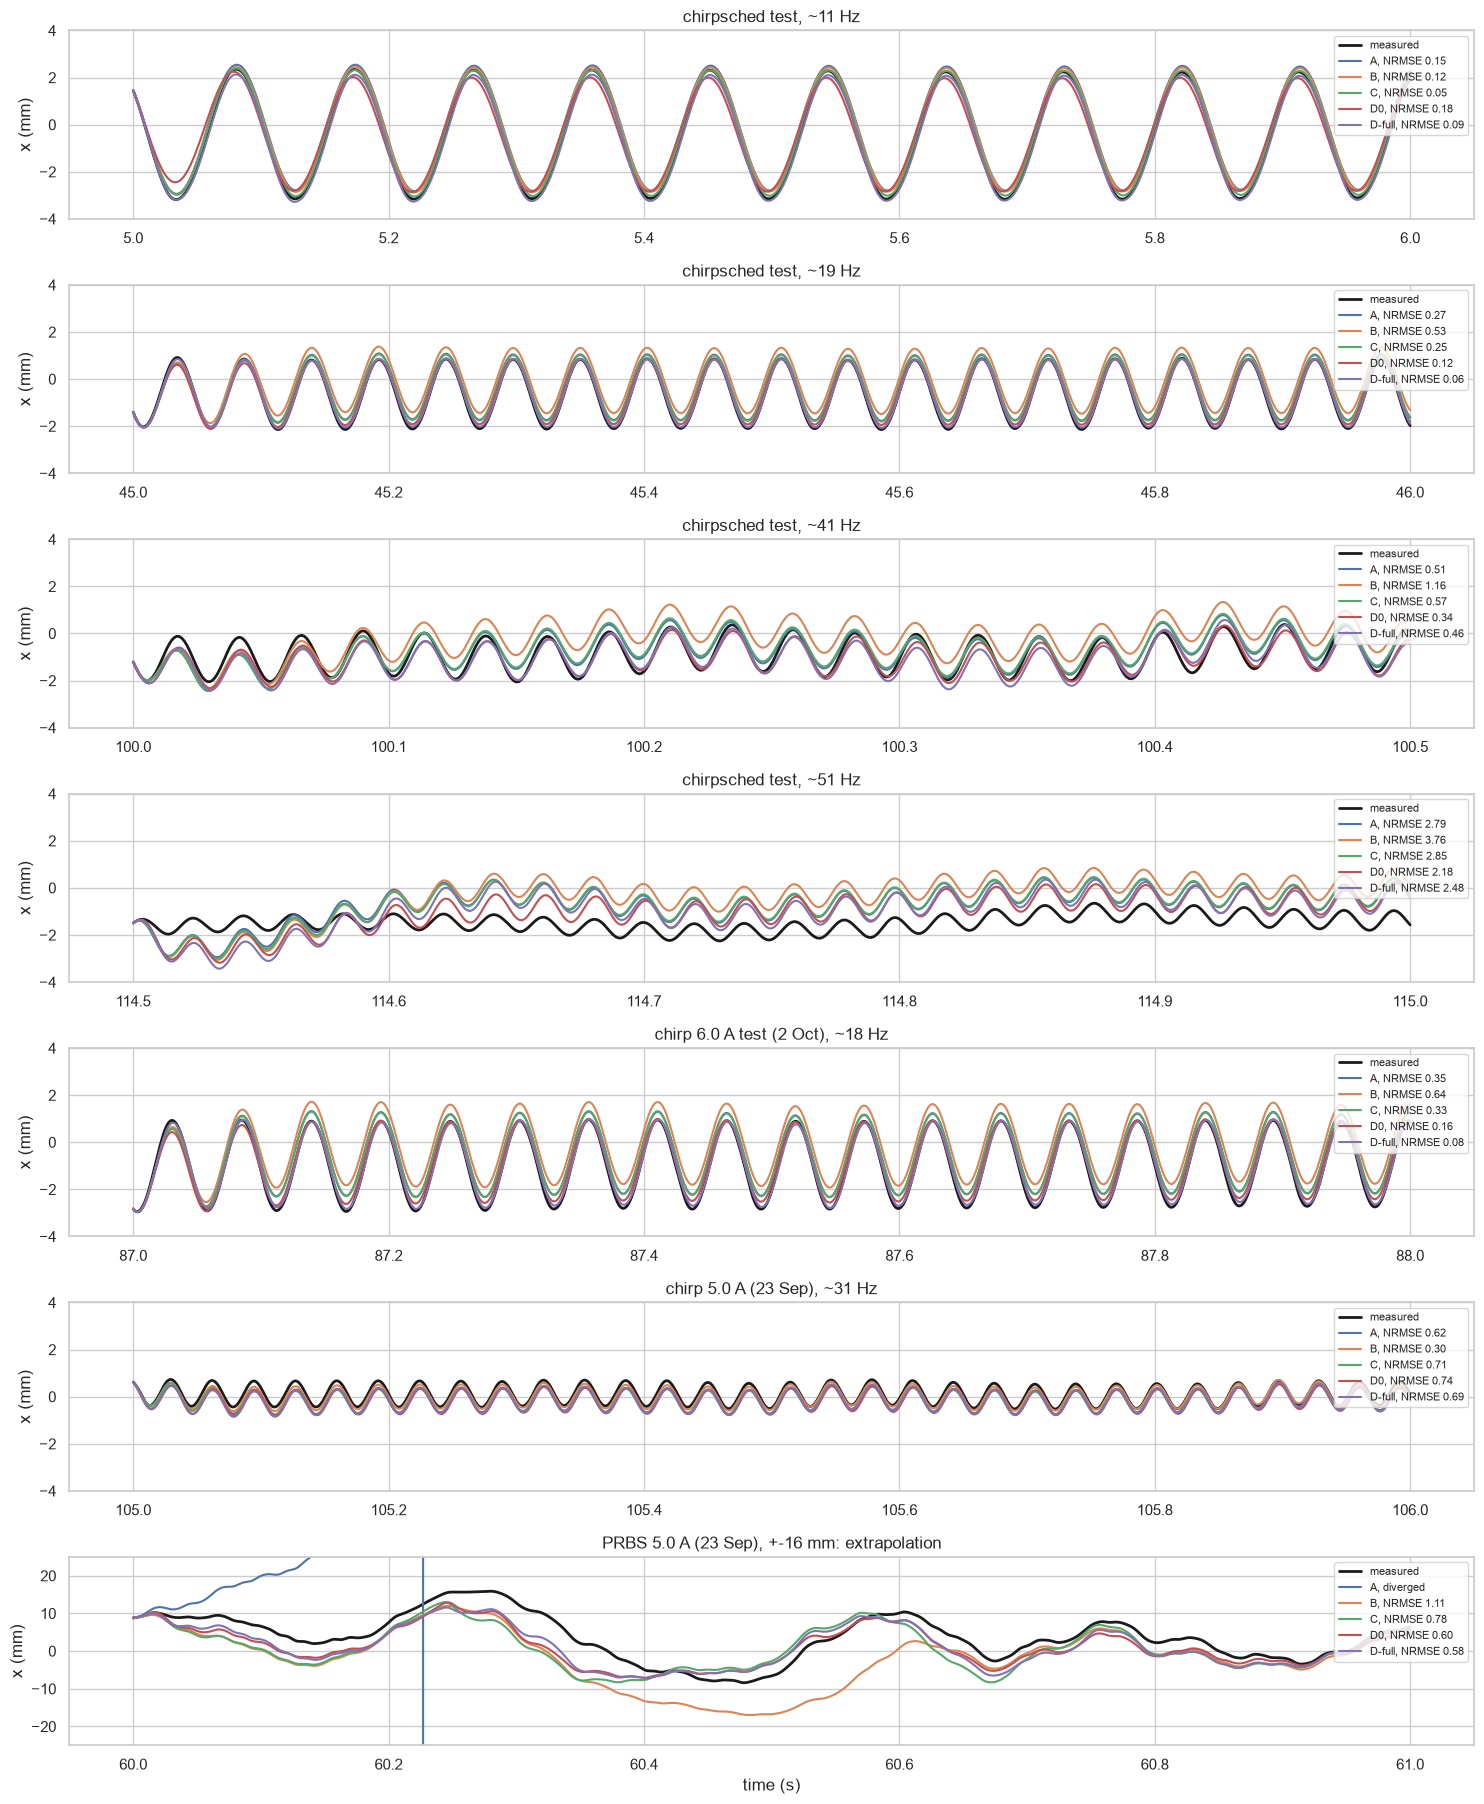

In [ ]:
MODELS = [("A", poly3, p_p3, rollout), ("B", poly3_ds, p_B, rollout), ("C", magnets, p_C, rollout),   # (name, force, parameters, rollout)
          ("D0", DV["D0"]["Fs"], DV["D0"]["p"], rollout_D), ("D-full", DV["D-full"]["Fs"], DV["D-full"]["p"], rollout_D)]
SEP = lambda name: load(next(Path("data").glob(f"voice_coil_log_{name}_*.csv")))   # September logs in data/
VAL = [  # (label, data, start s, length s); chirp frequency f0 (f1/f0)^(t/T), checked against the current's zero crossings
    ("chirpsched test, ~11 Hz", DATA["chirpsched"]["test"], 5.0, 1.0),       # 10.7-10.9 Hz
    ("chirpsched test, ~19 Hz", DATA["chirpsched"]["test"], 45.0, 1.0),      # 19.0-19.2 Hz
    ("chirpsched test, ~41 Hz", DATA["chirpsched"]["test"], 100.0, 0.5),     # 41.4-41.7 Hz
    ("chirpsched test, ~51 Hz", DATA["chirpsched"]["test"], 114.5, 0.5),     # 50.9-51.2 Hz
    ("chirp 6.0 A test (2 Oct), ~18 Hz", DATA["chirp"]["test"], 87.0, 1.0),  # 18.3-18.9 Hz
    ("chirp 5.0 A (23 Sep), ~31 Hz", SEP("chirp_5.0A"), 105.0, 1.0),         # 30.7-31.7 Hz (this chirp ends at 50 Hz)
    ("PRBS 5.0 A (23 Sep), +-16 mm: extrapolation", SEP("prbs"), 60.0, 1.0),
]
Y_LIM, Y_LIM_PRBS = 4.0, 25.0                           # mm, y range of the chirp rows and of the PRBS row
fig, ax = plt.subplots(len(VAL), 1, figsize=(15, 2.6 * len(VAL)))
for a_, (label, d, t0, T) in zip(ax, VAL):
    s, H = np.array([np.searchsorted(d["t"], t0)]), int(round(T / TS))
    t, xm = d["t"][s[0]:s[0] + H + 1], target(d, s, H)[0]
    sns.lineplot(x=t, y=xm * 1e3, ax=a_, color="k", lw=2, label="measured")
    for name, Fs, p, roll in MODELS:
        with np.errstate(all="ignore"):
            xp = roll(Fs, p, d, s, H)[0]
        nr = np.sqrt(np.mean((xp - xm) ** 2)) / np.std(xm)
        sns.lineplot(x=t, y=np.where(np.isfinite(xp), xp, np.nan) * 1e3, ax=a_, lw=1.5, label=f"{name}, NRMSE {nr:.2f}" if np.isfinite(nr) else f"{name}, diverged")
    lim = Y_LIM_PRBS if label.startswith("PRBS") else Y_LIM
    a_.set(title=label, ylabel="x (mm)", ylim=(-lim, lim))
    a_.legend(loc="upper right", fontsize=8)
ax[-1].set(xlabel="time (s)")
plt.tight_layout(); plt.show()

## Kalman filter with Method C, on the raw 2 kHz data

Extended Kalman filter (EKF) on the Method C model, state $z = [x, \dot{x}]$, input $i$, measurement $y = x$:

$$z_{k+1} = f_{\text{RK4}}(z_k, i_k) + w_k, \qquad y_k = x_k + e_k$$

**Real-time conditions.** The filter sees the signals as a controller would: the raw log at 2 kHz ($T_s$ = 0.5 ms), the commanded current and the laser position straight from the CSV. No low-pass, no 50/150 Hz notch, no `TAU`/`TAU_ACC` shift, no decimation. Only the model parameters come from the offline fit.

- Predict: one RK4 step of the model (the same `step` as the fits, at 0.5 ms); covariance with the Jacobian $F = I + A T_s + (A T_s)^2/2$ of the model linearised at the current state.
- Process noise $w$: white acceleration noise with std `SIG_A`, set to the Method C acceleration residual on its fit data. Measurement noise $e$: std `SIG_Y`, the raw laser std in the idle window ($t < 0$, actuator at rest; tuning knob). It is mostly 50/150 Hz mains pickup, so not white.
- The velocity is the filter's own causal estimate.

**Single-step prediction error** $y_k - \hat{x}_{k|k-1}$ (the innovation: measurement minus the prediction made before that measurement is used), on the fit run (**TRAIN**, blue) and on two runs the fit did not use (**TEST**, red); the first `T_SETTLE` s are left out while the filter converges.
- Figure 1: error against time, with ±2 predicted std. Printed: RMS, NRMSE, and innovation std / predicted std (1 when `SIG_A` and `SIG_Y` are consistent with the data).
- Figure 2: measured $y_k$ and the one-step prediction $\hat{x}_{k|k-1}$ against time, whole run and a `ZOOM_KF` s zoom mid-run.
- Figure 3: histogram of the error, with the normal density the filter predicts. A shifted or wider histogram on TEST than on TRAIN shows model error on new data.
- Figure 4: PSD of the error (Welch, 2 kHz), with the flat level of white noise at the predicted std. An optimal filter has white innovations; peaks show dynamics the model misses or coloured measurement noise (the 50/150 Hz mains lines).

SIG_A = 7.86 m/s^2 (Method C residual), SIG_Y = 0.0766 mm (raw laser, idle window)
[TRAIN] chirpsched train (fit data)  RMS 0.1180 mm, NRMSE 9.55e-02; innovation std / predicted std = 1.39
[TEST ] chirpsched test              RMS 0.1148 mm, NRMSE 9.16e-02; innovation std / predicted std = 1.35
[TEST ] chirp 6.0 A test (2 Oct)     RMS 1.3680 mm, NRMSE 1.29e-01; innovation std / predicted std = 16.20


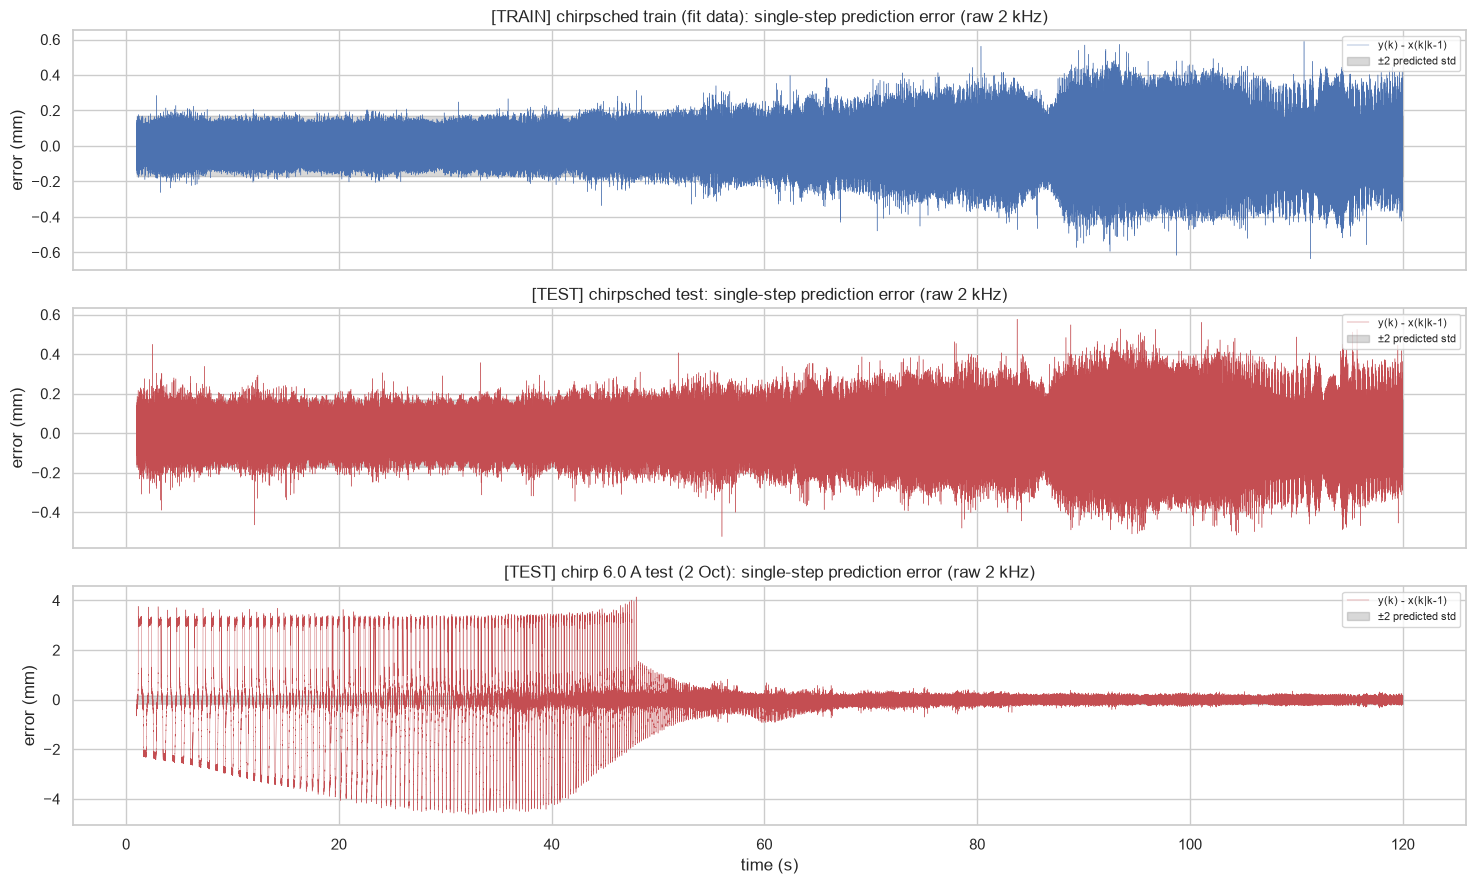

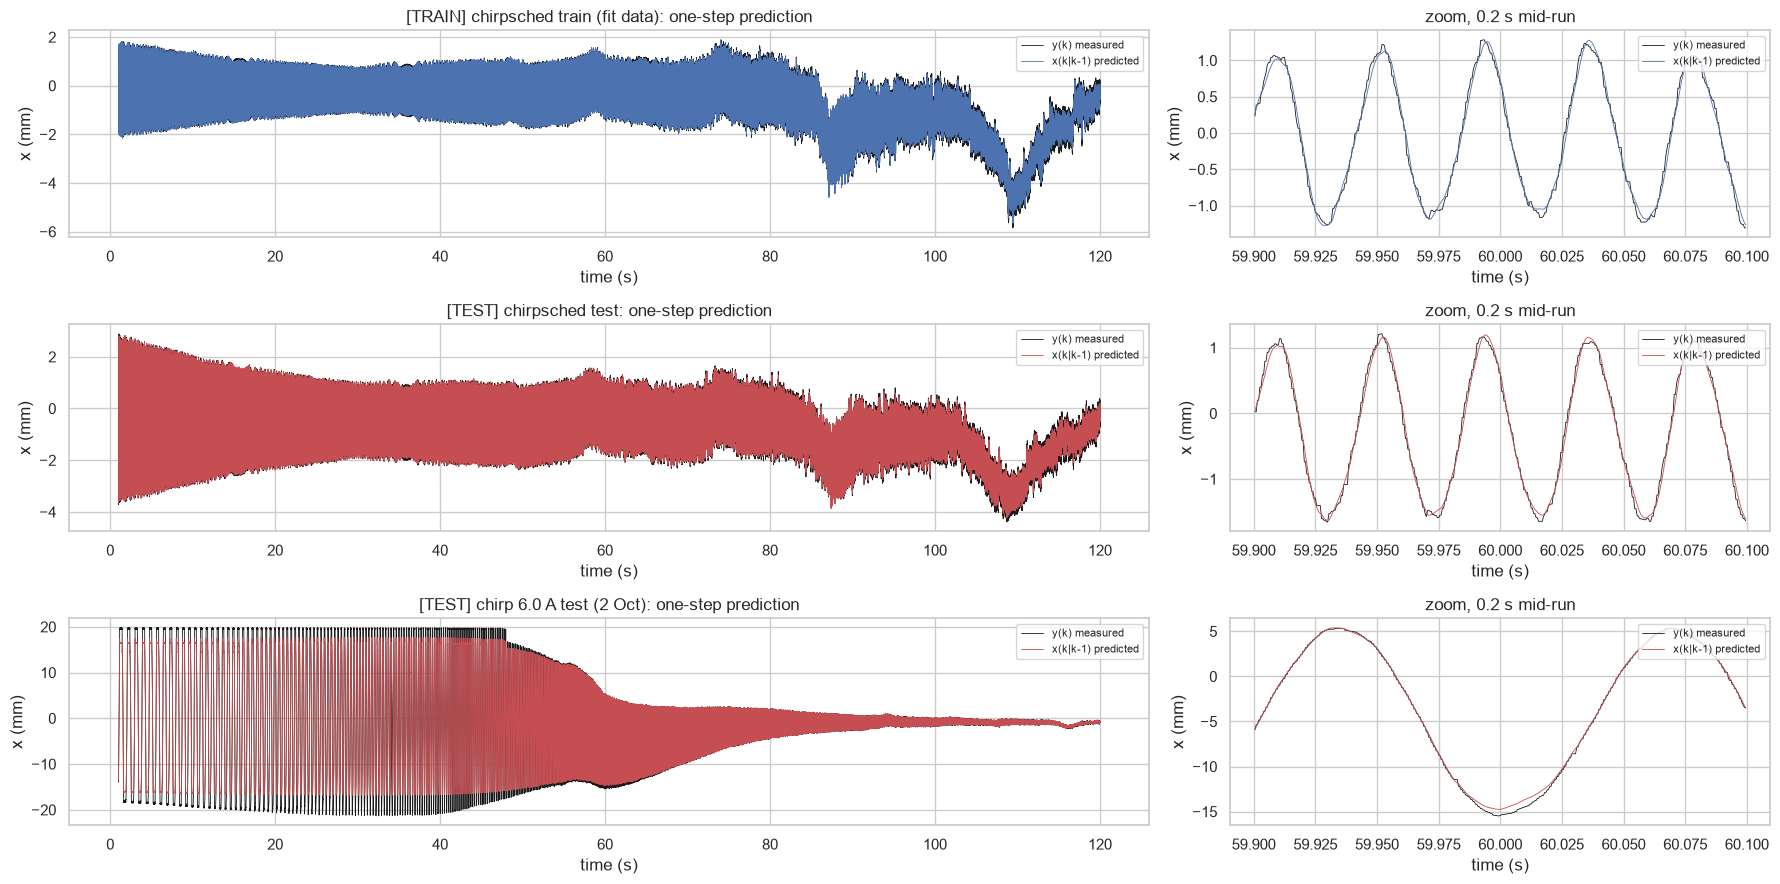

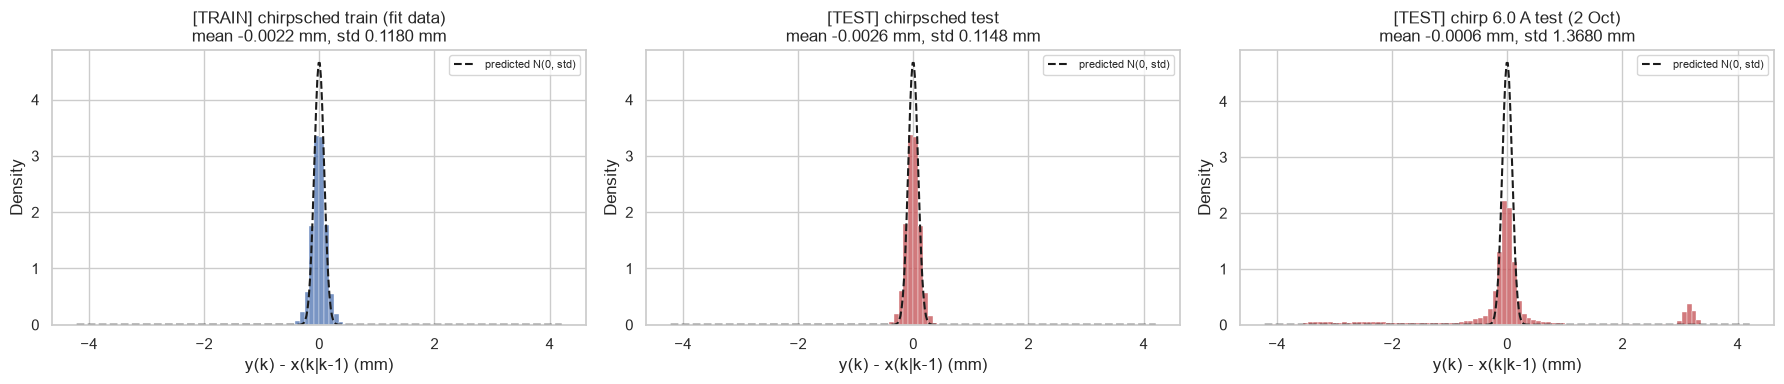

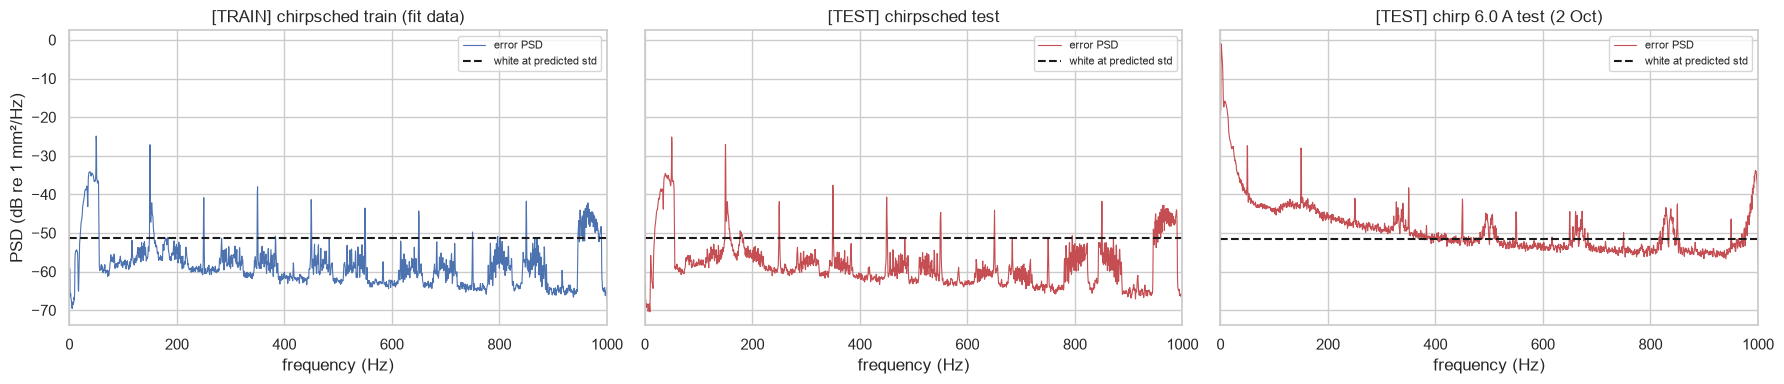

In [ ]:
T_SETTLE = 1.0                                          # s left out at the start while the filter converges
TS_RAW = 1 / FS_LOG                                     # s, the filter runs at the logged 2 kHz


def load_raw(path):
    "Raw 2 kHz log as a real-time filter sees it: commanded current and laser position, no low-pass, notch, TAU shift or decimation."
    raw = np.loadtxt(path, delimiter=",", skiprows=2)
    idle = raw[raw[:, 0] < 0.0, 11] * 1e-3              # t < 0: actuator at rest, so this is pure measurement noise
    raw = raw[raw[:, 0] >= 0.0]
    return dict(t=raw[:, 0], i=raw[:, 2], x=raw[:, 11] * 1e-3, sig_idle=np.std(idle))


RAW = {(exp, s): load_raw(next(Path("data", s).glob(f"voice_coil_log_{exp}_*.csv"))) for exp in ("chirpsched", "chirp") for s in ("train", "test")}
d, sel = DATA["chirpsched"]["train"], DATA["chirpsched"]["train"]["sweep"]
acc_C = lambda x, v, u: (p_C[0] * u - p_C[1] * v - magnets(x, u, p_C[2:])) / M
SIG_A = np.std(d["a"][sel] - acc_C(d["x"][sel], d["v"][sel], d["i"][sel]))   # m/s^2, process noise: Method C residual on its fit data
SIG_Y = RAW["chirpsched", "train"]["sig_idle"]          # m, measurement noise std: raw laser at rest (knob; mostly 50/150 Hz mains pickup, not white)
print(f"SIG_A = {SIG_A:.3g} m/s^2 (Method C residual), SIG_Y = {SIG_Y * 1e3:.4f} mm (raw laser, idle window)")


def ekf(Fs, p, d, sig_a, sig_y, ts=TS):
    "Extended Kalman filter at sample time ts, state [x, v], measurement x. Returns filtered x, v, one-step predicted x(k|k-1) and its innovation std."
    acc = lambda x, v, u: (p[0] * u - p[1] * v - Fs(x, u, p[2:])) / M
    q11, q12, q22, R = sig_a**2 * ts**4 / 4, sig_a**2 * ts**3 / 2, sig_a**2 * ts**2, sig_y**2   # white acceleration noise, discretized
    y, i = d["x"].tolist(), d["i"].tolist()             # python floats: the scalar loop runs several times faster
    n = len(y)
    xf, vf, xp, sp = (np.empty(n) for _ in range(4))
    x, v, p11, p12, p22 = y[0], 0.0, R, 0.0, 1e-4      # start at the first measurement, at rest, velocity std 1 cm/s
    for k in range(n):
        if k:   # predict: RK4 step of the model; covariance F P F' + Q with F = I + A Ts + (A Ts)^2 / 2
            u = i[k - 1]
            x, v = step(x, v, u, i[k] if FOH else u, acc, ts)
            a21, a22 = -(Fs(x + 1e-7, u, p[2:]) - Fs(x - 1e-7, u, p[2:])) / 2e-7 / M, -p[1] / M   # A = [[0, 1], [a21, a22]]
            f11, f12 = 1 + a21 * ts**2 / 2, ts + a22 * ts**2 / 2
            f21, f22 = a21 * ts + a21 * a22 * ts**2 / 2, 1 + a22 * ts + (a21 + a22**2) * ts**2 / 2
            g11, g12, g21, g22 = f11 * p11 + f12 * p12, f11 * p12 + f12 * p22, f21 * p11 + f22 * p12, f21 * p12 + f22 * p22   # F P
            p11, p12, p22 = g11 * f11 + g12 * f12 + q11, g11 * f21 + g12 * f22 + q12, g21 * f21 + g22 * f22 + q22
        xp[k], S = x, p11 + R
        sp[k] = np.sqrt(S)
        k1, k2, e = p11 / S, p12 / S, y[k] - x           # update with the measured position
        x, v = x + k1 * e, v + k2 * e
        p11, p12, p22 = p11 - k1 * p11, p12 - k1 * p12, p22 - k2 * p12
        xf[k], vf[k] = x, v
    return xf, vf, xp, sp


# self-check: on noise-free output of the model itself, the one-step prediction must converge to it
_d = DATA["chirpsched"]["test"]
_x = rollout(magnets, p_C, _d, np.array([0]), 3000)[0]
assert np.abs(ekf(magnets, p_C, dict(x=_x, i=_d["i"][:3001]), SIG_A, SIG_Y)[2] - _x)[1000:].max() < 1e-6

# single-step prediction error e = y(k) - x(k|k-1) on the raw fit run (TRAIN) and two raw runs the fit did not use (TEST)
rms = lambda e: np.sqrt(np.mean(e**2))
RUNS = [("TRAIN", "chirpsched train (fit data)", RAW["chirpsched", "train"]),
        ("TEST", "chirpsched test", RAW["chirpsched", "test"]),
        ("TEST", "chirp 6.0 A test (2 Oct)", RAW["chirp", "test"])]
ERR, PRED = [], []
fig, ax = plt.subplots(len(RUNS), 1, figsize=(15, 3 * len(RUNS)), sharex=True)
for a_, (split, label, d) in zip(ax, RUNS):
    xf, vf, xp, sp = ekf(magnets, p_C, d, SIG_A, SIG_Y, TS_RAW)
    band = d["t"] >= T_SETTLE
    e = (d["x"] - xp)[band]
    ERR.append((split, label, e, np.mean(sp[band])))
    PRED.append((split, label, d, xp))
    print(f"[{split:5s}] {label:28s} RMS {rms(e) * 1e3:.4f} mm, NRMSE {rms(e) / np.std(d['x'][band]):.2e}; "
          f"innovation std / predicted std = {np.std(e) / np.mean(sp[band]):.2f}")
    color = "C0" if split == "TRAIN" else "C3"
    sns.lineplot(x=d["t"][band], y=e * 1e3, ax=a_, lw=0.3, color=color, label="y(k) - x(k|k-1)")
    a_.fill_between(d["t"][band], -2e3 * sp[band], 2e3 * sp[band], color="0.5", alpha=0.3, label="±2 predicted std")
    a_.set(ylabel="error (mm)", title=f"[{split}] {label}: single-step prediction error (raw 2 kHz)")
    a_.legend(loc="upper right", fontsize=8)
ax[-1].set(xlabel="time (s)")
plt.tight_layout(); plt.show()

# time series: measured x(k) and the one-step prediction x(k|k-1); left the whole run, right a ZOOM_KF s window mid-run
ZOOM_KF = 0.2                                           # s, length of the zoom window
fig, ax = plt.subplots(len(PRED), 2, figsize=(18, 3 * len(PRED)), gridspec_kw=dict(width_ratios=(2, 1)))
for row, (split, label, d, xp) in zip(ax, PRED):
    t_mid = d["t"][len(d["t"]) // 2]
    for a_, m in [(row[0], d["t"] >= T_SETTLE), (row[1], np.abs(d["t"] - t_mid) <= ZOOM_KF / 2)]:
        sns.lineplot(x=d["t"][m], y=d["x"][m] * 1e3, ax=a_, lw=0.6, color="k", label="y(k) measured")
        sns.lineplot(x=d["t"][m], y=xp[m] * 1e3, ax=a_, lw=0.6, color="C0" if split == "TRAIN" else "C3", label="x(k|k-1) predicted")
        a_.set(xlabel="time (s)", ylabel="x (mm)")
        a_.legend(loc="upper right", fontsize=8)
    row[0].set(title=f"[{split}] {label}: one-step prediction")
    row[1].set(title=f"zoom, {ZOOM_KF} s mid-run")
plt.tight_layout(); plt.show()

# histogram of the single-step error, with the normal density the filter predicts (std = mean innovation std)
lim = max(np.percentile(np.abs(e), 99.5) for *_, e, _ in ERR) * 1e3
fig, ax = plt.subplots(1, len(ERR), figsize=(6 * len(ERR), 4), sharex=True)
for a_, (split, label, e, s) in zip(ax, ERR):
    sns.histplot(e * 1e3, ax=a_, stat="density", bins=np.linspace(-lim, lim, 101), color="C0" if split == "TRAIN" else "C3")
    g = np.linspace(-lim, lim, 400)
    a_.plot(g, np.exp(-0.5 * (g / (s * 1e3))**2) / (s * 1e3 * np.sqrt(2 * np.pi)), "k--", label="predicted N(0, std)")
    a_.set(xlabel="y(k) - x(k|k-1) (mm)", title=f"[{split}] {label}\nmean {e.mean() * 1e3:.4f} mm, std {e.std() * 1e3:.4f} mm")
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

# PSD of the single-step error (Welch, fs = 2 kHz). An optimal filter has white innovations: flat at 2 std^2 / fs (one-sided);
# peaks show structure the model misses (e.g. the 35.5 Hz laser-mount mode) or coloured measurement noise (50/150 Hz mains)
fig, ax = plt.subplots(1, len(ERR), figsize=(6 * len(ERR), 4), sharey=True)
for a_, (split, label, e, s) in zip(ax, ERR):
    f, P = signal.welch(e * 1e3, fs=FS_LOG, window="hann", nperseg=4096, noverlap=2048, detrend="constant", scaling="density")
    sns.lineplot(x=f, y=10 * np.log10(P + 1e-20), ax=a_, lw=0.8, color="C0" if split == "TRAIN" else "C3", label="error PSD")
    a_.axhline(10 * np.log10(2 * (s * 1e3)**2 * TS_RAW), color="k", ls="--", label="white at predicted std")
    a_.set(xlim=(0, FS_LOG / 2), xlabel="frequency (Hz)", ylabel="PSD (dB re 1 mm²/Hz)", title=f"[{split}] {label}")
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Sliding-mode control on the Method C plant (clean, no noise)

A first look at the nominal sliding-mode controller. The plant is the fitted Method C model itself. The continuous-time control law is evaluated every $T_s$ = 0.5 ms (2 kHz) and held over the step (ZOH), and the plant is integrated with the same RK4 `step` as the fits.

**Plant.** Method C written as $\ddot x = f(x,\dot x) + g(x)\,u$, with $u = i$:

$$f(x,\dot x) = -\frac{c}{m}\,\dot x - \frac{1}{m}\left(\frac{C_R}{(g_0 - x)^3} - \frac{C_L}{(g_0 + x)^3}\right), \qquad g(x) = \frac{\Gamma + \Gamma_1 x}{m}$$

**Error system.** For a reference $r(t)$, $z_1 = x - r$ and $z_2 = \dot z_1 = \dot x - \dot r$:

$$\dot z_1 = z_2, \qquad \dot z_2 = f(x,\dot x) + g(x)\,u - \ddot r$$

**Sliding surface.**

$$s = a\,z_1 + z_2, \qquad a > 0$$

On $s = 0$, $\dot z_1 = -a z_1$, so $z_1 \to 0$ with time constant $1/a$. The derivative along the trajectories is

$$\dot s = \frac{\partial s}{\partial z}\,\dot z = \begin{bmatrix} a & 1 \end{bmatrix}\begin{bmatrix} z_2 \ f + g u - \ddot r \end{bmatrix} = a\,z_2 + f(x,\dot x) + g(x)\,u - \ddot r$$

**Reaching law with boundary layer.**

$$\dot s = -\eta\,\theta(s), \qquad \eta > 0, \qquad \theta(s) = \operatorname{sat}\!\left(\frac{s}{\phi}\right) = \begin{cases} 1 & s > \phi \ s/\phi & |s| \le \phi \ -1 & s < -\phi \end{cases}$$

**Control law.** Set the two expressions for $\dot s$ equal and solve for $u$:

$$\boxed{\,u = \frac{1}{g(x)}\Big(\ddot r - a\,(\dot x - \dot r) - f(x,\dot x) - \eta\,\operatorname{sat}\!\big(s/\phi\big)\Big)\,}$$

Inside the layer, $\dot z_1 = -a z_1 + s$ with $|s| \le \phi$, so $|z_1| \le \phi / a$ in steady state.

**Reference.** A linear chirp from $F_0$ = 1 Hz to $F_1$ = 20 Hz over $T_\text{r}$ = 30 s, then 10 s at $F_1$. $A$ = 2 mm, and $k = (F_1 - F_0)/T_\text{r}$:

$$\varphi(t) = \begin{cases} 2\pi\left(F_0 t + \tfrac{k}{2} t^2\right) & t < T_\text{r} \ 2\pi\left(F_0 T_\text{r} + \tfrac{k}{2} T_\text{r}^2 + F_1 (t - T_\text{r})\right) & t \ge T_\text{r} \end{cases}, \qquad \dot\varphi = 2\pi f(t), \qquad \ddot\varphi = \begin{cases} 2\pi k & t < T_\text{r} \ 0 & t \ge T_\text{r} \end{cases}$$

$$r = A \sin\varphi, \qquad \dot r = A\,\dot\varphi \cos\varphi, \qquad \ddot r = A\left(\ddot\varphi \cos\varphi - \dot\varphi^2 \sin\varphi\right)$$

Starting at 1 Hz rather than 0 keeps $s(0) = -\dot r(0) \approx -0.013$ m/s inside the layer.

**Parameters.**
- $a = 3\omega = 3 \cdot 2\pi \cdot 20 \approx 377$ s⁻¹, using the final frequency. It is fixed for the whole run.
- $\phi = a \cdot 0.05$ mm $\approx 0.019$ m/s, so $|z_1| \le \phi / a = 0.05$ mm inside the layer.
- $\eta = 2\,\sigma_a \approx 16$ m/s², where $\sigma_a$ = `SIG_A` is the Method C acceleration residual on its fit data (Kalman filter cell). Why this value:
  - $\eta$ must be larger than the model error as it appears in $\dot s$, which has units of acceleration. $\sigma_a$ is that error as measured, and $2\sigma_a$ covers about 95 % of it. The clean plant here has no model error, but the value is already right for the real actuator.
  - Inside the layer, $\dot s = -(\eta/\phi)\,s$, a pole at $\lambda = \eta/\phi \approx 830$ rad/s ≈ 2.2 $a$. The $s$-loop is faster than the $z_1$-loop, so the two do not interact.
  - Sampling: $\lambda T_s \approx 0.42$ and $a T_s \approx 0.19$, both well below 1. The sampled boundary-layer dynamics stay monotone, so the continuous-time law can be used at 2 kHz without a discrete-time redesign.

**Corrections to the handwritten derivation.**
1. $\dot s = a z_2 + (f + g u - \ddot r)$, not $(a+1)(f + g u - \ddot r)$. As a result, the $1/(a+1)$ factor on $\eta\theta$ goes away and the term $-a z_2$ appears.
2. $\dot z_2$ contains $\ddot r$. For a sine this is $-A\omega^2 \sin\omega t$, not $A\omega\cos\omega t$ (which is $\dot r$).
3. $f$ depends on $\dot x$ through the damping term.

**Check.** The cell also runs with $\eta = 0$, which leaves only the model cancellation. On the clean plant this alone is not exact, because the ZOH holds $u$ over the step, and with $\eta = 0$ nothing pulls $s$ back. The sampling error accumulates to about 0.2 mm, against about 0.003 mm with $\eta$. The dashed lines at ±6 A mark the current used in the experiments. $u$ is not saturated here, and the 20 Hz, 2 mm reference needs about 8 A.

eta = 15.72 m/s^2: max |x - r| = 0.0062 mm (hold 0.0026 mm), max |s/phi| = 0.667, max |u| = 8.26 A, RMS u (hold) = 5.64 A
eta =  0.00 m/s^2: max |x - r| = 0.2122 mm (hold 0.2122 mm), max |s/phi| = 4.265, max |u| = 8.33 A, RMS u (hold) = 5.67 A


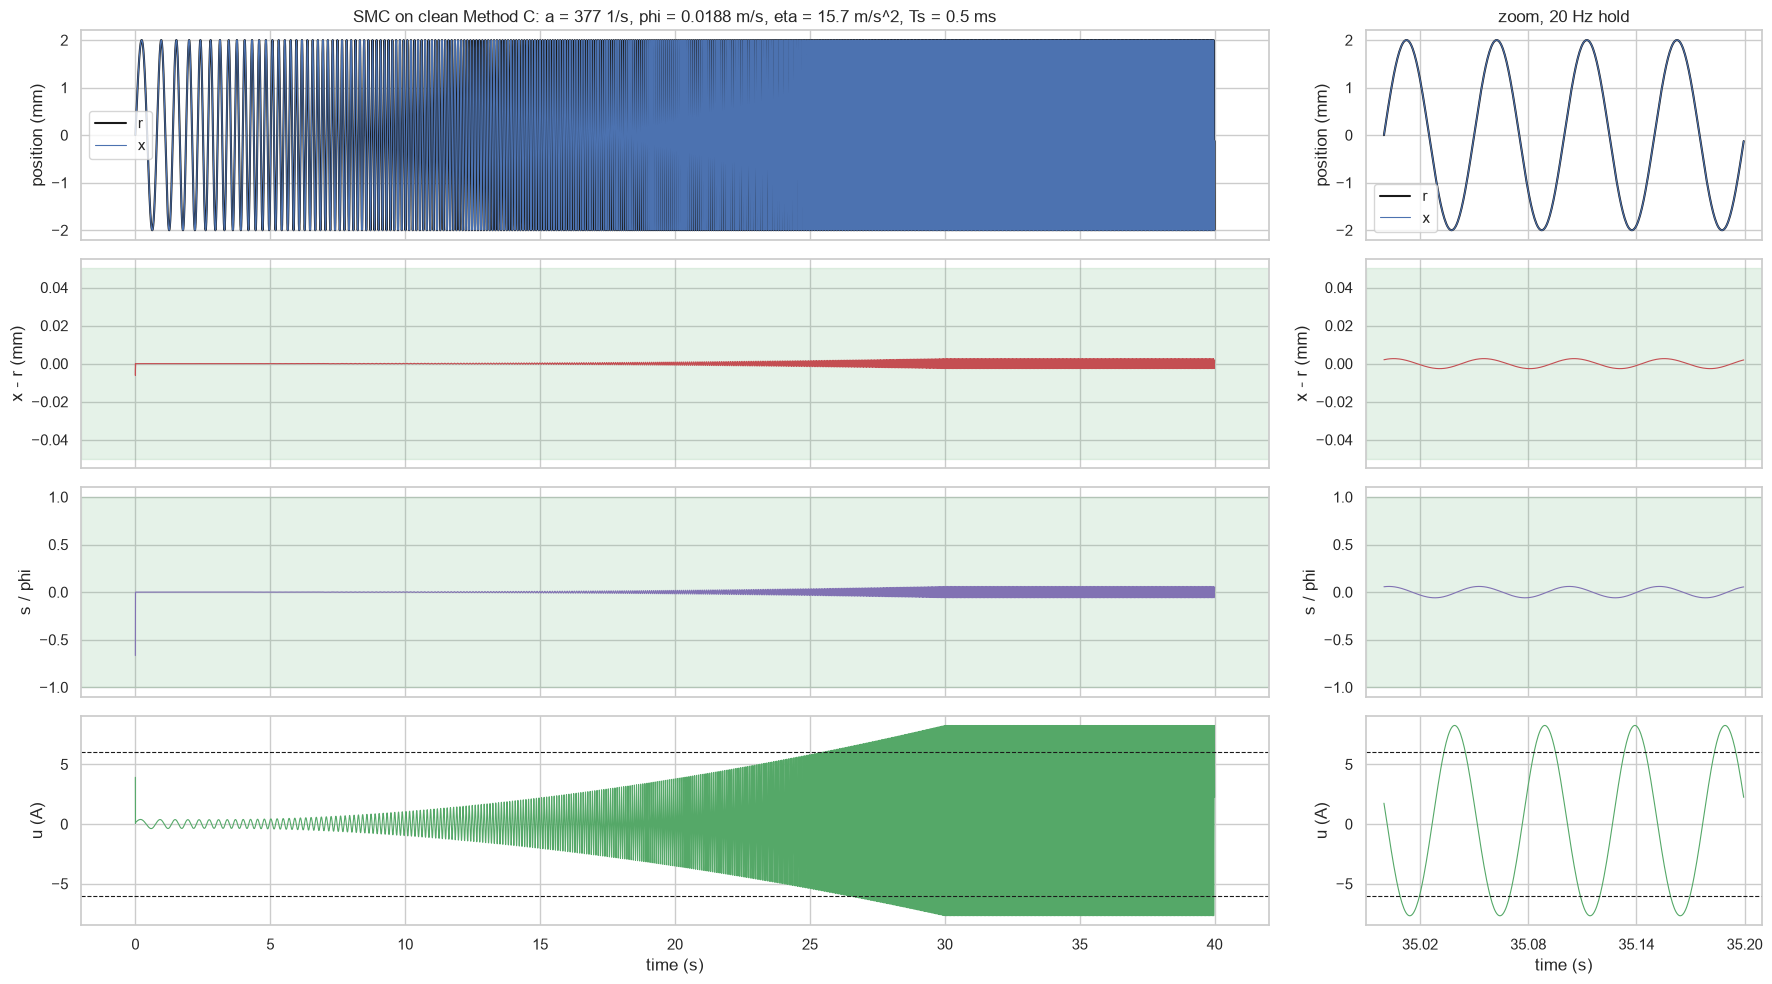

In [ ]:
A_REF, F0, F1, T_RAMP, T_HOLD = 2e-3, 1.0, 20.0, 30.0, 10.0   # m, Hz, Hz, s, s: chirp F0 -> F1 in T_RAMP, then T_HOLD at F1
TS_C = 1 / FS_LOG                                             # s, controller and plant step: 2 kHz
A_SMC = 3 * 2 * np.pi * F1                                    # 1/s, surface slope a = 3*omega at the FINAL frequency
PHI = A_SMC * 0.05e-3                                         # m/s, boundary layer: |z1| <= PHI / a = 0.05 mm inside it
ETA = 2 * SIG_A                                               # m/s^2, reaching gain: 2x the Method C acceleration residual (knob)
I_LIM = 6.0                                                   # A, reference line only: the current used in the experiments, u is not saturated

# chirp reference, analytic: phase ph, its rate dph = 2 pi f(t) and acceleration ddph
t = np.arange(0.0, T_RAMP + T_HOLD, TS_C)
kf, ramp = (F1 - F0) / T_RAMP, t < T_RAMP
ph = 2 * np.pi * np.where(ramp, F0 * t + kf * t**2 / 2, F0 * T_RAMP + kf * T_RAMP**2 / 2 + F1 * (t - T_RAMP))
dph, ddph = 2 * np.pi * np.where(ramp, F0 + kf * t, F1), np.where(ramp, 2 * np.pi * kf, 0.0)
r, rd, rdd = A_REF * np.sin(ph), A_REF * dph * np.cos(ph), A_REF * (ddph * np.cos(ph) - dph**2 * np.sin(ph))


def smc(eta):
    "Sliding-mode loop on the clean Method C plant, continuous law with ZOH at TS_C. Returns x, s / PHI and u."
    n = len(t)
    xs, ss, us = np.empty(n), np.empty(n), np.empty(n)
    x, v = 0.0, 0.0                                     # start at rest in the centre
    for k in range(n):
        z1, z2 = x - r[k], v - rd[k]
        s = A_SMC * z1 + z2
        u = (rdd[k] - A_SMC * z2 - acc_C(x, v, 0.0) - eta * min(max(s / PHI, -1.0), 1.0)) / ((p_C[0] + p_C[2] * x) / M)   # f = acc_C(x, v, 0), g = (Gamma + Gamma1 x) / m
        xs[k], ss[k], us[k] = x, s / PHI, u
        x, v = step(x, v, u, u, acc_C, TS_C)            # plant: RK4 of Method C, input held over the step
    return xs, ss, us


hold = t >= T_RAMP
for eta in (ETA, 0.0):                                  # eta = 0: feedforward / cancellation only
    xs, ss, us = smc(eta)
    print(f"eta = {eta:5.2f} m/s^2: max |x - r| = {np.abs(xs - r).max() * 1e3:.4f} mm (hold {np.abs(xs - r)[hold].max() * 1e3:.4f} mm), "
          f"max |s/phi| = {np.abs(ss).max():.3f}, max |u| = {np.abs(us).max():.2f} A, RMS u (hold) = {np.sqrt(np.mean(us[hold]**2)):.2f} A")
xs, ss, us = smc(ETA)

fig, ax = plt.subplots(4, 2, figsize=(18, 10), sharex="col", gridspec_kw=dict(width_ratios=[3, 1]))
zoom = (t >= T_RAMP + T_HOLD / 2) & (t < T_RAMP + T_HOLD / 2 + 0.2)   # 0.2 s mid-hold, 20 Hz
for col, m in enumerate((slice(None), zoom)):
    sns.lineplot(x=t[m], y=r[m] * 1e3, ax=ax[0, col], lw=1.5, color="k", label="r")
    sns.lineplot(x=t[m], y=xs[m] * 1e3, ax=ax[0, col], lw=0.8, color="C0", label="x").set(ylabel="position (mm)")
    sns.lineplot(x=t[m], y=(xs - r)[m] * 1e3, ax=ax[1, col], lw=0.8, color="C3").set(ylabel="x - r (mm)")
    ax[1, col].axhspan(-PHI / A_SMC * 1e3, PHI / A_SMC * 1e3, color="C2", alpha=0.15)   # boundary-layer bound phi / a
    sns.lineplot(x=t[m], y=ss[m], ax=ax[2, col], lw=0.8, color="C4").set(ylabel="s / phi")
    ax[2, col].axhspan(-1, 1, color="C2", alpha=0.15)
    sns.lineplot(x=t[m], y=us[m], ax=ax[3, col], lw=0.8, color="C2").set(xlabel="time (s)", ylabel="u (A)")
    for lim in (-I_LIM, I_LIM):
        ax[3, col].axhline(lim, color="k", ls="--", lw=0.8)
ax[0, 0].set(title=f"SMC on clean Method C: a = {A_SMC:.0f} 1/s, phi = {PHI:.4f} m/s, eta = {ETA:.1f} m/s^2, Ts = {TS_C * 1e3:.1f} ms")
ax[0, 1].set(title="zoom, 20 Hz hold"); ax[3, 1].xaxis.set_major_locator(plt.MaxNLocator(4))
plt.tight_layout(); plt.show()